In [2]:
import pandas as pd
import numpy as np
import warnings
import json
from pathlib import Path

warnings.filterwarnings('ignore')

UPLOAD_DIR = Path('.')
OUT_DIR = Path('./checkpoints')
MAP_DIR = Path('./anonymization_maps')
OUT_DIR.mkdir(exist_ok=True)
MAP_DIR.mkdir(exist_ok=True)

BBM_FILES = {
    2023: UPLOAD_DIR / 'BBM AAB 2023.xlsx',
    2024: UPLOAD_DIR / 'BBM AAB 2024.xlsx',
    2025: UPLOAD_DIR / 'BBM AAB 2025.xlsx',
}
CONTAINER_FILES = {
    2023: UPLOAD_DIR / 'Container 2023.xlsx',
    2024: UPLOAD_DIR / 'Container 2024.xlsx',
    2025: UPLOAD_DIR / 'Container 2025.xlsx',
}
COST_FILE = UPLOAD_DIR / 'cost & bbm 2022 sd 2025 HP & Type.xlsx'
RAINFALL_FILE = UPLOAD_DIR / 'Curah Hujan 2023-2025.xlsx'

TRAIN_END = pd.Period('2024-12', freq='M')
TEST_START = pd.Period('2025-01', freq='M')

In [3]:
def scan_bbm_unit_names(bbm_files):
    units = set()
    for yr, path in bbm_files.items():
        xls = pd.ExcelFile(path)
        for sh in xls.sheet_names:
            df = pd.read_excel(path, sheet_name=sh, header=[0, 1, 2], nrows=1)
            if df.empty:
                continue
            level0 = df.columns.get_level_values(0)
            for l0 in set(level0):
                if l0 == 'EQUIP NAME':
                    continue
                subcols = set(df.columns[level0 == l0].get_level_values(2))
                if 'HM' in subcols and 'LITER' in subcols:
                    units.add(l0)
    return units

def scan_container_branch_codes(container_files):
    branches = set()
    for yr, path in container_files.items():
        df = pd.read_excel(path, sheet_name=0, header=None)
        col0 = df.iloc[:, 0]
        starts = col0[col0 == 'CURRSTATE'].index.tolist()
        for i, s in enumerate(starts):
            end = starts[i + 1] if i + 1 < len(starts) else len(df)
            data_start = s + 9
            block_col0 = df.iloc[data_start:end, 0]
            gt_idx = block_col0[block_col0 == 'Grand Total'].index
            data_end = gt_idx[0] if len(gt_idx) > 0 else end
            branches.update(df.iloc[data_start:data_end, 0].dropna().unique().tolist())
    return branches

def scan_cost_file_names_and_lokasi(cost_file):
    df = pd.read_excel(cost_file, sheet_name='Sheet2', header=1)
    names = set(df['NAMA ALAT BERAT'].dropna().unique().tolist())
    lokasi = set(df['DES 2025'].dropna().unique().tolist())
    return names, lokasi

print('Scanning BBM AAB unit names...')
bbm_units = scan_bbm_unit_names(BBM_FILES)
print('Scanning Container branch codes...')
branch_codes = scan_container_branch_codes(CONTAINER_FILES)
print('Scanning cost&bbm file...')
cost_names, cost_lokasi = scan_cost_file_names_and_lokasi(COST_FILE)

all_unit_names = sorted(bbm_units | cost_names)
unit_map = {name: f'UNIT_{i+1:04d}' for i, name in enumerate(all_unit_names)}

branch_map = {name: f'BRANCH_{i+1:03d}' for i, name in enumerate(sorted(branch_codes))}
lokasi_map = {name: f'LOC_{i+1:03d}' for i, name in enumerate(sorted(cost_lokasi))}

print(f'Total unit: {len(unit_map)} | branch cabang: {len(branch_map)} | lokasi: {len(lokasi_map)}')

with open(MAP_DIR / 'unit_map.json', 'w') as f:
    json.dump(unit_map, f, indent=2, ensure_ascii=False)
with open(MAP_DIR / 'branch_map.json', 'w') as f:
    json.dump(branch_map, f, indent=2, ensure_ascii=False)
with open(MAP_DIR / 'lokasi_map.json', 'w') as f:
    json.dump(lokasi_map, f, indent=2, ensure_ascii=False)

Scanning BBM AAB unit names...
Scanning Container branch codes...
Scanning cost&bbm file...
Total unit: 355 | branch cabang: 49 | lokasi: 35


In [4]:
def process_bbm_sheet(path, sheet, unit_map):
    df = pd.read_excel(path, sheet_name=sheet, header=[0, 1, 2])
    if df.empty or df.shape[1] == 0:
        return None

    cols = df.columns
    level0 = cols.get_level_values(0)

    tgl_col = next((c for c in cols if c[2] == 'TANGGAL'), None)
    if tgl_col is None:
        return None

    unit_cols = []
    for l0 in set(level0):
        if l0 == 'EQUIP NAME':
            continue
        subcols = set(cols[level0 == l0].get_level_values(2))
        if 'HM' in subcols and 'LITER' in subcols:
            for c in cols[level0 == l0]:
                if c[2] in ('HM', 'LITER'):
                    unit_cols.append(c)

    if not unit_cols:
        return None

    sub = df[[tgl_col] + unit_cols].copy()
    sub.columns = pd.MultiIndex.from_tuples([('__TANGGAL__', '', '')] + list(sub.columns[1:]))

    tgl_raw = sub[('__TANGGAL__', '', '')].astype(str)
    sub = sub[~tgl_raw.isin(['AVG', 'TOTAL LTR/UTL', 'nan'])]

    sub = sub.set_index(('__TANGGAL__', '', ''))
    sub.index.name = 'TANGGAL'
    sub.columns = pd.MultiIndex.from_tuples([(c[0], c[2]) for c in sub.columns])

    long_df = sub.stack(level=0, future_stack=True).reset_index()
    long_df = long_df.rename(columns={'level_1': 'EQUIP NAME'})
    long_df['EQUIP NAME'] = long_df['EQUIP NAME'].map(unit_map)
    return long_df


frames = []
for yr, path in BBM_FILES.items():
    xls = pd.ExcelFile(path)
    for sh in xls.sheet_names:
        r = process_bbm_sheet(path, sh, unit_map)
        if r is not None:
            frames.append(r)

raw_bbm = pd.concat(frames, ignore_index=True)
print('raw_bbm shape:', raw_bbm.shape)
raw_bbm.head()

raw_bbm shape: (333643, 4)


,TANGGAL,EQUIP NAME,HM,LITER
0,01-01-2023,UNIT_0312,22673.0,200.0
1,01-01-2023,UNIT_0016,0.0,0.0
2,01-01-2023,UNIT_0199,15906.0,0.0
3,01-01-2023,UNIT_0028,7936.0,0.0
4,01-01-2023,UNIT_0134,19249.0,0.0


In [5]:
print(raw_bbm['EQUIP NAME'].nunique(), 'unit unik')
print(raw_bbm.dtypes)

306 unit unik
TANGGAL        object
EQUIP NAME     object
HM            float64
LITER         float64
dtype: object


In [6]:
raw_bbm['TANGGAL'] = pd.to_datetime(raw_bbm['TANGGAL'], format='%d-%m-%Y', errors='coerce')
raw_bbm = raw_bbm.dropna(subset=['TANGGAL'])
print('shape setelah date clean:', raw_bbm.shape)

shape setelah date clean: (333643, 4)


In [7]:
raw_bbm['HM_Clean'] = pd.to_numeric(raw_bbm['HM'], errors='coerce')
raw_bbm['HM_Clean'] = raw_bbm['HM_Clean'].replace(0, np.nan)
raw_bbm['HM_Clean'] = raw_bbm.groupby('EQUIP NAME')['HM_Clean'].ffill()
raw_bbm['HM_Clean'] = raw_bbm['HM_Clean'].fillna(0)

raw_bbm['DELTA_HM'] = raw_bbm.groupby('EQUIP NAME')['HM_Clean'].diff().fillna(0)
raw_bbm.loc[raw_bbm['DELTA_HM'] < 0, 'DELTA_HM'] = 0        # reset sensor/salah catat -> 0
raw_bbm.loc[raw_bbm['DELTA_HM'] > 24, 'DELTA_HM'] = 24       # FIX (saran dosen): >24 jam/hari -> cap ke 24, bukan buang ke 0

raw_bbm.to_csv(OUT_DIR / '01_daily_delta_hm.csv', index=False)
raw_bbm[['EQUIP NAME','TANGGAL','HM_Clean','DELTA_HM']].head()

,EQUIP NAME,TANGGAL,HM_Clean,DELTA_HM
0,UNIT_0312,2023-01-01,22673.0,0.0
1,UNIT_0016,2023-01-01,0.0,0.0
2,UNIT_0199,2023-01-01,15906.0,0.0
3,UNIT_0028,2023-01-01,7936.0,0.0
4,UNIT_0134,2023-01-01,19249.0,0.0


In [8]:
raw_bbm['TAHUN_BULAN'] = raw_bbm['TANGGAL'].dt.to_period('M')
monthly_hm = (raw_bbm.groupby(['EQUIP NAME', 'TAHUN_BULAN'])['DELTA_HM']
              .sum().round(1).reset_index().rename(columns={'DELTA_HM': 'UTILITAS'}))

monthly_hm.to_csv(OUT_DIR / '02_monthly_utilitas.csv', index=False)
print(monthly_hm.shape, '| range:', monthly_hm['TAHUN_BULAN'].min(), '-', monthly_hm['TAHUN_BULAN'].max())
monthly_hm.head()

(10959, 3) | range: 2023-01 - 2025-12


,EQUIP NAME,TAHUN_BULAN,UTILITAS
0,UNIT_0001,2023-01,0.0
1,UNIT_0001,2023-02,0.0
2,UNIT_0001,2023-03,0.0
3,UNIT_0001,2023-04,0.0
4,UNIT_0001,2023-05,0.0


In [9]:
MONTH_MAP = {'Jan':1,'Feb':2,'Mar':3,'Apr':4,'May':5,'Jun':6,
             'Jul':7,'Aug':8,'Sep':9,'Oct':10,'Nov':11,'Dec':12}

TARGET_CURRSTATE = {'FXD', 'FAC', 'STR', 'MAS', 'MTB', 'FOB', 'MXD', 'MOB'}

PREFERRED_PREV = {
    'FXD': 'All', 'FAC': 'All', 'STR': 'All', 'MAS': 'All',
    'MTB': 'All', 'FOB': 'All', 'MXD': 'All', 'MOB': 'MTL',
}

VALID_CONTAINER_TYPES = {
    '10 CO', '10 DC', '20 CO', '20 DC', '20 FT', '20 HC', '20 IT', '20 OT', '20 RF', '20 RH', '20 RM',
    '21 DC', '40 CO', '40 DC', '40 FT', '40 HC', '40 IT', '40 OT', '40 RF', '40 RH', '40 RM', '41 DC', '45 HC',
}

def parse_container_file(path, branch_map, target_currstate=TARGET_CURRSTATE, preferred_prev=PREFERRED_PREV):
    df = pd.read_excel(path, sheet_name=0, header=None)
    col0 = df.iloc[:, 0]
    starts = col0[col0 == 'CURRSTATE'].index.tolist()

    monthly_totals = {m: 0.0 for m in range(1, 13)}
    branch_rows_log = []
    blocks_used = []

    for i, s in enumerate(starts):
        curr = df.iloc[s, 1]
        prev = df.iloc[s + 1, 1]
        if curr not in target_currstate or prev != preferred_prev.get(curr):
            continue
        blocks_used.append((curr, prev))

        end = starts[i + 1] if i + 1 < len(starts) else len(df)
        coc_row = df.iloc[s + 6, :].copy()
        month_row = df.iloc[s + 7, :].copy()
        type_row = df.iloc[s + 8, :]
        coc_row.iloc[1:] = coc_row.iloc[1:].ffill()
        month_row.iloc[1:] = month_row.iloc[1:].ffill()

        data_start = s + 9
        block_col0 = df.iloc[data_start:end, 0]
        gt_idx = block_col0[block_col0 == 'Grand Total'].index
        data_end = gt_idx[0] if len(gt_idx) > 0 else end
        branch_rows = df.iloc[data_start:data_end]

        for col_idx in range(1, df.shape[1]):
            mon = month_row.iloc[col_idx]
            typ = type_row.iloc[col_idx]
            if pd.isna(mon) or mon not in MONTH_MAP:
                continue
            if typ not in VALID_CONTAINER_TYPES:
                continue
            vals = pd.to_numeric(branch_rows.iloc[:, col_idx], errors='coerce').fillna(0)
            monthly_totals[MONTH_MAP[mon]] += vals.sum()

            for r_idx in range(len(branch_rows)):
                branch_raw = branch_rows.iloc[r_idx, 0]
                if pd.isna(branch_raw):
                    continue
                v = vals.iloc[r_idx]
                if v != 0:
                    branch_rows_log.append({
                        'CABANG': branch_map.get(branch_raw, branch_raw),
                        'CURRSTATE': curr, 'BULAN': MONTH_MAP[mon],
                        'TIPE_CONTAINER': typ, 'VOLUME': v,
                    })

    return monthly_totals, pd.DataFrame(branch_rows_log), blocks_used

container_monthly_frames = []
container_branch_checkpoints = []
for yr, path in CONTAINER_FILES.items():
    totals, branch_df, used = parse_container_file(path, branch_map)
    print(yr, 'blok dipakai:', used, '| total tahun:', sum(totals.values()))
    for m, v in totals.items():
        container_monthly_frames.append({'TAHUN_BULAN': pd.Period(f'{yr}-{m:02d}', freq='M'), 'VOLUME_CONTAINER': v})
    branch_df['TAHUN'] = yr
    container_branch_checkpoints.append(branch_df)

monthly_container = pd.DataFrame(container_monthly_frames).sort_values('TAHUN_BULAN').reset_index(drop=True)
container_branch_detail = pd.concat(container_branch_checkpoints, ignore_index=True)

monthly_container.to_csv(OUT_DIR / '03a_monthly_container.csv', index=False)
container_branch_detail.to_csv(OUT_DIR / '03a_container_per_cabang_detail.csv', index=False)
monthly_container

2023 blok dipakai: [('FXD', 'All'), ('FAC', 'All'), ('STR', 'All'), ('MAS', 'All'), ('MTB', 'All'), ('FOB', 'All'), ('MXD', 'All'), ('MOB', 'MTL')] | total tahun: 4330703.0
2024 blok dipakai: [('FXD', 'All'), ('FAC', 'All'), ('STR', 'All'), ('MAS', 'All'), ('MTB', 'All'), ('FOB', 'All'), ('MXD', 'All'), ('MOB', 'MTL')] | total tahun: 4323469.0
2025 blok dipakai: [('FXD', 'All'), ('FAC', 'All'), ('STR', 'All'), ('MAS', 'All'), ('MTB', 'All'), ('FOB', 'All'), ('MXD', 'All'), ('MOB', 'MTL')] | total tahun: 4012779.0


,TAHUN_BULAN,VOLUME_CONTAINER
0,2023-01,368115.0
1,2023-02,355535.0
2,2023-03,350609.0
3,2023-04,296614.0
4,2023-05,365756.0
5,2023-06,347347.0
6,2023-07,370061.0
7,2023-08,371458.0
8,2023-09,372757.0
9,2023-10,396370.0


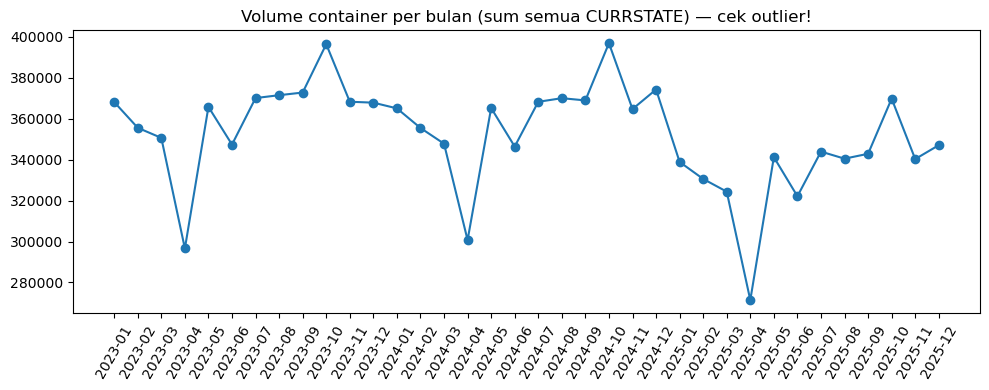

       VOLUME_CONTAINER
count         36.000000
mean      351859.750000
std        25862.723744
min       271398.000000
25%       341021.000000
50%       355495.000000
75%       368425.750000
max       396862.000000


In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(monthly_container['TAHUN_BULAN'].astype(str), monthly_container['VOLUME_CONTAINER'], marker='o')
ax.set_title('Volume container per bulan (sum semua CURRSTATE) — cek outlier!')
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

print(monthly_container.describe())

In [11]:
rain = pd.read_excel(RAINFALL_FILE, header=3)
rain = rain.rename(columns={'precipitation_sum (mm)': 'precipitation_sum'})
rain['time'] = pd.to_datetime(rain['time'])
rain = rain.set_index('time')

monthly_rain = rain['precipitation_sum'].resample('ME').sum().round(1).reset_index()

monthly_rain['TAHUN_BULAN'] = monthly_rain['time'].dt.to_period('M')
monthly_rain = monthly_rain[['TAHUN_BULAN', 'precipitation_sum']].rename(columns={'precipitation_sum': 'CURAH_HUJAN'})

monthly_full = monthly_hm.merge(monthly_rain, on='TAHUN_BULAN', how='left')
monthly_full = monthly_full.merge(monthly_container, on='TAHUN_BULAN', how='left')

# ── RESTRUKTURISASI (susulan): populasi unit resmi = ADA di cost & bbm HP&Type SAJA ──
# unit_map (Cell 1) dibangun dari UNION nama BBM AAB + nama cost&bbm -> exact match ke unit_map
# BISA "berhasil" walau ID-nya gak py data BBM asli (nama plat lama yang cuma nongol di cost&bbm).
# Jadi exact-match harus dicek py data BBM ASLI dulu sebelum dianggap valid.
import re
from difflib import get_close_matches

cost_df = pd.read_excel(COST_FILE, sheet_name='Sheet2', header=1)
kriteria_raw = cost_df[['NAMA ALAT BERAT', 'DES 2025', 'ALAT BERAT', 'TYPE/MERK', 'CAP', 'HP']].copy()
kriteria_raw = kriteria_raw.rename(columns={'DES 2025': 'LOKASI_RAW', 'ALAT BERAT': 'JENIS'})

# Nickname/singkatan yang gak ketangkep otomatis lewat "EX." atau sebelum kurung (dikonfirmasi manual user):
MANUAL_OVERRIDE = {
    'TOP LOADER KALMAR 35 T/TOBATI': 'TOBATI (EX.FL KALMAR 32T)',
    'L 9902 UR / S75': 'L 8477 UUC (EX.L 9902 UR)',
    'TOP LOADER BOSS': 'WIND RIVER (EX.TL BOSS 42T)',
}
# Catatan: FALCON sengaja TIDAK match ke cost&bbm — alat elektrik, tidak punya HP (BBM/diesel),
# dan juga tidak punya data BBM AAB sama sekali. Expected, bukan bug.

def extract_after_ex(name):
    m = re.search(r'EX\.\s*([^)]+)\)', str(name), re.IGNORECASE)
    return m.group(1).strip() if m else None

def extract_before_paren(name):
    name = str(name)
    return name.split('(')[0].strip() if '(' in name else None

unit_ids_with_data = set(monthly_hm['EQUIP NAME'].unique())  # ID yang BENERAN punya baris data BBM

# alias dibangun HANYA dari nama BBM AAB yang beneran py data (buang ghost dari union cost_names)
alias_after_ex, alias_before_paren = {}, {}
for full_name, uid in unit_map.items():
    if uid not in unit_ids_with_data:
        continue
    after = extract_after_ex(full_name)
    if after:
        alias_after_ex.setdefault(after.upper(), full_name)
    before = extract_before_paren(full_name)
    if before:
        alias_before_paren.setdefault(before.upper(), full_name)

def resolve_to_data_bearing_unit(nama_cost):
    nama_cost = str(nama_cost).strip()
    uid = unit_map.get(nama_cost)
    if uid and uid in unit_ids_with_data:
        return nama_cost, 'exact'
    if nama_cost in MANUAL_OVERRIDE and unit_map.get(MANUAL_OVERRIDE[nama_cost]) in unit_ids_with_data:
        return MANUAL_OVERRIDE[nama_cost], 'manual_override'
    upper = nama_cost.upper()
    if upper in alias_after_ex:
        return alias_after_ex[upper], 'match_after_EX'
    if upper in alias_before_paren:
        return alias_before_paren[upper], 'match_before_paren'
    return None, 'unmatched'

resolved = kriteria_raw['NAMA ALAT BERAT'].apply(
    lambda x: pd.Series(resolve_to_data_bearing_unit(x), index=['NAMA_RESOLVED', 'METODE_MATCH'])
)
kriteria_raw = pd.concat([kriteria_raw, resolved], axis=1)
kriteria_raw['EQUIP NAME'] = kriteria_raw['NAMA_RESOLVED'].map(unit_map)
kriteria_raw['LOKASI'] = kriteria_raw['LOKASI_RAW'].map(lokasi_map)

print('Ringkasan metode matching cost&bbm -> unit BBM AAB (yang beneran punya data):')
print(kriteria_raw['METODE_MATCH'].value_counts())

unmatched_cost = kriteria_raw[kriteria_raw['EQUIP NAME'].isna()]
print(f'\n{len(unmatched_cost)} baris di cost&bbm TIDAK ketemu pasangan unit BBM AAB berdata.')
if len(unmatched_cost) > 0:
    bbm_names_with_data = [n for n, u in unit_map.items() if u in unit_ids_with_data]
    print('Kandidat kemiripan nama (fuzzy match) buat dicek manual:')
    for nama in unmatched_cost['NAMA ALAT BERAT'].dropna().unique():
        print(f'  {nama!r} -> {get_close_matches(str(nama), bbm_names_with_data, n=3, cutoff=0.5)}')

kriteria_raw = kriteria_raw.drop(columns=['NAMA ALAT BERAT', 'LOKASI_RAW', 'NAMA_RESOLVED'])
kriteria_raw['KRITERIA_ID'] = kriteria_raw[['JENIS', 'TYPE/MERK', 'CAP', 'HP']].astype(str).agg('|'.join, axis=1)
kriteria = (kriteria_raw.dropna(subset=['EQUIP NAME'])
            .drop_duplicates(subset=['EQUIP NAME'])
            .reset_index(drop=True))
kriteria.to_csv(OUT_DIR / '08_kriteria_unit.csv', index=False)

# ── Restrict monthly_full HANYA ke unit yang match ke cost & bbm HP&Type ──
unit_resmi = set(kriteria['EQUIP NAME'])
semua_unit_bbm = set(monthly_full['EQUIP NAME'].unique())
unit_dikecualikan = semua_unit_bbm - unit_resmi

inv_unit_map = {v: k for k, v in unit_map.items()}
excluded_df = pd.DataFrame([
    {'EQUIP NAME': u, 'NAMA_ASLI': inv_unit_map.get(u, u)} for u in unit_dikecualikan
]).sort_values('NAMA_ASLI')
excluded_df.to_csv(OUT_DIR / '00b_unit_tidak_ada_di_costbbm_dikecualikan.csv', index=False)

print(f'\n=== RINGKASAN POPULASI UNIT ===')
print(f'Total unit di BBM AAB (punya data): {len(semua_unit_bbm)}')
print(f'Unit match ke cost & bbm HP&Type (DIPAKAI analisa): {len(unit_resmi)}')
print(f'Unit DIKECUALIKAN (gak ada di cost & bbm HP&Type): {len(excluded_df)}')
print(excluded_df.to_string(index=False))

monthly_full = monthly_full[monthly_full['EQUIP NAME'].isin(unit_resmi)].reset_index(drop=True)
print(f'\nJumlah unit final di monthly_full: {monthly_full["EQUIP NAME"].nunique()}')

monthly_full.to_csv(OUT_DIR / '04_monthly_with_exog.csv', index=False)
monthly_full.head()


Ringkasan metode matching cost&bbm -> unit BBM AAB (yang beneran punya data):
METODE_MATCH
exact                 196
match_after_EX         39
unmatched               5
manual_override         3
match_before_paren      2
Name: count, dtype: int64

5 baris di cost&bbm TIDAK ketemu pasangan unit BBM AAB berdata.
Kandidat kemiripan nama (fuzzy match) buat dicek manual:
  'FALCON' -> ['KALONG', 'ALPINE']
  'L9582UQ' -> ['L 9583 UQ', 'L9120UQ', 'L 9118 UQ']
  'TN05' -> []
  'TRAILER' -> ['XAVIER', 'RANGER', 'RAFLESIA']
  'TRONTON PK 215' -> []

=== RINGKASAN POPULASI UNIT ===
Total unit di BBM AAB (punya data): 306
Unit match ke cost & bbm HP&Type (DIPAKAI analisa): 240
Unit DIKECUALIKAN (gak ada di cost & bbm HP&Type): 66
EQUIP NAME                       NAMA_ASLI
 UNIT_0025                        CONVEY01
 UNIT_0029        CRANE RENTAL 01 SURABAYA
 UNIT_0030        CRANE RENTAL 02 SURABAYA
 UNIT_0031          DUMMY (JANGAN DIPAKAI)
 UNIT_0034                    FL RENTAL 01
 UNIT_0035    

,EQUIP NAME,TAHUN_BULAN,UTILITAS,CURAH_HUJAN,VOLUME_CONTAINER
0,UNIT_0001,2023-01,0.0,254.7,368115.0
1,UNIT_0001,2023-02,0.0,362.1,355535.0
2,UNIT_0001,2023-03,0.0,273.7,350609.0
3,UNIT_0001,2023-04,0.0,243.4,296614.0
4,UNIT_0001,2023-05,0.0,76.1,365756.0


In [12]:
completeness = (monthly_full.groupby('EQUIP NAME')['TAHUN_BULAN']
                 .agg(['min', 'max', 'count'])
                 .rename(columns={'min': 'BULAN_AWAL', 'max': 'BULAN_AKHIR', 'count': 'JUMLAH_BULAN'}))
completeness['KONDISI'] = np.where(completeness['JUMLAH_BULAN'] >= 36, 'DATA_PENUH', 'DATA_PARSIAL')
completeness.to_csv(OUT_DIR / '05_completeness_per_unit.csv')
completeness['KONDISI'].value_counts()

KONDISI
DATA_PENUH    240
Name: count, dtype: int64

In [13]:
def filter_units(df, train_end=TRAIN_END, test_start=TEST_START):
    excluded = []
    keep_units = []
    for unit, g in df.groupby('EQUIP NAME'):
        train_g = g[g['TAHUN_BULAN'] <= train_end]
        test_g = g[g['TAHUN_BULAN'] >= test_start]

        if test_g.empty or test_g['UTILITAS'].isna().all():
            excluded.append((unit, 'tidak ada data aktual pada test'))
            continue
        if len(train_g) < 12 or len(test_g) < 12:
            excluded.append((unit, 'train atau test < 12 bulan'))
            continue

        train_g_years = train_g.copy()
        train_g_years['TAHUN'] = train_g_years['TAHUN_BULAN'].dt.year
        zero_year = train_g_years.groupby('TAHUN')['UTILITAS'].sum().eq(0).any()
        if zero_year:
            excluded.append((unit, 'nol total di salah satu tahun train'))
            continue
        if test_g['UTILITAS'].sum() == 0:
            excluded.append((unit, 'test bernilai nol seluruhnya'))
            continue

        keep_units.append(unit)

    return keep_units, pd.DataFrame(excluded, columns=['EQUIP NAME', 'ALASAN_EXCLUDE'])

keep_units, excluded_df = filter_units(monthly_full)
excluded_df.to_csv(OUT_DIR / '06_excluded_units.csv', index=False)
print(f'{len(keep_units)} unit lolos filter, {len(excluded_df)} unit dikecualikan')

df_model = monthly_full[monthly_full['EQUIP NAME'].isin(keep_units)].copy()
train_df = df_model[df_model['TAHUN_BULAN'] <= TRAIN_END].copy()
test_df = df_model[df_model['TAHUN_BULAN'] >= TEST_START].copy()

train_df.to_csv(OUT_DIR / '07_train.csv', index=False)
test_df.to_csv(OUT_DIR / '07_test.csv', index=False)
print('train:', train_df.shape, '| test:', test_df.shape)

222 unit lolos filter, 18 unit dikecualikan
train: (5328, 5) | test: (2664, 5)


In [14]:
# ── Diagnostik lanjutan: cross-check 3 unit misteri + keputusan merge FL RENTAL ──
# Jalankan SETELAH Cell 9 (monthly_full, kriteria, excluded_df sudah ada di memory).

print('=== Status 3 unit yang sebelumnya belum jelas ===')
for nama in ['L9582UQ', 'TN05', 'TRONTON PK 215']:
    uid = unit_map.get(nama)
    status = 'DIKECUALIKAN (tidak match cost&bbm)' if uid in excluded_df['EQUIP NAME'].values else (
        'MASUK ANALISA' if uid in kriteria['EQUIP NAME'].values else 'ID TIDAK DITEMUKAN')
    print(f'{nama!r} ({uid}) -> {status}')
print('Kalau semuanya "DIKECUALIKAN", berarti restrukturisasi Cell 9 sudah otomatis menyingkirkan')
print('ketiganya karena memang tidak terdaftar di cost & bbm HP&Type — tidak perlu tindakan tambahan.')

# ── FL RENTAL 01 vs FL RENTAL 01 TIMIKA — kasus BEDA, keduanya py data BBM sendiri-sendiri ──
print('\n=== FL RENTAL 01 vs FL RENTAL 01 TIMIKA ===')
uid_a = unit_map.get('FL RENTAL 01')
uid_b = unit_map.get('FL RENTAL 01 TIMIKA')
for uid, label in [(uid_a, 'FL RENTAL 01'), (uid_b, 'FL RENTAL 01 TIMIKA')]:
    in_analisa = uid in kriteria['EQUIP NAME'].values if uid else False
    print(f'{label} ({uid}) -> ikut analisa: {in_analisa}')

data_a = monthly_hm[monthly_hm['EQUIP NAME'] == uid_a]
data_b = monthly_hm[monthly_hm['EQUIP NAME'] == uid_b]
overlap_bulan = set(data_a['TAHUN_BULAN']) & set(data_b['TAHUN_BULAN'])
print(f'Bulan overlap antara keduanya: {len(overlap_bulan)} -> {sorted(overlap_bulan)}')
print('Kalau overlap KOSONG -> kemungkinan 1 unit fisik pindah lokasi (Surabaya <-> Timika), aman digabung.')
print('Kalau ADA overlap -> kemungkinan 2 unit fisik beda yang jalan paralel, JANGAN digabung.')

# ── Kode merge (aktifkan manual, HANYA setelah yakin dari hasil overlap check di atas) ──
MERGE_FL_RENTAL = False  # ganti True kalau sudah dikonfirmasi memang 1 unit fisik
if MERGE_FL_RENTAL:
    monthly_hm.loc[monthly_hm['EQUIP NAME'] == uid_b, 'EQUIP NAME'] = uid_a
    monthly_hm = monthly_hm.groupby(['EQUIP NAME', 'TAHUN_BULAN'], as_index=False)['UTILITAS'].sum()
    print(f'\nFL RENTAL 01 TIMIKA ({uid_b}) digabung ke FL RENTAL 01 ({uid_a}).')
    print('⚠️ PENTING: kalau merge diaktifkan, WAJIB rerun Cell 9 dst supaya monthly_full & kriteria ikut update.')


=== Status 3 unit yang sebelumnya belum jelas ===
'L9582UQ' (UNIT_0281) -> ID TIDAK DITEMUKAN
'TN05' (UNIT_0338) -> ID TIDAK DITEMUKAN
'TRONTON PK 215' (UNIT_0346) -> ID TIDAK DITEMUKAN
Kalau semuanya "DIKECUALIKAN", berarti restrukturisasi Cell 9 sudah otomatis menyingkirkan
ketiganya karena memang tidak terdaftar di cost & bbm HP&Type — tidak perlu tindakan tambahan.

=== FL RENTAL 01 vs FL RENTAL 01 TIMIKA ===
FL RENTAL 01 (UNIT_0034) -> ikut analisa: False
FL RENTAL 01 TIMIKA (UNIT_0035) -> ikut analisa: False
Bulan overlap antara keduanya: 36 -> [Period('2023-01', 'M'), Period('2023-02', 'M'), Period('2023-03', 'M'), Period('2023-04', 'M'), Period('2023-05', 'M'), Period('2023-06', 'M'), Period('2023-07', 'M'), Period('2023-08', 'M'), Period('2023-09', 'M'), Period('2023-10', 'M'), Period('2023-11', 'M'), Period('2023-12', 'M'), Period('2024-01', 'M'), Period('2024-02', 'M'), Period('2024-03', 'M'), Period('2024-04', 'M'), Period('2024-05', 'M'), Period('2024-06', 'M'), Period('20

Modelling

In [15]:
def cap_and_smooth(df, value_col='UTILITAS', group_col='EQUIP NAME', upper_q=0.95, window=2):
    df = df.sort_values([group_col, 'TAHUN_BULAN']).copy()

    def _cap(g):
        cap = g[value_col].quantile(upper_q)
        g[value_col + '_CAPPED'] = g[value_col].clip(upper=cap).round(2)
        return g

    df = df.groupby(group_col, group_keys=False).apply(_cap)
    df[value_col + '_SMOOTH'] = (
        df.groupby(group_col)[value_col + '_CAPPED']
          .transform(lambda s: s.rolling(window, min_periods=1).mean())
          .round(2)
    )
    return df

train_df = cap_and_smooth(train_df)
test_df = cap_and_smooth(test_df)

train_df.to_csv(OUT_DIR / '09_train_smoothed.csv', index=False)
test_df.to_csv(OUT_DIR / '09_test_smoothed.csv', index=False)
train_df[['EQUIP NAME','TAHUN_BULAN','UTILITAS','UTILITAS_CAPPED','UTILITAS_SMOOTH']].head()

,EQUIP NAME,TAHUN_BULAN,UTILITAS,UTILITAS_CAPPED,UTILITAS_SMOOTH
36,UNIT_0002,2023-01,198.0,198.0,198.0
37,UNIT_0002,2023-02,134.0,134.0,166.0
38,UNIT_0002,2023-03,198.0,198.0,166.0
39,UNIT_0002,2023-04,133.0,133.0,165.5
40,UNIT_0002,2023-05,192.0,192.0,162.5


In [16]:
train_full = train_df.merge(kriteria[['EQUIP NAME', 'KRITERIA_ID']], on='EQUIP NAME', how='left')
test_full = test_df.merge(kriteria[['EQUIP NAME', 'KRITERIA_ID']], on='EQUIP NAME', how='left')

def get_series(df, key_col, key_val, value_col='UTILITAS_SMOOTH', agg='mean'):
    sub = df[df[key_col] == key_val]
    if key_col == 'EQUIP NAME':
        s = sub.set_index('TAHUN_BULAN')[value_col].sort_index()
    else:
        s = sub.groupby('TAHUN_BULAN')[value_col].agg(agg).sort_index()
    return s

def get_exog(df, key_col, key_val):
    sub = df[df[key_col] == key_val]
    ex = sub.groupby('TAHUN_BULAN')[['CURAH_HUJAN', 'VOLUME_CONTAINER']].mean().sort_index()
    return ex

unit_list = train_full['EQUIP NAME'].dropna().unique().tolist()
kriteria_list = train_full['KRITERIA_ID'].dropna().unique().tolist()
print(f'{len(unit_list)} unit, {len(kriteria_list)} kriteria unik')

222 unit, 76 kriteria unik


In [17]:
import pmdarima as pm
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error

def run_arimax(train_y, train_x, test_y, test_x):
    if len(train_y) < 6 or train_y.std() == 0:
        return None, None
    try:
        model = pm.auto_arima(train_y, X=train_x.values, seasonal=False,
                               suppress_warnings=True, error_action='ignore',
                               stepwise=True, max_p=5, max_q=5)
        pred = model.predict(n_periods=len(test_y), X=test_x.values)
        return pred, model
    except Exception:
        return None, None

def eval_pred(actual, pred):
    if pred is None:
        return np.nan, np.nan
    actual = np.asarray(actual, dtype=float)
    pred = np.asarray(pred, dtype=float)
    if len(actual) != len(pred):
        return np.nan, np.nan
    mask = ~pd.isna(actual) & ~pd.isna(pred)
    if mask.sum() == 0:
        return np.nan, np.nan
    a, p = actual[mask], pred[mask]
    a_safe = np.where(a == 0, np.nan, a)
    mape = np.nanmean(np.abs((a_safe - p) / a_safe)) * 100
    rmse = np.sqrt(mean_squared_error(a, p))
    return mape, rmse

results_arimax_unit = []
arimax_unit_preds = []
for unit in unit_list:
    tr_y = get_series(train_full, 'EQUIP NAME', unit)
    te_y = get_series(test_full, 'EQUIP NAME', unit, value_col='UTILITAS')
    tr_x = get_exog(train_full, 'EQUIP NAME', unit)
    te_x = get_exog(test_full, 'EQUIP NAME', unit)
    if len(tr_y) < 6 or len(te_y) == 0:
        continue
    pred, _ = run_arimax(tr_y, tr_x, te_y, tr_x if len(te_x) == 0 else te_x)
    mape, rmse = eval_pred(te_y, pred)
    results_arimax_unit.append({'EQUIP NAME': unit, 'MAPE': mape, 'RMSE': rmse})
    if pred is not None:
        for t, a, p in zip(te_y.index, te_y.values, np.array(pred)):
            arimax_unit_preds.append({'EQUIP NAME': unit, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})

arimax_unit_df = pd.DataFrame(results_arimax_unit)
arimax_unit_preds_df = pd.DataFrame(arimax_unit_preds)
arimax_unit_df.to_csv(OUT_DIR / '10_arimax_per_unit_results.csv', index=False)
arimax_unit_preds_df.to_csv(OUT_DIR / '10_arimax_per_unit_predictions.csv', index=False)
print('ARIMAX per-unit -> rata-rata MAPE per-unit (evaluasi per unit):', arimax_unit_df['MAPE'].mean())

results_arimax_kriteria = []
arimax_kriteria_preds = []
for k in kriteria_list:
    for agg in ['mean', 'median']:
        tr_y = get_series(train_full, 'KRITERIA_ID', k, agg=agg)
        te_y = get_series(test_full, 'KRITERIA_ID', k, agg=agg, value_col='UTILITAS')
        tr_x = get_exog(train_full, 'KRITERIA_ID', k)
        te_x = get_exog(test_full, 'KRITERIA_ID', k)
        if len(tr_y) < 6 or len(te_y) == 0:
            continue
        pred, _ = run_arimax(tr_y, tr_x, te_y, te_x)
        mape, rmse = eval_pred(te_y, pred)
        results_arimax_kriteria.append({'KRITERIA_ID': k, 'AGG': agg, 'MAPE': mape, 'RMSE': rmse})
        if pred is not None:
            for t, a, p in zip(te_y.index, te_y.values, np.array(pred)):
                arimax_kriteria_preds.append({'KRITERIA_ID': k, 'AGG': agg, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})

arimax_kriteria_df = pd.DataFrame(results_arimax_kriteria)
arimax_kriteria_preds_df = pd.DataFrame(arimax_kriteria_preds)
arimax_kriteria_df.to_csv(OUT_DIR / '10_arimax_per_kriteria_results.csv', index=False)
arimax_kriteria_preds_df.to_csv(OUT_DIR / '10_arimax_per_kriteria_predictions.csv', index=False)
arimax_kriteria_df.groupby('AGG')['MAPE'].mean()

ARIMAX per-unit -> rata-rata MAPE per-unit (evaluasi per unit): 56.9555854856702


AGG
mean      82.100763
median    82.180495
Name: MAPE, dtype: float64

In [18]:
from sklearn.ensemble import HistGradientBoostingRegressor

def make_lag_features(df, value_col='UTILITAS_SMOOTH', n_lags=3):
    df = df.sort_values(['EQUIP NAME', 'TAHUN_BULAN']).copy()
    for lag in range(1, n_lags + 1):
        df[f'lag_{lag}'] = df.groupby('EQUIP NAME')[value_col].shift(lag)
    return df

n_lags = 3
train_lag = make_lag_features(train_full, n_lags=n_lags)
test_lag_all = make_lag_features(pd.concat([train_full, test_full]), n_lags=n_lags)
test_lag = test_lag_all[test_lag_all['TAHUN_BULAN'] >= TEST_START]

feat_cols = [f'lag_{i}' for i in range(1, n_lags + 1)] + ['CURAH_HUJAN', 'VOLUME_CONTAINER']

def gb_per_unit(train_lag, test_lag):
    results, preds_log = [], []
    for unit, g_train in train_lag.groupby('EQUIP NAME'):
        g_train = g_train.dropna(subset=feat_cols + ['UTILITAS_SMOOTH'])
        g_test = test_lag[test_lag['EQUIP NAME'] == unit].dropna(subset=feat_cols)
        if len(g_train) < 6 or len(g_test) == 0:
            continue
        model = HistGradientBoostingRegressor(max_iter=200, random_state=42)
        model.fit(g_train[feat_cols], g_train['UTILITAS_SMOOTH'])
        pred = model.predict(g_test[feat_cols])
        actual = g_test.set_index('TAHUN_BULAN')['UTILITAS'].reindex(g_test['TAHUN_BULAN'])
        mape, rmse = eval_pred(actual.values, pred)
        results.append({'EQUIP NAME': unit, 'MAPE': mape, 'RMSE': rmse})
        for t, a, p in zip(g_test['TAHUN_BULAN'].values, actual.values, pred):
            preds_log.append({'EQUIP NAME': unit, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
    return pd.DataFrame(results), pd.DataFrame(preds_log)

gb_unit_df, gb_unit_preds_df = gb_per_unit(train_lag, test_lag)
gb_unit_df.to_csv(OUT_DIR / '11_gb_per_unit_results.csv', index=False)
gb_unit_preds_df.to_csv(OUT_DIR / '11_gb_per_unit_predictions.csv', index=False)
print('GB per-unit -> rata-rata MAPE per-unit:', gb_unit_df['MAPE'].mean())

def gb_per_kriteria(train_lag, test_lag, kriteria_list):
    results, preds_log = [], []
    for k in kriteria_list:
        g_train = train_lag[train_lag['KRITERIA_ID'] == k].dropna(subset=feat_cols + ['UTILITAS_SMOOTH'])
        if len(g_train) < 6:
            continue
        model = HistGradientBoostingRegressor(max_iter=200, random_state=42)
        model.fit(g_train[feat_cols], g_train['UTILITAS_SMOOTH'])

        units_in_k = train_lag[train_lag['KRITERIA_ID'] == k]['EQUIP NAME'].unique()
        for unit in units_in_k:
            g_test = test_lag[test_lag['EQUIP NAME'] == unit].dropna(subset=feat_cols)
            if len(g_test) == 0:
                continue
            pred = model.predict(g_test[feat_cols])
            actual = g_test.set_index('TAHUN_BULAN')['UTILITAS'].reindex(g_test['TAHUN_BULAN'])
            mape, rmse = eval_pred(actual.values, pred)
            results.append({'EQUIP NAME': unit, 'KRITERIA_ID': k, 'MAPE': mape, 'RMSE': rmse})
            for t, a, p in zip(g_test['TAHUN_BULAN'].values, actual.values, pred):
                preds_log.append({'EQUIP NAME': unit, 'KRITERIA_ID': k, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
    return pd.DataFrame(results), pd.DataFrame(preds_log)

gb_kriteria_df, gb_kriteria_preds_df = gb_per_kriteria(train_lag, test_lag, kriteria_list)
gb_kriteria_df.to_csv(OUT_DIR / '11_gb_per_kriteria_results.csv', index=False)
gb_kriteria_preds_df.to_csv(OUT_DIR / '11_gb_per_kriteria_predictions.csv', index=False)
print('GB per-kriteria (pooled) -> rata-rata MAPE per-unit:', gb_kriteria_df['MAPE'].mean())

GB per-unit -> rata-rata MAPE per-unit: 62.235772598576304
GB per-kriteria (pooled) -> rata-rata MAPE per-unit: 56.619968723897564


In [19]:
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import MinMaxScaler

tf.random.set_seed(42)
SEQ_LEN = 6

def build_lstm(n_features):
    model = keras.Sequential([
        keras.layers.LSTM(32, input_shape=(SEQ_LEN, n_features)),
        keras.layers.Dense(16, activation='relu'),
        keras.layers.Dense(1),
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

def make_sequences(values, seq_len):
    X, y = [], []
    for i in range(len(values) - seq_len):
        X.append(values[i:i+seq_len])
        y.append(values[i+seq_len, 0])
    return np.array(X), np.array(y)

def lstm_forecast(train_y, train_x, test_y, test_x, seq_len=SEQ_LEN):
    if len(train_y) < seq_len + 6:
        return None
    feat = pd.concat([train_y.rename('y'), train_x], axis=1).dropna()
    if len(feat) < seq_len + 3:
        return None
    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(feat.values)
    X, y = make_sequences(scaled, seq_len)
    if len(X) < 3:
        return None
    model = build_lstm(scaled.shape[1])
    model.fit(X, y, epochs=50, batch_size=8, verbose=0)

    history = scaled[-seq_len:].copy()
    exog_future = pd.concat([test_x], axis=0).values
    exog_future_scaled = scaler.transform(
        np.hstack([np.zeros((len(exog_future), 1)), exog_future])
    )[:, 1:]

    preds_scaled = []
    window = history.copy()
    for i in range(len(test_y)):
        x_in = window[-seq_len:].reshape(1, seq_len, scaled.shape[1])
        yhat = model.predict(x_in, verbose=0)[0, 0]
        preds_scaled.append(yhat)
        next_row = np.hstack([[yhat], exog_future_scaled[i]])
        window = np.vstack([window, next_row])

    dummy = np.zeros((len(preds_scaled), scaled.shape[1]))
    dummy[:, 0] = preds_scaled
    pred_actual = scaler.inverse_transform(dummy)[:, 0]
    return pred_actual

results_lstm_unit = []
lstm_unit_preds = []
for unit in unit_list:
    tr_y = get_series(train_full, 'EQUIP NAME', unit)
    te_y = get_series(test_full, 'EQUIP NAME', unit, value_col='UTILITAS')
    tr_x = get_exog(train_full, 'EQUIP NAME', unit)
    te_x = get_exog(test_full, 'EQUIP NAME', unit)
    if len(tr_y) == 0 or len(te_y) == 0:
        continue
    pred = lstm_forecast(tr_y, tr_x, te_y, te_x)
    mape, rmse = eval_pred(te_y, pred)
    results_lstm_unit.append({'EQUIP NAME': unit, 'MAPE': mape, 'RMSE': rmse})
    if pred is not None:
        for t, a, p in zip(te_y.index, te_y.values, np.array(pred)):
            lstm_unit_preds.append({'EQUIP NAME': unit, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})

lstm_unit_df = pd.DataFrame(results_lstm_unit)
lstm_unit_preds_df = pd.DataFrame(lstm_unit_preds)
lstm_unit_df.to_csv(OUT_DIR / '12_lstm_per_unit_results.csv', index=False)
lstm_unit_preds_df.to_csv(OUT_DIR / '12_lstm_per_unit_predictions.csv', index=False)
print('LSTM per-unit -> rata-rata MAPE per-unit:', lstm_unit_df['MAPE'].mean())

LSTM per-unit -> rata-rata MAPE per-unit: 62.46999387615955


In [20]:
def lstm_forecast_kriteria(train_full, test_full, kriteria_list, seq_len=SEQ_LEN):
    results = []
    preds_log = []
    for k in kriteria_list:
        train_sub = train_full[train_full['KRITERIA_ID'] == k]
        units_in_k = train_sub['EQUIP NAME'].dropna().unique().tolist()
        if not units_in_k:
            continue

        pooled_feat = []
        for u in units_in_k:
            s_y = get_series(train_full, 'EQUIP NAME', u)
            s_x = get_exog(train_full, 'EQUIP NAME', u)
            feat = pd.concat([s_y.rename('y'), s_x], axis=1).dropna()
            if len(feat) >= seq_len + 1:
                pooled_feat.append(feat)
        if not pooled_feat:
            continue

        combined = pd.concat(pooled_feat, axis=0)
        scaler = MinMaxScaler()
        scaler.fit(combined.values)

        all_X, all_y = [], []
        for feat in pooled_feat:
            scaled = scaler.transform(feat.values)
            X, y = make_sequences(scaled, seq_len)
            if len(X) > 0:
                all_X.append(X)
                all_y.append(y)
        if not all_X:
            continue
        X_train = np.concatenate(all_X)
        y_train = np.concatenate(all_y)
        if len(X_train) < 5:
            continue

        model = build_lstm(X_train.shape[2])
        model.fit(X_train, y_train, epochs=50, batch_size=16, verbose=0)

        for u in units_in_k:
            tr_y = get_series(train_full, 'EQUIP NAME', u)
            te_y = get_series(test_full, 'EQUIP NAME', u, value_col='UTILITAS')
            tr_x = get_exog(train_full, 'EQUIP NAME', u)
            te_x = get_exog(test_full, 'EQUIP NAME', u)
            if len(tr_y) < seq_len or len(te_y) == 0:
                continue

            feat = pd.concat([tr_y.rename('y'), tr_x], axis=1).dropna()
            if len(feat) < seq_len:
                continue

            scaled = scaler.transform(feat.values)
            window = scaled[-seq_len:].copy()
            exog_future = te_x.values
            exog_future_scaled = scaler.transform(
                np.hstack([np.zeros((len(exog_future), 1)), exog_future])
            )[:, 1:]

            preds_scaled = []
            for i in range(len(te_y)):
                x_in = window[-seq_len:].reshape(1, seq_len, scaled.shape[1])
                yhat = model.predict(x_in, verbose=0)[0, 0]
                preds_scaled.append(yhat)
                next_row = np.hstack([[yhat], exog_future_scaled[i]])
                window = np.vstack([window, next_row])

            dummy = np.zeros((len(preds_scaled), scaled.shape[1]))
            dummy[:, 0] = preds_scaled
            pred_actual = scaler.inverse_transform(dummy)[:, 0]

            mape, rmse = eval_pred(te_y.values, pred_actual)
            results.append({'EQUIP NAME': u, 'KRITERIA_ID': k, 'MAPE': mape, 'RMSE': rmse})
            for t, a, p in zip(te_y.index, te_y.values, pred_actual):
                preds_log.append({'EQUIP NAME': u, 'KRITERIA_ID': k, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})

    return pd.DataFrame(results), pd.DataFrame(preds_log)

lstm_kriteria_df, lstm_kriteria_preds_df = lstm_forecast_kriteria(train_full, test_full, kriteria_list)
lstm_kriteria_df.to_csv(OUT_DIR / '12b_lstm_per_kriteria_results.csv', index=False)
lstm_kriteria_preds_df.to_csv(OUT_DIR / '12b_lstm_per_kriteria_predictions.csv', index=False)
print('LSTM per-kriteria (pooled) -> rata-rata MAPE per-unit:', lstm_kriteria_df['MAPE'].mean())

LSTM per-kriteria (pooled) -> rata-rata MAPE per-unit: 69.8208473542916


In [21]:
def global_mape(preds_df, actual_col='ACTUAL', pred_col='PRED'):
    if preds_df.empty:
        return np.nan
    a = preds_df[actual_col].values.astype(float)
    p = preds_df[pred_col].values.astype(float)
    mask = ~pd.isna(a) & ~pd.isna(p)
    a, p = a[mask], p[mask]
    a_safe = np.where(a == 0, np.nan, a)
    return np.nanmean(np.abs((a_safe - p) / a_safe)) * 100

arimax_kriteria_mean_preds = arimax_kriteria_preds_df[arimax_kriteria_preds_df['AGG'] == 'mean']
arimax_kriteria_median_preds = arimax_kriteria_preds_df[arimax_kriteria_preds_df['AGG'] == 'median']

summary = pd.DataFrame([
    {'MODEL': 'ARIMAX', 'PENDEKATAN': 'per-unit', 'MAPE_GLOBAL': global_mape(arimax_unit_preds_df)},
    {'MODEL': 'ARIMAX', 'PENDEKATAN': 'per-kriteria (mean)', 'MAPE_GLOBAL': global_mape(arimax_kriteria_mean_preds)},
    {'MODEL': 'ARIMAX', 'PENDEKATAN': 'per-kriteria (median)', 'MAPE_GLOBAL': global_mape(arimax_kriteria_median_preds)},
    {'MODEL': 'Gradient Boosting', 'PENDEKATAN': 'per-unit', 'MAPE_GLOBAL': global_mape(gb_unit_preds_df)},
    {'MODEL': 'Gradient Boosting', 'PENDEKATAN': 'per-kriteria (pooled)', 'MAPE_GLOBAL': global_mape(gb_kriteria_preds_df)},
    {'MODEL': 'LSTM', 'PENDEKATAN': 'per-unit', 'MAPE_GLOBAL': global_mape(lstm_unit_preds_df)},
    {'MODEL': 'LSTM', 'PENDEKATAN': 'per-kriteria (pooled)', 'MAPE_GLOBAL': global_mape(lstm_kriteria_preds_df)},
]).sort_values('MAPE_GLOBAL')

summary.to_csv(OUT_DIR / '13_model_comparison_summary.csv', index=False)
print(summary.to_string(index=False))

best_row = summary.iloc[0]
print(f"\nModel terbaik (MAPE global): {best_row['MODEL']} ({best_row['PENDEKATAN']}) - {best_row['MAPE_GLOBAL']:.2f}%")

            MODEL            PENDEKATAN  MAPE_GLOBAL
Gradient Boosting per-kriteria (pooled)    49.110924
           ARIMAX              per-unit    51.042861
Gradient Boosting              per-unit    54.855821
             LSTM              per-unit    58.254441
             LSTM per-kriteria (pooled)    63.576936
           ARIMAX   per-kriteria (mean)    67.668667
           ARIMAX per-kriteria (median)    67.753715

Model terbaik (MAPE global): Gradient Boosting (per-kriteria (pooled)) - 49.11%


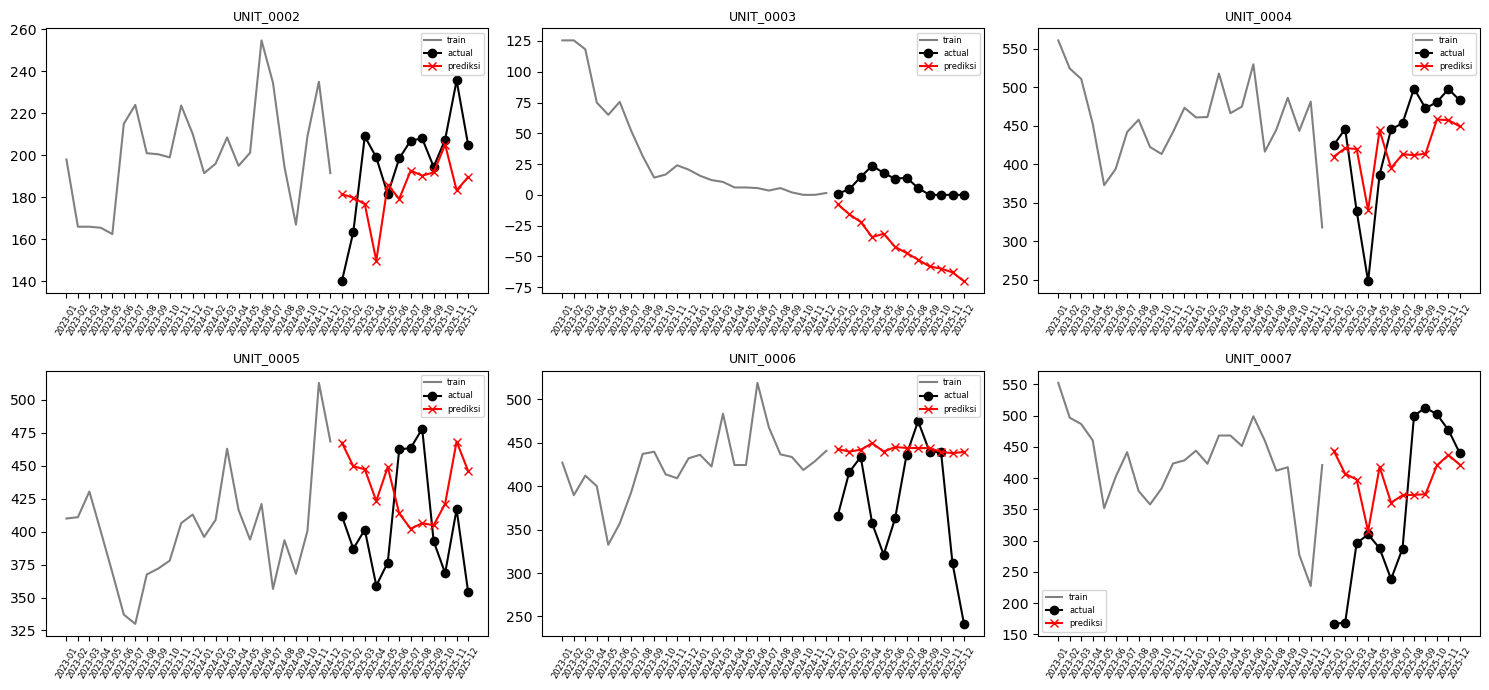

In [22]:
import matplotlib.pyplot as plt
sample_units = unit_list[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for ax, unit in zip(axes.flatten(), sample_units):
    tr_y = get_series(train_full, 'EQUIP NAME', unit)
    te_y = get_series(test_full, 'EQUIP NAME', unit)

    ax.plot(tr_y.index.astype(str), tr_y.values, label='train', color='gray')
    ax.plot(te_y.index.astype(str), te_y.values, label='actual', marker='o', color='black')

    tr_x = get_exog(train_full, 'EQUIP NAME', unit)
    te_x = get_exog(test_full, 'EQUIP NAME', unit)
    if len(tr_y) >= 6 and len(te_y) > 0:
        pred, _ = run_arimax(tr_y, tr_x, te_y, te_x)
        if pred is not None:
            ax.plot(te_y.index.astype(str), pred, label='prediksi', marker='x', color='red')

    ax.set_title(unit, fontsize=9)
    ax.tick_params(axis='x', rotation=60, labelsize=6)
    ax.legend(fontsize=6)

plt.tight_layout()
plt.savefig(OUT_DIR / '16_plot_actual_vs_prediksi_sample.png', dpi=150)
plt.show()

In [23]:
final_predictions = arimax_unit_df.copy()
final_predictions.to_csv(OUT_DIR / '14_final_predictions.csv', index=False)
final_predictions.head()

,EQUIP NAME,MAPE,RMSE
0,UNIT_0002,12.809775,32.280656
1,UNIT_0003,415.206038,53.406711
2,UNIT_0004,17.339054,77.374329
3,UNIT_0005,19.386533,81.105797
4,UNIT_0006,31.788817,108.227267


In [24]:
with pd.ExcelWriter(OUT_DIR / '15_LAPORAN_HASIL.xlsx', engine='openpyxl') as writer:
    summary.to_excel(writer, sheet_name='0_Ringkasan_Model', index=False)
    arimax_unit_df.to_excel(writer, sheet_name='ARIMAX_per_unit', index=False)
    arimax_kriteria_df.to_excel(writer, sheet_name='ARIMAX_per_kriteria', index=False)
    gb_unit_df.to_excel(writer, sheet_name='GB_per_unit', index=False)
    gb_kriteria_df.to_excel(writer, sheet_name='GB_per_kriteria', index=False)
    lstm_unit_df.to_excel(writer, sheet_name='LSTM_per_unit', index=False)
    final_predictions.to_excel(writer, sheet_name='Prediksi_Final', index=False)
    completeness.to_excel(writer, sheet_name='Kelengkapan_Data')
    excluded_df.to_excel(writer, sheet_name='Unit_Dikecualikan', index=False)
    lstm_kriteria_df.to_excel(writer, sheet_name='LSTM_per_kriteria', index=False)

print('Excel tersimpan di:', OUT_DIR / '15_LAPORAN_HASIL.xlsx')

Excel tersimpan di: checkpoints\15_LAPORAN_HASIL.xlsx


In [25]:
audit = pd.DataFrame([
    {'TAHAP': '1. Unit terdeteksi di BBM AAB (unique EQUIP NAME)', 'JUMLAH': len(unit_map)},
    {'TAHAP': '2. Baris harian setelah extract+clean tanggal', 'JUMLAH': len(raw_bbm)},
    {'TAHAP': '3. Baris bulanan (unit x bulan)', 'JUMLAH': len(monthly_hm)},
    {'TAHAP': '4. Unit lolos filter kelayakan (Step 9)', 'JUMLAH': len(keep_units)},
    {'TAHAP': '5. Unit dikecualikan', 'JUMLAH': len(excluded_df)},
    {'TAHAP': '6. Unit match ke file kriteria (JENIS/TYPE/CAP/HP)', 'JUMLAH': kriteria['EQUIP NAME'].nunique()},
])
print(audit.to_string(index=False))

print()
print(excluded_df['ALASAN_EXCLUDE'].value_counts())

print()
print(raw_bbm['DELTA_HM'].describe())

print('% hari dgn DELTA_HM = 0:', (raw_bbm['DELTA_HM']==0).mean()*100, '%')

                                             TAHAP  JUMLAH
 1. Unit terdeteksi di BBM AAB (unique EQUIP NAME)     355
     2. Baris harian setelah extract+clean tanggal  333643
                   3. Baris bulanan (unit x bulan)   10959
           4. Unit lolos filter kelayakan (Step 9)     222
                              5. Unit dikecualikan      18
6. Unit match ke file kriteria (JENIS/TYPE/CAP/HP)     240

ALASAN_EXCLUDE
nol total di salah satu tahun train    15
test bernilai nol seluruhnya            3
Name: count, dtype: int64

count    333643.000000
mean          5.876737
std           7.394286
min           0.000000
25%           0.000000
50%           1.200000
75%          11.000000
max          24.000000
Name: DELTA_HM, dtype: float64
% hari dgn DELTA_HM = 0: 44.99270178004633 %


after bimbingan 1

Total unit dengan minimal 1 outlier: 141 dari 240
Total baris (unit-bulan) terdeteksi outlier: 365 dari 8640
    EQUIP NAME      Q1       Q3      IQR  BATAS_BAWAH  BATAS_ATAS  \
157  UNIT_0215  136.75  166.750   30.000      91.7500    211.7500   
137  UNIT_0192   29.50   77.000   47.500     -41.7500    148.2500   
25   UNIT_0028    0.00    0.000    0.000       0.0000      0.0000   
18   UNIT_0020    0.00    0.000    0.000       0.0000      0.0000   
14   UNIT_0016    0.00    0.000    0.000       0.0000      0.0000   
145  UNIT_0200  366.50  515.250  148.750     143.3750    738.3750   
190  UNIT_0287    0.00    3.025    3.025      -4.5375      7.5625   
151  UNIT_0206  246.50  324.500   78.000     129.5000    441.5000   
61   UNIT_0092  196.75  242.750   46.000     127.7500    311.7500   
33   UNIT_0064   24.50   38.500   14.000       3.5000     59.5000   

     N_OBSERVASI  N_OUTLIER  PERSEN_OUTLIER  
157           36          9           25.00  
137           36          8           2

<Figure size 1200x600 with 0 Axes>

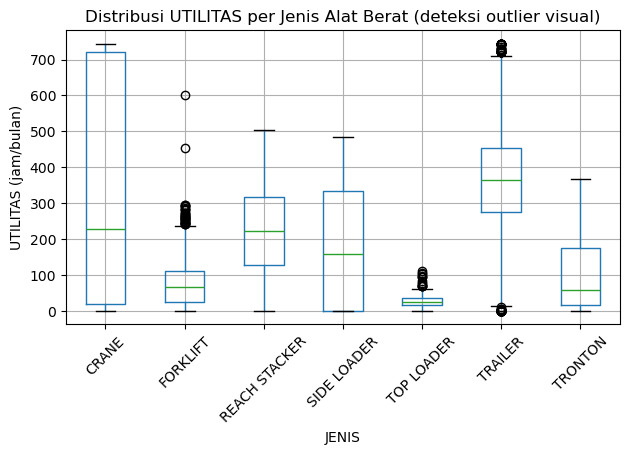

In [26]:
def detect_outliers_iqr(df, value_col='UTILITAS', group_col='EQUIP NAME'):
    results = []
    flagged_rows = []
    for unit, g in df.groupby(group_col):
        q1, q3 = g[value_col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        outliers = g[(g[value_col] < lower) | (g[value_col] > upper)]
        results.append({
            'EQUIP NAME': unit, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
            'BATAS_BAWAH': lower, 'BATAS_ATAS': upper,
            'N_OBSERVASI': len(g), 'N_OUTLIER': len(outliers),
            'PERSEN_OUTLIER': round(100 * len(outliers) / len(g), 2) if len(g) > 0 else 0
        })
        for _, row in outliers.iterrows():
            flagged_rows.append({
                'EQUIP NAME': unit, 'TAHUN_BULAN': row['TAHUN_BULAN'],
                'UTILITAS': row[value_col], 'BATAS_BAWAH': lower, 'BATAS_ATAS': upper
            })
    return pd.DataFrame(results).sort_values('PERSEN_OUTLIER', ascending=False), pd.DataFrame(flagged_rows)

outlier_summary_df, outlier_flagged_df = detect_outliers_iqr(monthly_full)
outlier_summary_df.to_csv(OUT_DIR / '16_outlier_summary_per_unit.csv', index=False)
outlier_flagged_df.to_csv(OUT_DIR / '16b_outlier_flagged_rows.csv', index=False)

print(f'Total unit dengan minimal 1 outlier: {(outlier_summary_df["N_OUTLIER"] > 0).sum()} dari {len(outlier_summary_df)}')
print(f'Total baris (unit-bulan) terdeteksi outlier: {len(outlier_flagged_df)} dari {len(monthly_full)}')
print(outlier_summary_df.head(10))

monthly_full_jenis = monthly_full.merge(kriteria[['EQUIP NAME', 'JENIS']], on='EQUIP NAME', how='left')
plt.figure(figsize=(12, 6))
monthly_full_jenis.boxplot(column='UTILITAS', by='JENIS', rot=45)
plt.title('Distribusi UTILITAS per Jenis Alat Berat (deteksi outlier visual)')
plt.suptitle('')
plt.ylabel('UTILITAS (jam/bulan)')
plt.tight_layout()
plt.savefig(OUT_DIR / '16c_boxplot_utilitas_per_jenis.png', dpi=120, bbox_inches='tight')
plt.show()

In [27]:
from scipy.stats import skew

skew_per_kriteria = (
    train_full.dropna(subset=['UTILITAS'])
    .groupby('KRITERIA_ID')['UTILITAS']
    .apply(lambda s: skew(s, bias=False) if len(s) >= 3 else np.nan)
    .reset_index()
    .rename(columns={'UTILITAS': 'SKEWNESS'})
)

skew_per_kriteria['AGG_TERPILIH'] = np.where(
    skew_per_kriteria['SKEWNESS'].abs() > 1, 'median', 'mean'
)
skew_per_kriteria.to_csv(OUT_DIR / '17_skewness_per_kriteria.csv', index=False)
print(skew_per_kriteria['AGG_TERPILIH'].value_counts())

arimax_kriteria_final_preds = []
for _, row in skew_per_kriteria.iterrows():
    k, agg = row['KRITERIA_ID'], row['AGG_TERPILIH']
    sub = arimax_kriteria_preds_df[
        (arimax_kriteria_preds_df['KRITERIA_ID'] == k) & (arimax_kriteria_preds_df['AGG'] == agg)
    ]
    arimax_kriteria_final_preds.append(sub)
arimax_kriteria_final_preds_df = pd.concat(arimax_kriteria_final_preds, ignore_index=True) if arimax_kriteria_final_preds else pd.DataFrame()
arimax_kriteria_final_preds_df.to_csv(OUT_DIR / '10_arimax_per_kriteria_skewness_predictions.csv', index=False)

mape_skew_based = global_mape(arimax_kriteria_final_preds_df)
print('ARIMAX per-kriteria (pilih via skewness) -> MAPE_GLOBAL:', mape_skew_based)

summary = pd.concat([summary, pd.DataFrame([{
    'MODEL': 'ARIMAX', 'PENDEKATAN': 'per-kriteria (skewness-based)', 'MAPE_GLOBAL': mape_skew_based
}])], ignore_index=True).sort_values('MAPE_GLOBAL')
summary.to_csv(OUT_DIR / '13_model_comparison_summary.csv', index=False)
summary

AGG_TERPILIH
mean      57
median    19
Name: count, dtype: int64
ARIMAX per-kriteria (pilih via skewness) -> MAPE_GLOBAL: 67.65494831314854


,MODEL,PENDEKATAN,MAPE_GLOBAL
0,Gradient Boosting,per-kriteria (pooled),49.110924
1,ARIMAX,per-unit,51.042861
2,Gradient Boosting,per-unit,54.855821
3,LSTM,per-unit,58.254441
4,LSTM,per-kriteria (pooled),63.576936
7,ARIMAX,per-kriteria (skewness-based),67.654948
5,ARIMAX,per-kriteria (mean),67.668667
6,ARIMAX,per-kriteria (median),67.753715


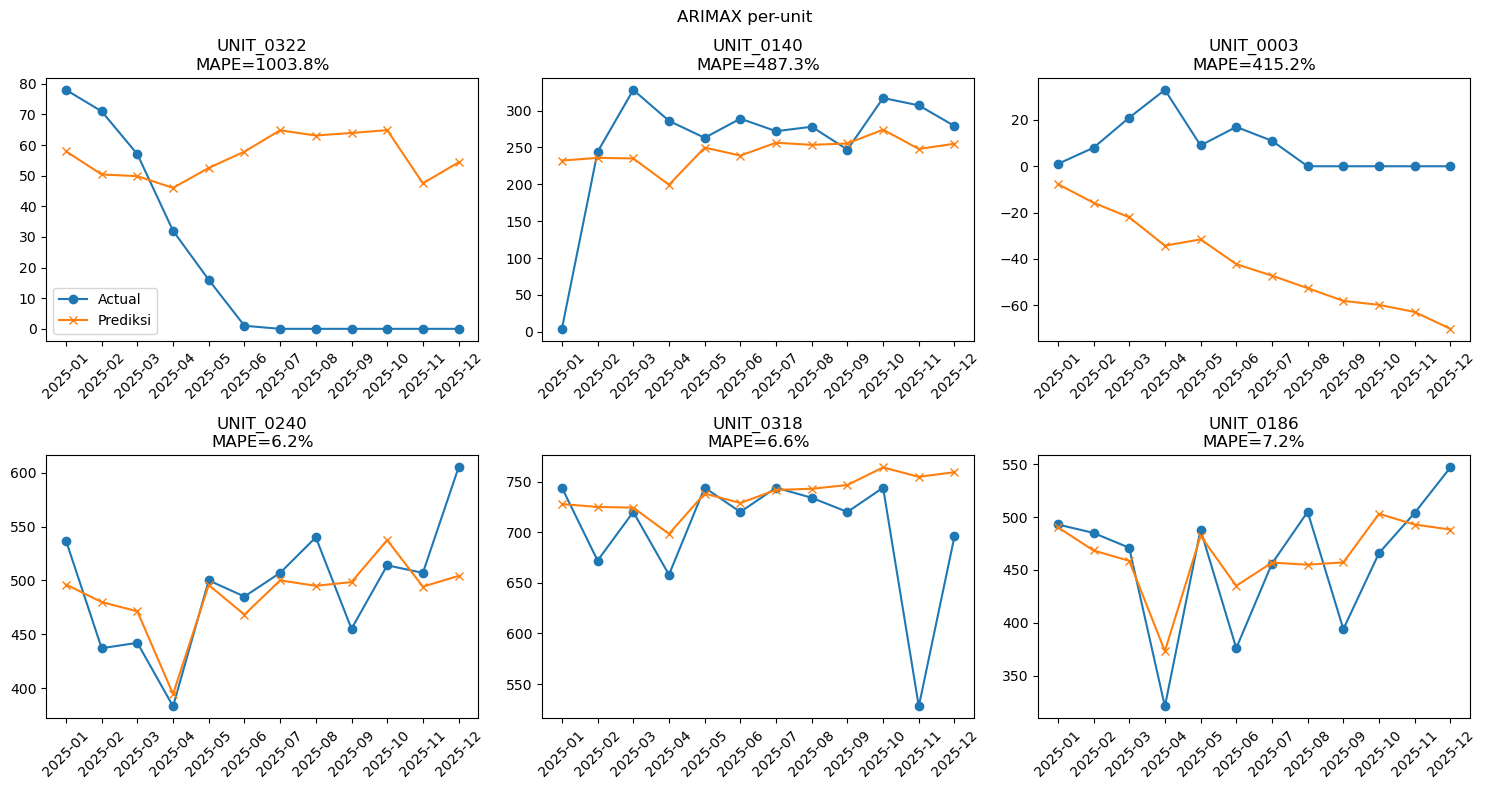

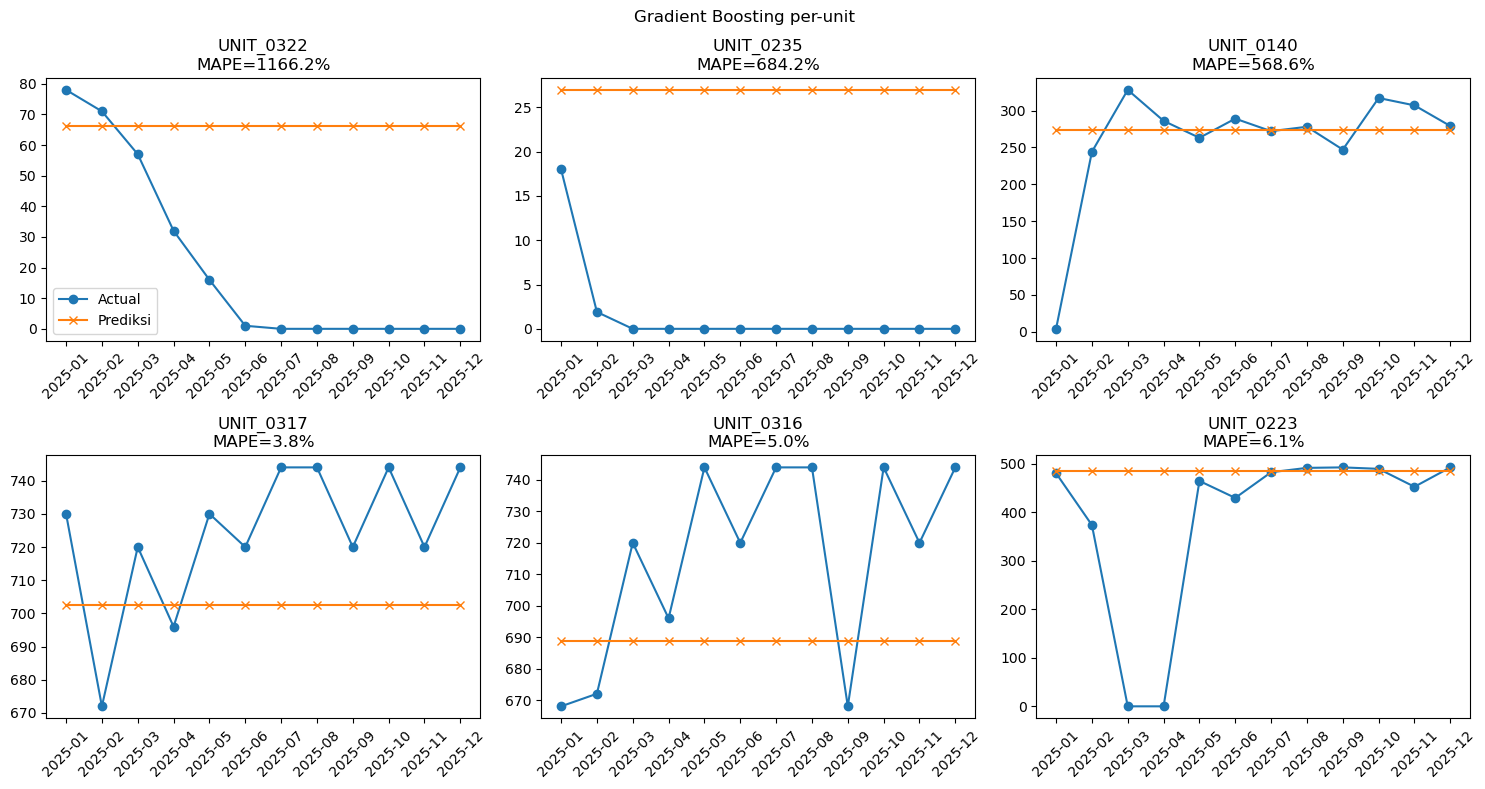

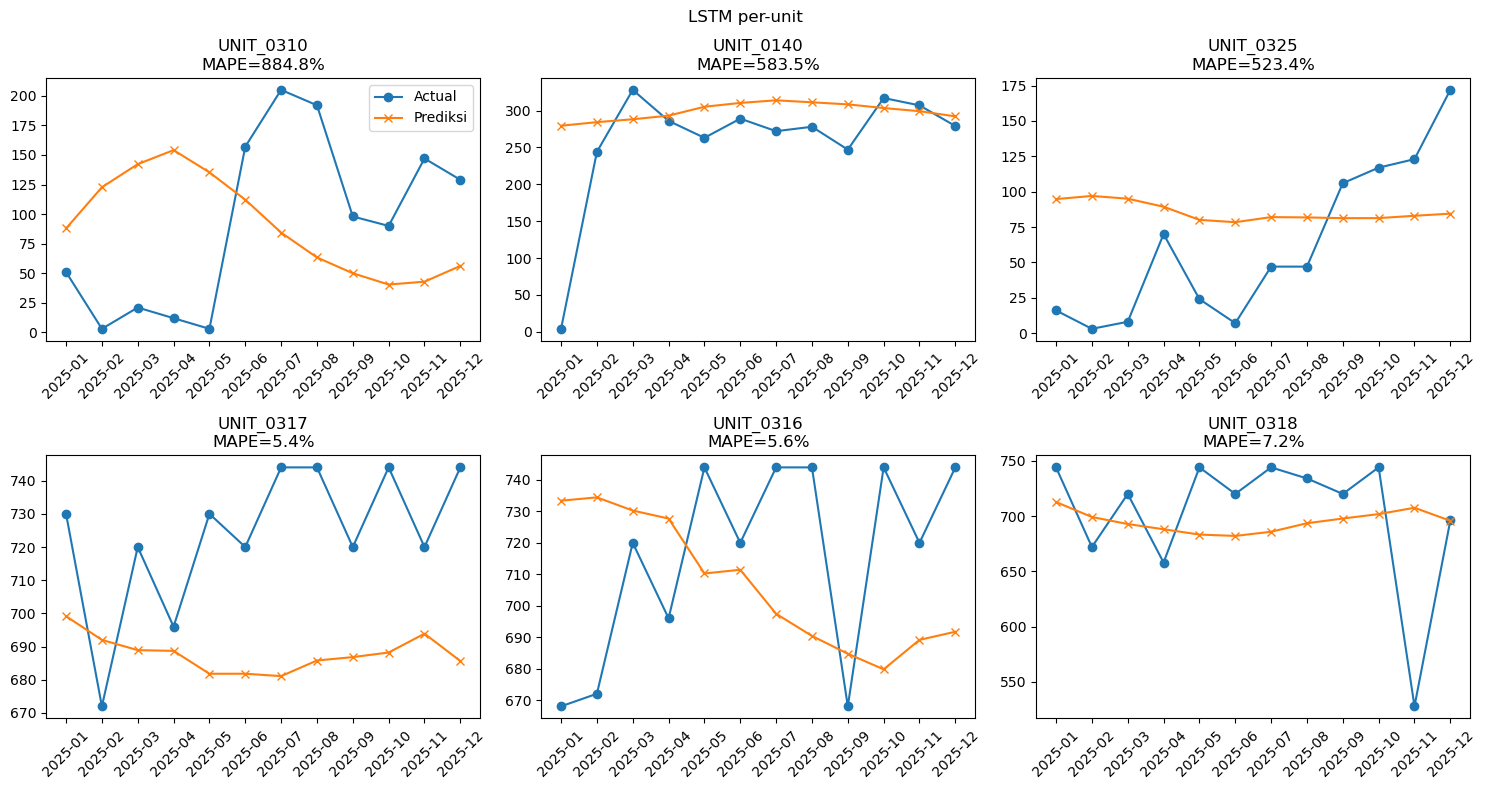

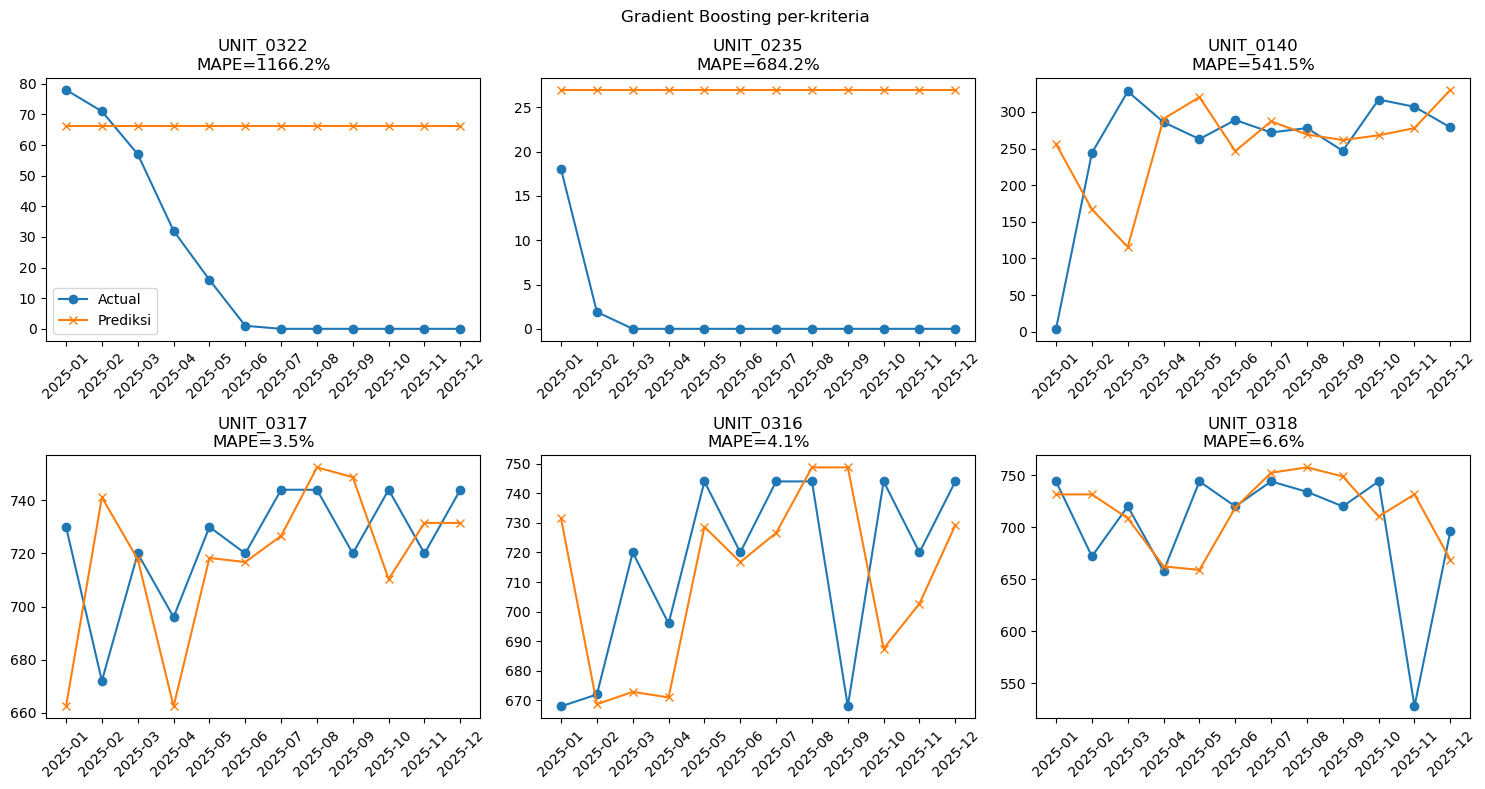

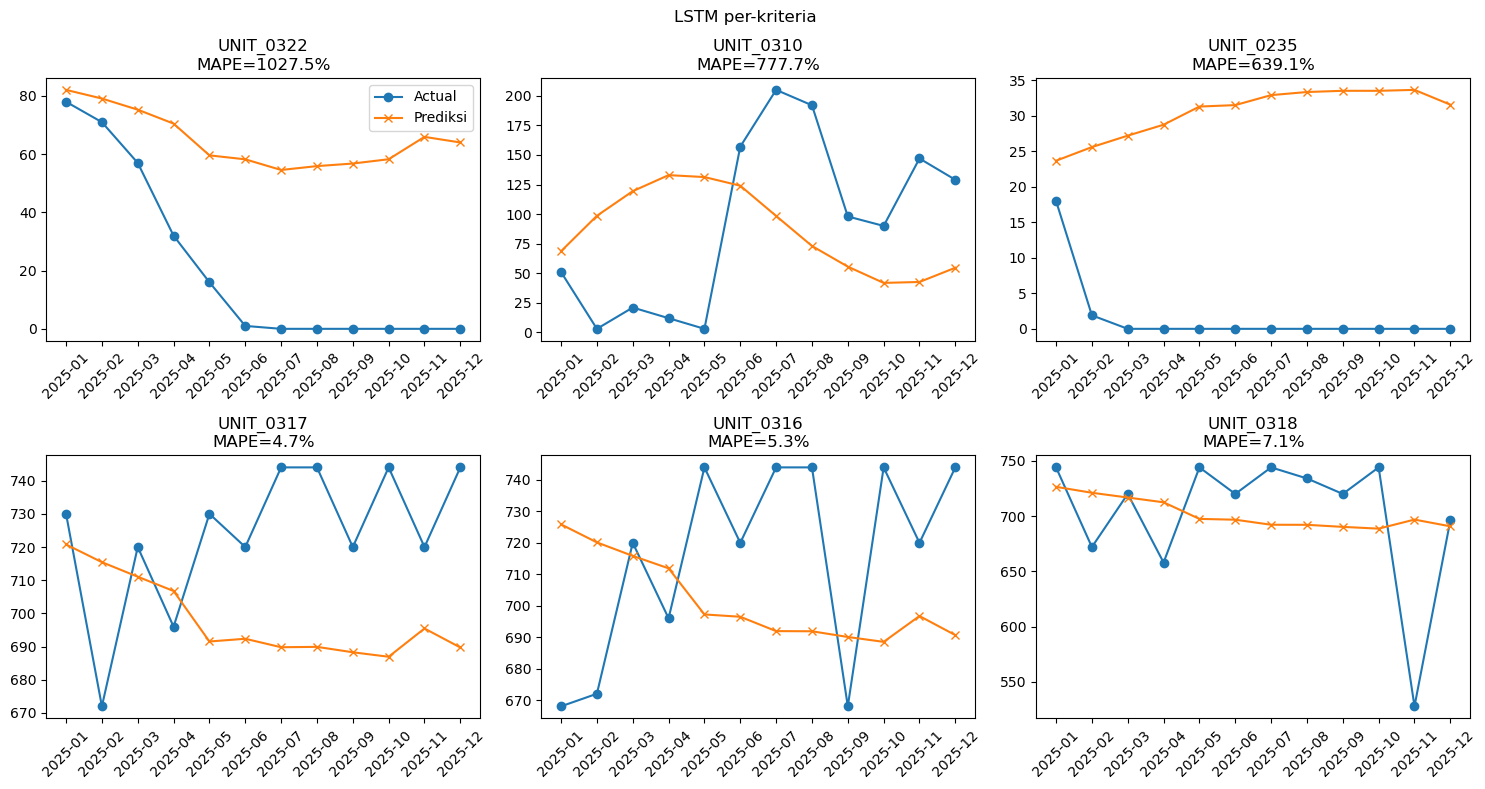

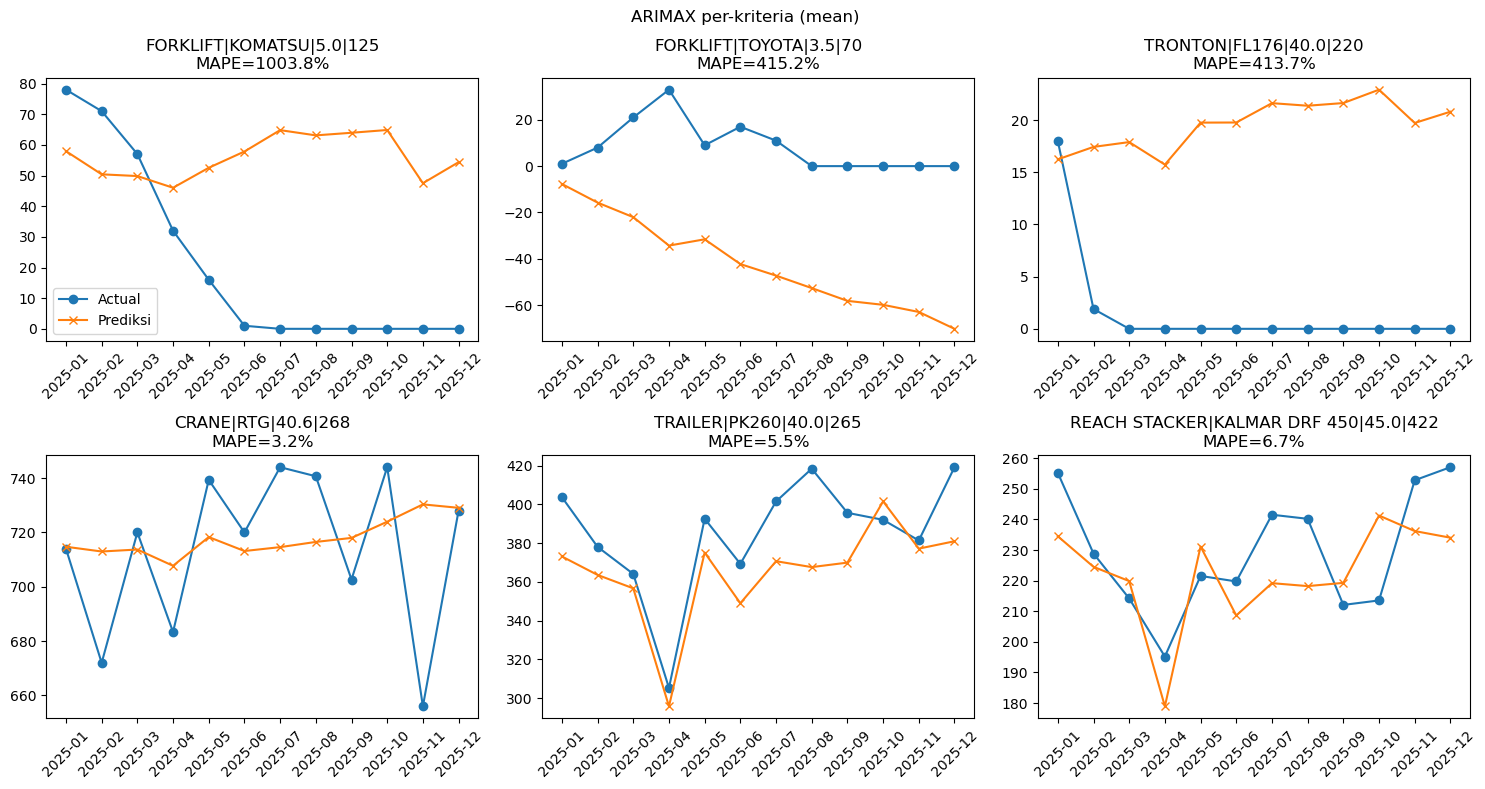

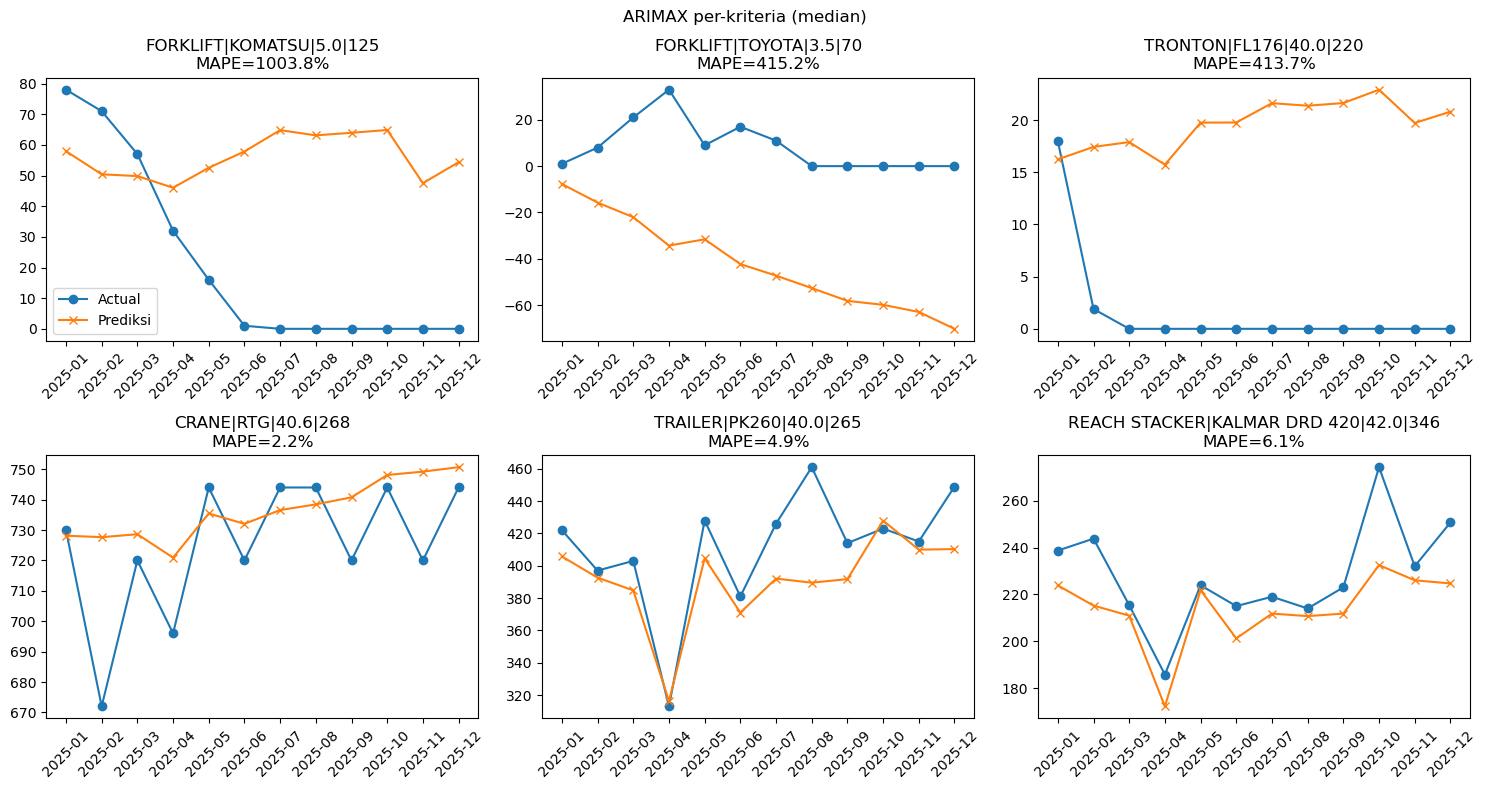

In [28]:
import matplotlib.pyplot as plt

def plot_top_bottom_mape(results_df, preds_df, title, unit_col='EQUIP NAME', fname=None, n=3):
    valid = results_df.dropna(subset=['MAPE'])
    top = valid.nlargest(n, 'MAPE')
    bottom = valid.nsmallest(n, 'MAPE')
    selected = pd.concat([top.assign(GROUP='MAPE Terbesar'), bottom.assign(GROUP='MAPE Terkecil')])

    fig, axes = plt.subplots(2, n, figsize=(5 * n, 8), sharex=False)
    for i, (_, row) in enumerate(selected.iterrows()):
        r, c = divmod(i, n)
        unit = row[unit_col]
        g = preds_df[preds_df[unit_col] == unit].sort_values('TAHUN_BULAN')
        ax = axes[r][c]
        ax.plot(g['TAHUN_BULAN'].astype(str), g['ACTUAL'], marker='o', label='Actual')
        ax.plot(g['TAHUN_BULAN'].astype(str), g['PRED'], marker='x', label='Prediksi')
        ax.set_title(f"{unit}\nMAPE={row['MAPE']:.1f}%")
        ax.tick_params(axis='x', rotation=45)
        if i == 0:
            ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    if fname:
        plt.savefig(OUT_DIR / fname, dpi=120, bbox_inches='tight')
    plt.show()

combos = [
    (arimax_unit_df, arimax_unit_preds_df, 'ARIMAX per-unit', '18a_plot_arimax_unit.png'),
    (gb_unit_df, gb_unit_preds_df, 'Gradient Boosting per-unit', '18b_plot_gb_unit.png'),
    (lstm_unit_df, lstm_unit_preds_df, 'LSTM per-unit', '18c_plot_lstm_unit.png'),
    (gb_kriteria_df, gb_kriteria_preds_df, 'Gradient Boosting per-kriteria', '18d_plot_gb_kriteria.png'),
    (lstm_kriteria_df, lstm_kriteria_preds_df, 'LSTM per-kriteria', '18e_plot_lstm_kriteria.png'),
]
for results_df, preds_df, title, fname in combos:
    plot_top_bottom_mape(results_df, preds_df, title, fname=fname)

for agg in ['mean', 'median']:
    sub_results = arimax_kriteria_df[arimax_kriteria_df['AGG'] == agg]
    sub_preds = arimax_kriteria_preds_df[arimax_kriteria_preds_df['AGG'] == agg]
    plot_top_bottom_mape(sub_results, sub_preds, f'ARIMAX per-kriteria ({agg})',
                          unit_col='KRITERIA_ID', fname=f'18f_plot_arimax_kriteria_{agg}.png')

In [29]:
import itertools
from joblib import Parallel, delayed
import warnings

warnings.filterwarnings('ignore')

P_RANGE = range(0, 9)
D_RANGE = range(0, 5)
Q_RANGE = range(0, 9)
pdq_grid = list(itertools.product(P_RANGE, D_RANGE, Q_RANGE))
print(f'Total kombinasi PDQ: {len(pdq_grid)}')

CHECKPOINT_FILE = OUT_DIR / '19a_gridsearch_arimax_unit_progress.csv'

def fit_one_combo_unit(order, unit_list, train_full, test_full):
    all_preds = []
    for unit in unit_list:
        tr_y = get_series(train_full, 'EQUIP NAME', unit)
        te_y = get_series(test_full, 'EQUIP NAME', unit, value_col='UTILITAS')
        tr_x = get_exog(train_full, 'EQUIP NAME', unit)
        te_x = get_exog(test_full, 'EQUIP NAME', unit)
        if len(tr_y) < 6 or len(te_y) == 0:
            continue
        try:
            model = pm.ARIMA(order=order, suppress_warnings=True)
            model.fit(tr_y, X=tr_x.values)
            pred = model.predict(n_periods=len(te_y), X=(tr_x if len(te_x) == 0 else te_x).values)
            for t, a, p in zip(te_y.index, te_y.values, np.array(pred)):
                all_preds.append({'EQUIP NAME': unit, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
        except Exception:
            continue
    if not all_preds:
        return {'p': order[0], 'd': order[1], 'q': order[2], 'MAPE_GLOBAL': np.nan, 'n_unit_sukses': 0}
    preds_df = pd.DataFrame(all_preds)
    return {'p': order[0], 'd': order[1], 'q': order[2],
            'MAPE_GLOBAL': global_mape(preds_df), 'n_unit_sukses': preds_df['EQUIP NAME'].nunique()}

done_combos = set()
if CHECKPOINT_FILE.exists():
    done_df = pd.read_csv(CHECKPOINT_FILE)
    done_combos = set(zip(done_df['p'], done_df['d'], done_df['q']))
    print(f'Melanjutkan dari checkpoint: {len(done_combos)} kombinasi sudah selesai')

remaining = [pdq for pdq in pdq_grid if pdq not in done_combos]
print(f'Sisa kombinasi yang perlu dijalankan: {len(remaining)}')

BATCH_SIZE = 10
for i in range(0, len(remaining), BATCH_SIZE):
    batch = remaining[i:i + BATCH_SIZE]
    results_batch = Parallel(n_jobs=-1)(
        delayed(fit_one_combo_unit)(order, unit_list, train_full, test_full) for order in batch
    )
    batch_df = pd.DataFrame(results_batch)
    batch_df.to_csv(CHECKPOINT_FILE, mode='a', header=not CHECKPOINT_FILE.exists(), index=False)
    print(f'Selesai {i + len(batch)}/{len(remaining)} kombinasi...')

grid_results_unit = pd.read_csv(CHECKPOINT_FILE).dropna(subset=['MAPE_GLOBAL'])
best_unit = grid_results_unit.loc[grid_results_unit['MAPE_GLOBAL'].idxmin()]
print('Kombinasi PDQ terbaik (per-unit):', best_unit.to_dict())
grid_results_unit.sort_values('MAPE_GLOBAL').to_csv(OUT_DIR / '19a_gridsearch_arimax_unit_final.csv', index=False)

Total kombinasi PDQ: 405
Melanjutkan dari checkpoint: 405 kombinasi sudah selesai
Sisa kombinasi yang perlu dijalankan: 0
Kombinasi PDQ terbaik (per-unit): {'p': 1.0, 'd': 0.0, 'q': 0.0, 'MAPE_GLOBAL': 46.20972223250051, 'n_unit_sukses': 222.0}


In [30]:
CHECKPOINT_FILE_K = OUT_DIR / '19b_gridsearch_arimax_kriteria_progress.csv'

def fit_one_combo_kriteria(order, agg, kriteria_list, train_full, test_full):
    all_preds = []
    for k in kriteria_list:
        tr_y = get_series(train_full, 'KRITERIA_ID', k, agg=agg)
        te_y = get_series(test_full, 'KRITERIA_ID', k, agg=agg, value_col='UTILITAS')
        tr_x = get_exog(train_full, 'KRITERIA_ID', k)
        te_x = get_exog(test_full, 'KRITERIA_ID', k)
        if len(tr_y) < 6 or len(te_y) == 0:
            continue
        try:
            model = pm.ARIMA(order=order, suppress_warnings=True)
            model.fit(tr_y, X=tr_x.values)
            pred = model.predict(n_periods=len(te_y), X=te_x.values)
            for t, a, p in zip(te_y.index, te_y.values, np.array(pred)):
                all_preds.append({'KRITERIA_ID': k, 'AGG': agg, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
        except Exception:
            continue
    if not all_preds:
        return {'p': order[0], 'd': order[1], 'q': order[2], 'AGG': agg, 'MAPE_GLOBAL': np.nan}
    preds_df = pd.DataFrame(all_preds)
    return {'p': order[0], 'd': order[1], 'q': order[2], 'AGG': agg, 'MAPE_GLOBAL': global_mape(preds_df)}

done_combos_k = set()
if CHECKPOINT_FILE_K.exists():
    done_df = pd.read_csv(CHECKPOINT_FILE_K)
    done_combos_k = set(zip(done_df['p'], done_df['d'], done_df['q'], done_df['AGG']))

jobs = [(order, agg) for order in pdq_grid for agg in ['mean', 'median']
        if (order[0], order[1], order[2], agg) not in done_combos_k]
print(f'Sisa kombinasi (kriteria): {len(jobs)}')

for i in range(0, len(jobs), BATCH_SIZE):
    batch = jobs[i:i + BATCH_SIZE]
    results_batch = Parallel(n_jobs=-1)(
        delayed(fit_one_combo_kriteria)(order, agg, kriteria_list, train_full, test_full)
        for order, agg in batch
    )
    batch_df = pd.DataFrame(results_batch)
    batch_df.to_csv(CHECKPOINT_FILE_K, mode='a', header=not CHECKPOINT_FILE_K.exists(), index=False)
    print(f'Selesai {i + len(batch)}/{len(jobs)} kombinasi...')

grid_results_kriteria = pd.read_csv(CHECKPOINT_FILE_K).dropna(subset=['MAPE_GLOBAL'])
for agg in ['mean', 'median']:
    best_k = grid_results_kriteria[grid_results_kriteria['AGG'] == agg].sort_values('MAPE_GLOBAL').iloc[0]
    print(f'Kombinasi PDQ terbaik (kriteria, {agg}):', best_k.to_dict())
grid_results_kriteria.sort_values('MAPE_GLOBAL').to_csv(OUT_DIR / '19b_gridsearch_arimax_kriteria_final.csv', index=False)

Sisa kombinasi (kriteria): 0
Kombinasi PDQ terbaik (kriteria, mean): {'p': 4, 'd': 0, 'q': 3, 'AGG': 'mean', 'MAPE_GLOBAL': 59.44191127096176}
Kombinasi PDQ terbaik (kriteria, median): {'p': 4, 'd': 0, 'q': 3, 'AGG': 'median', 'MAPE_GLOBAL': 59.616827361858135}


In [31]:
gb_param_grid = {
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_iter': [100, 200, 300],
    'max_depth': [None, 3, 5, 7],
    'min_samples_leaf': [5, 10, 20],
}
gb_grid = list(itertools.product(*gb_param_grid.values()))
gb_keys = list(gb_param_grid.keys())

def fit_gb_combo_unit(params_tuple, train_lag, test_lag, feat_cols):
    params = dict(zip(gb_keys, params_tuple))
    all_preds = []
    for unit, g_train in train_lag.groupby('EQUIP NAME'):
        g_train = g_train.dropna(subset=feat_cols + ['UTILITAS_SMOOTH'])
        g_test = test_lag[test_lag['EQUIP NAME'] == unit].dropna(subset=feat_cols)
        if len(g_train) < 6 or len(g_test) == 0:
            continue
        model = HistGradientBoostingRegressor(random_state=42, **params)
        model.fit(g_train[feat_cols], g_train['UTILITAS_SMOOTH'])
        pred = model.predict(g_test[feat_cols])
        actual = g_test.set_index('TAHUN_BULAN')['UTILITAS'].reindex(g_test['TAHUN_BULAN'])
        for t, a, p in zip(g_test['TAHUN_BULAN'].values, actual.values, pred):
            all_preds.append({'EQUIP NAME': unit, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
    preds_df = pd.DataFrame(all_preds)
    return {**params, 'MAPE_GLOBAL': global_mape(preds_df) if not preds_df.empty else np.nan}

CHECKPOINT_GB_UNIT = OUT_DIR / '20a_gb_tuning_unit_progress.csv'

done_gb_unit = set()
if CHECKPOINT_GB_UNIT.exists():
    done_df = pd.read_csv(CHECKPOINT_GB_UNIT)
    done_gb_unit = set(zip(*[done_df[k] for k in gb_keys]))
    print(f'Melanjutkan dari checkpoint: {len(done_gb_unit)} kombinasi sudah selesai')

remaining_gb_unit = [p for p in gb_grid if p not in done_gb_unit]
print(f'Sisa kombinasi GB per-unit: {len(remaining_gb_unit)}')

BATCH_SIZE = 10
for i in range(0, len(remaining_gb_unit), BATCH_SIZE):
    batch = remaining_gb_unit[i:i + BATCH_SIZE]
    results_batch = Parallel(n_jobs=-1)(
        delayed(fit_gb_combo_unit)(p, train_lag, test_lag, feat_cols) for p in batch
    )
    batch_df = pd.DataFrame(results_batch)
    batch_df.to_csv(CHECKPOINT_GB_UNIT, mode='a', header=not CHECKPOINT_GB_UNIT.exists(), index=False)
    print(f'Selesai {i + len(batch)}/{len(remaining_gb_unit)} kombinasi GB per-unit...')

gb_tuning_df = pd.read_csv(CHECKPOINT_GB_UNIT).dropna(subset=['MAPE_GLOBAL']).sort_values('MAPE_GLOBAL')
gb_tuning_df.to_csv(OUT_DIR / '20a_gb_tuning_unit_results.csv', index=False)
print('GB per-unit best params:', gb_tuning_df.iloc[0].to_dict())

Melanjutkan dari checkpoint: 216 kombinasi sudah selesai
Sisa kombinasi GB per-unit: 36
Selesai 10/36 kombinasi GB per-unit...
Selesai 20/36 kombinasi GB per-unit...
Selesai 30/36 kombinasi GB per-unit...
Selesai 36/36 kombinasi GB per-unit...
GB per-unit best params: {'learning_rate': 0.01, 'max_iter': 200.0, 'max_depth': 5.0, 'min_samples_leaf': 5.0, 'MAPE_GLOBAL': 45.76499576133444}


In [32]:
def fit_gb_combo_kriteria(params_tuple, train_lag, test_lag, feat_cols, kriteria_list):
    params = dict(zip(gb_keys, params_tuple))
    all_preds = []
    for k in kriteria_list:
        g_train = train_lag[train_lag['KRITERIA_ID'] == k].dropna(subset=feat_cols + ['UTILITAS_SMOOTH'])
        g_test = test_lag[test_lag['KRITERIA_ID'] == k].dropna(subset=feat_cols)
        if len(g_train) < 6 or len(g_test) == 0:
            continue
        model = HistGradientBoostingRegressor(random_state=42, **params)
        model.fit(g_train[feat_cols], g_train['UTILITAS_SMOOTH'])
        pred = model.predict(g_test[feat_cols])
        for unit, g_unit_test in g_test.groupby('EQUIP NAME'):
            mask = g_test['EQUIP NAME'] == unit
            actual = g_unit_test.set_index('TAHUN_BULAN')['UTILITAS'].reindex(g_unit_test['TAHUN_BULAN'])
            for t, a, p in zip(g_unit_test['TAHUN_BULAN'].values, actual.values, pred[mask.values]):
                all_preds.append({'EQUIP NAME': unit, 'KRITERIA_ID': k, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
    preds_df = pd.DataFrame(all_preds)
    return {**params, 'MAPE_GLOBAL': global_mape(preds_df) if not preds_df.empty else np.nan}

CHECKPOINT_GB_KRITERIA = OUT_DIR / '20a_gb_tuning_kriteria_progress.csv'

done_gb_kriteria = set()
if CHECKPOINT_GB_KRITERIA.exists():
    done_df = pd.read_csv(CHECKPOINT_GB_KRITERIA)
    done_gb_kriteria = set(zip(*[done_df[k] for k in gb_keys]))
    print(f'Melanjutkan dari checkpoint: {len(done_gb_kriteria)} kombinasi sudah selesai')

remaining_gb_kriteria = [p for p in gb_grid if p not in done_gb_kriteria]
print(f'Sisa kombinasi GB per-kriteria: {len(remaining_gb_kriteria)}')

for i in range(0, len(remaining_gb_kriteria), BATCH_SIZE):
    batch = remaining_gb_kriteria[i:i + BATCH_SIZE]
    results_batch = Parallel(n_jobs=-1)(
        delayed(fit_gb_combo_kriteria)(p, train_lag, test_lag, feat_cols, kriteria_list) for p in batch
    )
    batch_df = pd.DataFrame(results_batch)
    batch_df.to_csv(CHECKPOINT_GB_KRITERIA, mode='a', header=not CHECKPOINT_GB_KRITERIA.exists(), index=False)
    print(f'Selesai {i + len(batch)}/{len(remaining_gb_kriteria)} kombinasi GB per-kriteria...')

gb_tuning_kriteria_df = pd.read_csv(CHECKPOINT_GB_KRITERIA).dropna(subset=['MAPE_GLOBAL']).sort_values('MAPE_GLOBAL')
gb_tuning_kriteria_df.to_csv(OUT_DIR / '20a_gb_tuning_kriteria_results.csv', index=False)
print('GB per-kriteria best params:', gb_tuning_kriteria_df.iloc[0].to_dict())

Melanjutkan dari checkpoint: 216 kombinasi sudah selesai
Sisa kombinasi GB per-kriteria: 36
Selesai 10/36 kombinasi GB per-kriteria...
Selesai 20/36 kombinasi GB per-kriteria...
Selesai 30/36 kombinasi GB per-kriteria...
Selesai 36/36 kombinasi GB per-kriteria...
GB per-kriteria best params: {'learning_rate': 0.01, 'max_iter': 300.0, 'max_depth': 7.0, 'min_samples_leaf': 5.0, 'MAPE_GLOBAL': 44.32973103883951}


In [33]:
lstm_param_grid = {
    'seq_len': [3, 6],
    'units': [16, 32],
    'epochs': [30, 50],
}
lstm_grid = list(itertools.product(*lstm_param_grid.values()))

def fit_lstm_combo(seq_len, units, epochs, train_full, test_full, unit_list):
    all_preds = []
    for unit in unit_list:
        tr_y = get_series(train_full, 'EQUIP NAME', unit)
        te_y = get_series(test_full, 'EQUIP NAME', unit, value_col='UTILITAS')
        tr_x = get_exog(train_full, 'EQUIP NAME', unit)
        te_x = get_exog(test_full, 'EQUIP NAME', unit)
        if len(tr_y) < seq_len + 6 or len(te_y) == 0:
            continue

        def build_lstm_custom(n_features):
            m = keras.Sequential([
                keras.layers.LSTM(units, input_shape=(seq_len, n_features)),
                keras.layers.Dense(16, activation='relu'),
                keras.layers.Dense(1),
            ])
            m.compile(optimizer='adam', loss='mse')
            return m

        feat = pd.concat([tr_y.rename('y'), tr_x], axis=1).dropna()
        if len(feat) < seq_len + 3:
            continue
        scaler = MinMaxScaler()
        scaled = scaler.fit_transform(feat.values)
        X, y = make_sequences(scaled, seq_len)
        if len(X) < 3:
            continue
        model = build_lstm_custom(scaled.shape[1])
        model.fit(X, y, epochs=epochs, batch_size=8, verbose=0)

        window = scaled[-seq_len:].copy()
        exog_future = te_x.values
        exog_future_scaled = scaler.transform(
            np.hstack([np.zeros((len(exog_future), 1)), exog_future])
        )[:, 1:]
        preds_scaled = []
        for i in range(len(te_y)):
            x_in = window[-seq_len:].reshape(1, seq_len, scaled.shape[1])
            yhat = model.predict(x_in, verbose=0)[0, 0]
            preds_scaled.append(yhat)
            window = np.vstack([window, np.hstack([[yhat], exog_future_scaled[i]])])
        dummy = np.zeros((len(preds_scaled), scaled.shape[1]))
        dummy[:, 0] = preds_scaled
        pred_actual = scaler.inverse_transform(dummy)[:, 0]

        for t, a, p in zip(te_y.index, te_y.values, pred_actual):
            all_preds.append({'EQUIP NAME': unit, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
    preds_df = pd.DataFrame(all_preds)
    return {'seq_len': seq_len, 'units': units, 'epochs': epochs,
            'MAPE_GLOBAL': global_mape(preds_df) if not preds_df.empty else np.nan}

CHECKPOINT_LSTM_UNIT = OUT_DIR / '20b_lstm_tuning_results.csv'

done_lstm_unit = set()
if CHECKPOINT_LSTM_UNIT.exists():
    done_df = pd.read_csv(CHECKPOINT_LSTM_UNIT)
    done_lstm_unit = set(zip(done_df['seq_len'], done_df['units'], done_df['epochs']))
    print(f'Melanjutkan dari checkpoint: {len(done_lstm_unit)} kombinasi sudah selesai')

remaining_lstm_unit = [c for c in lstm_grid if c not in done_lstm_unit]
print(f'Sisa kombinasi LSTM per-unit: {len(remaining_lstm_unit)}')

for seq_len, units, epochs in remaining_lstm_unit:
    print(f'Menjalankan LSTM seq_len={seq_len}, units={units}, epochs={epochs}...')
    res = fit_lstm_combo(seq_len, units, epochs, train_full, test_full, unit_list)
    pd.DataFrame([res]).to_csv(CHECKPOINT_LSTM_UNIT, mode='a', header=not CHECKPOINT_LSTM_UNIT.exists(), index=False)

lstm_tuning_df = pd.read_csv(CHECKPOINT_LSTM_UNIT).dropna(subset=['MAPE_GLOBAL']).sort_values('MAPE_GLOBAL')
print('LSTM per-unit best params:', lstm_tuning_df.iloc[0].to_dict())

Melanjutkan dari checkpoint: 8 kombinasi sudah selesai
Sisa kombinasi LSTM per-unit: 0
LSTM per-unit best params: {'seq_len': 3.0, 'units': 16.0, 'epochs': 50.0, 'MAPE_GLOBAL': 49.68383420042847}


In [34]:
def fit_lstm_combo_kriteria(seq_len, units, epochs, train_full, test_full, kriteria_list):
    all_preds = []
    for k in kriteria_list:
        train_sub = train_full[train_full['KRITERIA_ID'] == k]
        units_in_k = train_sub['EQUIP NAME'].dropna().unique().tolist()
        if not units_in_k:
            continue

        def build_lstm_custom(n_features):
            m = keras.Sequential([
                keras.layers.LSTM(units, input_shape=(seq_len, n_features)),
                keras.layers.Dense(16, activation='relu'),
                keras.layers.Dense(1),
            ])
            m.compile(optimizer='adam', loss='mse')
            return m

        pooled_feat = []
        for u in units_in_k:
            s_y = get_series(train_full, 'EQUIP NAME', u)
            s_x = get_exog(train_full, 'EQUIP NAME', u)
            feat = pd.concat([s_y.rename('y'), s_x], axis=1).dropna()
            if len(feat) >= seq_len + 1:
                pooled_feat.append(feat)
        if not pooled_feat:
            continue

        combined = pd.concat(pooled_feat, axis=0)
        scaler = MinMaxScaler()
        scaler.fit(combined.values)

        all_X, all_y = [], []
        for feat in pooled_feat:
            scaled = scaler.transform(feat.values)
            X, y = make_sequences(scaled, seq_len)
            if len(X) > 0:
                all_X.append(X); all_y.append(y)
        if not all_X:
            continue
        X_train = np.concatenate(all_X)
        y_train = np.concatenate(all_y)
        if len(X_train) < 5:
            continue

        model = build_lstm_custom(X_train.shape[2])
        model.fit(X_train, y_train, epochs=epochs, batch_size=16, verbose=0)

        for u in units_in_k:
            tr_y = get_series(train_full, 'EQUIP NAME', u)
            te_y = get_series(test_full, 'EQUIP NAME', u, value_col='UTILITAS')
            tr_x = get_exog(train_full, 'EQUIP NAME', u)
            te_x = get_exog(test_full, 'EQUIP NAME', u)
            if len(tr_y) < seq_len or len(te_y) == 0:
                continue
            feat = pd.concat([tr_y.rename('y'), tr_x], axis=1).dropna()
            if len(feat) < seq_len:
                continue
            scaled = scaler.transform(feat.values)
            window = scaled[-seq_len:].copy()
            exog_future = te_x.values
            exog_future_scaled = scaler.transform(
                np.hstack([np.zeros((len(exog_future), 1)), exog_future])
            )[:, 1:]
            preds_scaled = []
            for i in range(len(te_y)):
                x_in = window[-seq_len:].reshape(1, seq_len, scaled.shape[1])
                yhat = model.predict(x_in, verbose=0)[0, 0]
                preds_scaled.append(yhat)
                window = np.vstack([window, np.hstack([[yhat], exog_future_scaled[i]])])
            dummy = np.zeros((len(preds_scaled), scaled.shape[1]))
            dummy[:, 0] = preds_scaled
            pred_actual = scaler.inverse_transform(dummy)[:, 0]
            for t, a, p in zip(te_y.index, te_y.values, pred_actual):
                all_preds.append({'EQUIP NAME': u, 'KRITERIA_ID': k, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})

    preds_df = pd.DataFrame(all_preds)
    return {'seq_len': seq_len, 'units': units, 'epochs': epochs,
            'MAPE_GLOBAL': global_mape(preds_df) if not preds_df.empty else np.nan}

CHECKPOINT_LSTM_KRITERIA = OUT_DIR / '20b_lstm_tuning_kriteria_results.csv'

done_lstm_kriteria = set()
if CHECKPOINT_LSTM_KRITERIA.exists():
    done_df = pd.read_csv(CHECKPOINT_LSTM_KRITERIA)
    done_lstm_kriteria = set(zip(done_df['seq_len'], done_df['units'], done_df['epochs']))
    print(f'Melanjutkan dari checkpoint: {len(done_lstm_kriteria)} kombinasi sudah selesai')

remaining_lstm_kriteria = [c for c in lstm_grid if c not in done_lstm_kriteria]
print(f'Sisa kombinasi LSTM per-kriteria: {len(remaining_lstm_kriteria)}')

for seq_len, units, epochs in remaining_lstm_kriteria:
    print(f'Menjalankan LSTM kriteria seq_len={seq_len}, units={units}, epochs={epochs}...')
    res = fit_lstm_combo_kriteria(seq_len, units, epochs, train_full, test_full, kriteria_list)
    pd.DataFrame([res]).to_csv(CHECKPOINT_LSTM_KRITERIA, mode='a', header=not CHECKPOINT_LSTM_KRITERIA.exists(), index=False)

lstm_tuning_kriteria_df = pd.read_csv(CHECKPOINT_LSTM_KRITERIA).dropna(subset=['MAPE_GLOBAL']).sort_values('MAPE_GLOBAL')
print('LSTM per-kriteria best params:', lstm_tuning_kriteria_df.iloc[0].to_dict())

Melanjutkan dari checkpoint: 8 kombinasi sudah selesai
Sisa kombinasi LSTM per-kriteria: 0
LSTM per-kriteria best params: {'seq_len': 3.0, 'units': 16.0, 'epochs': 50.0, 'MAPE_GLOBAL': 52.92445933459042}


In [35]:
import openpyxl
from openpyxl.styles import Font, PatternFill

all_experiments = []

for _, row in summary.iterrows():
    all_experiments.append({
        'MODEL': row['MODEL'],
        'PENDEKATAN': row['PENDEKATAN'],
        'PARAMETER': 'auto_arima (default)' if row['MODEL'] == 'ARIMAX' else 'default (belum di-tuning)',
        'SUMBER': 'Baseline',
        'MAPE_GLOBAL': row['MAPE_GLOBAL'],
    })

if 'grid_results_unit' in dir() and len(grid_results_unit) > 0:
    best_row = grid_results_unit.loc[grid_results_unit['MAPE_GLOBAL'].idxmin()]
    all_experiments.append({
        'MODEL': 'ARIMAX',
        'PENDEKATAN': 'per-unit (grid search)',
        'PARAMETER': f"p={int(best_row['p'])}, d={int(best_row['d'])}, q={int(best_row['q'])}",
        'SUMBER': 'Grid Search PDQ',
        'MAPE_GLOBAL': best_row['MAPE_GLOBAL'],
    })

if 'grid_results_kriteria' in dir() and len(grid_results_kriteria) > 0:
    for agg in ['mean', 'median']:
        sub = grid_results_kriteria[grid_results_kriteria['AGG'] == agg]
        if len(sub) == 0:
            continue
        best_row = sub.loc[sub['MAPE_GLOBAL'].idxmin()]
        all_experiments.append({
            'MODEL': 'ARIMAX',
            'PENDEKATAN': f'per-kriteria (grid search, {agg})',
            'PARAMETER': f"p={int(best_row['p'])}, d={int(best_row['d'])}, q={int(best_row['q'])}",
            'SUMBER': 'Grid Search PDQ',
            'MAPE_GLOBAL': best_row['MAPE_GLOBAL'],
        })

if 'gb_tuning_df' in dir() and len(gb_tuning_df) > 0:
    best_row = gb_tuning_df.iloc[0]
    param_str = ', '.join(f"{k}={best_row[k]}" for k in gb_param_grid.keys())
    all_experiments.append({
        'MODEL': 'Gradient Boosting',
        'PENDEKATAN': 'per-unit (tuned)',
        'PARAMETER': param_str,
        'SUMBER': 'Hyperparameter Tuning',
        'MAPE_GLOBAL': best_row['MAPE_GLOBAL'],
    })

if 'lstm_tuning_df' in dir() and len(lstm_tuning_df) > 0:
    best_row = lstm_tuning_df.iloc[0]
    param_str = ', '.join(f"{k}={best_row[k]}" for k in lstm_param_grid.keys())
    all_experiments.append({
        'MODEL': 'LSTM',
        'PENDEKATAN': 'per-unit (tuned)',
        'PARAMETER': param_str,
        'SUMBER': 'Hyperparameter Tuning',
        'MAPE_GLOBAL': best_row['MAPE_GLOBAL'],
    })

if 'gb_tuning_kriteria_df' in dir() and len(gb_tuning_kriteria_df) > 0:
    best_row = gb_tuning_kriteria_df.iloc[0]
    param_str = ', '.join(f"{k}={best_row[k]}" for k in gb_param_grid.keys())
    all_experiments.append({
        'MODEL': 'Gradient Boosting',
        'PENDEKATAN': 'per-kriteria (tuned)',
        'PARAMETER': param_str,
        'SUMBER': 'Hyperparameter Tuning',
        'MAPE_GLOBAL': best_row['MAPE_GLOBAL'],
    })

if 'lstm_tuning_kriteria_df' in dir() and len(lstm_tuning_kriteria_df) > 0:
    best_row = lstm_tuning_kriteria_df.iloc[0]
    param_str = ', '.join(f"{k}={best_row[k]}" for k in lstm_param_grid.keys())
    all_experiments.append({
        'MODEL': 'LSTM',
        'PENDEKATAN': 'per-kriteria (tuned)',
        'PARAMETER': param_str,
        'SUMBER': 'Hyperparameter Tuning',
        'MAPE_GLOBAL': best_row['MAPE_GLOBAL'],
    })

all_experiments_df = pd.DataFrame(all_experiments).sort_values('MAPE_GLOBAL').reset_index(drop=True)
all_experiments_df.insert(0, 'RANKING', range(1, len(all_experiments_df) + 1))

all_experiments_df['PENDEKATAN_GROUP'] = np.where(
    all_experiments_df['PENDEKATAN'].str.contains('kriteria'), 'per-kriteria', 'per-unit'
)


ringkasan_keseluruhan = all_experiments_df.head(1).copy()

terbaik_per_model = (
    all_experiments_df.loc[all_experiments_df.groupby('MODEL')['MAPE_GLOBAL'].idxmin()]
    .sort_values('MAPE_GLOBAL').reset_index(drop=True)
)

terbaik_per_pendekatan = (
    all_experiments_df.loc[all_experiments_df.groupby(['MODEL', 'PENDEKATAN_GROUP'])['MAPE_GLOBAL'].idxmin()]
    .sort_values('MAPE_GLOBAL').reset_index(drop=True)
)

semua_percobaan = all_experiments_df.copy()

detail_grid_unit = grid_results_unit.sort_values('MAPE_GLOBAL').head(20) if 'grid_results_unit' in dir() else pd.DataFrame()
detail_grid_kriteria = grid_results_kriteria.sort_values('MAPE_GLOBAL').head(20) if 'grid_results_kriteria' in dir() else pd.DataFrame()
detail_gb_tuning = gb_tuning_df.head(20) if 'gb_tuning_df' in dir() else pd.DataFrame()
detail_gb_tuning_kriteria = gb_tuning_kriteria_df.head(20) if 'gb_tuning_kriteria_df' in dir() else pd.DataFrame()
detail_lstm_tuning = lstm_tuning_df.head(20) if 'lstm_tuning_df' in dir() else pd.DataFrame()
detail_lstm_tuning_kriteria = lstm_tuning_kriteria_df.head(20) if 'lstm_tuning_kriteria_df' in dir() else pd.DataFrame()

OUTPUT_PATH = OUT_DIR / '21_RINGKASAN_SEMUA_PERCOBAAN.xlsx'

with pd.ExcelWriter(OUTPUT_PATH, engine='openpyxl') as writer:
    ringkasan_keseluruhan.to_excel(writer, sheet_name='0_Juara_Keseluruhan', index=False)
    terbaik_per_model.to_excel(writer, sheet_name='1_Terbaik_per_Model', index=False)
    terbaik_per_pendekatan.to_excel(writer, sheet_name='2_Terbaik_per_Pendekatan', index=False)
    semua_percobaan.to_excel(writer, sheet_name='3_Semua_Percobaan', index=False)
    if not detail_grid_unit.empty:
        detail_grid_unit.to_excel(writer, sheet_name='4_Detail_GridPDQ_per-unit', index=False)
    if not detail_grid_kriteria.empty:
        detail_grid_kriteria.to_excel(writer, sheet_name='5_Detail_GridPDQ_kriteria', index=False)
    if not detail_gb_tuning.empty:
        detail_gb_tuning.to_excel(writer, sheet_name='6_Detail_Tuning_GB', index=False)
    if not detail_lstm_tuning.empty:
        detail_lstm_tuning.to_excel(writer, sheet_name='7_Detail_Tuning_LSTM', index=False)
    if not detail_gb_tuning_kriteria.empty:
        detail_gb_tuning_kriteria.to_excel(writer, sheet_name='8_Detail_Tuning_GB_kriteria', index=False)
    if not detail_lstm_tuning_kriteria.empty:
        detail_lstm_tuning_kriteria.to_excel(writer, sheet_name='9_Detail_Tuning_LSTM_kriteria', index=False)

wb = openpyxl.load_workbook(OUTPUT_PATH)
header_font = Font(bold=True)
win_fill = PatternFill(start_color='C6EFCE', end_color='C6EFCE', fill_type='solid')

for sheet_name in wb.sheetnames:
    ws = wb[sheet_name]
    for cell in ws[1]:
        cell.font = header_font
    for col in ws.columns:
        max_len = max(len(str(c.value)) for c in col if c.value is not None) + 2
        ws.column_dimensions[col[0].column_letter].width = min(max_len, 45)
    if sheet_name in ('0_Juara_Keseluruhan',):
        for cell in ws[2]:
            cell.fill = win_fill
    elif sheet_name in ('1_Terbaik_per_Model', '2_Terbaik_per_Pendekatan', '3_Semua_Percobaan'):
        for row in ws.iter_rows(min_row=2, max_row=2):
            for cell in row:
                cell.fill = win_fill

wb.save(OUTPUT_PATH)

print('Juara keseluruhan:')
print(ringkasan_keseluruhan.to_string(index=False))
print()
print('Terbaik per model:')
print(terbaik_per_model[['MODEL', 'PENDEKATAN', 'MAPE_GLOBAL']].to_string(index=False))
print()
print(f'Laporan lengkap tersimpan di: {OUTPUT_PATH}')

Juara keseluruhan:
 RANKING             MODEL           PENDEKATAN                                                               PARAMETER                SUMBER  MAPE_GLOBAL PENDEKATAN_GROUP
       1 Gradient Boosting per-kriteria (tuned) learning_rate=0.01, max_iter=300.0, max_depth=7.0, min_samples_leaf=5.0 Hyperparameter Tuning    44.329731     per-kriteria

Terbaik per model:
            MODEL             PENDEKATAN  MAPE_GLOBAL
Gradient Boosting   per-kriteria (tuned)    44.329731
           ARIMAX per-unit (grid search)    46.209722
             LSTM       per-unit (tuned)    49.683834

Laporan lengkap tersimpan di: checkpoints\21_RINGKASAN_SEMUA_PERCOBAAN.xlsx


Top-3 PDQ per-unit:
 p  d  q  MAPE_GLOBAL  n_unit_sukses
 1  0  0    46.209722            222
 1  0  1    46.399523            222
 2  0  0    46.799255            222


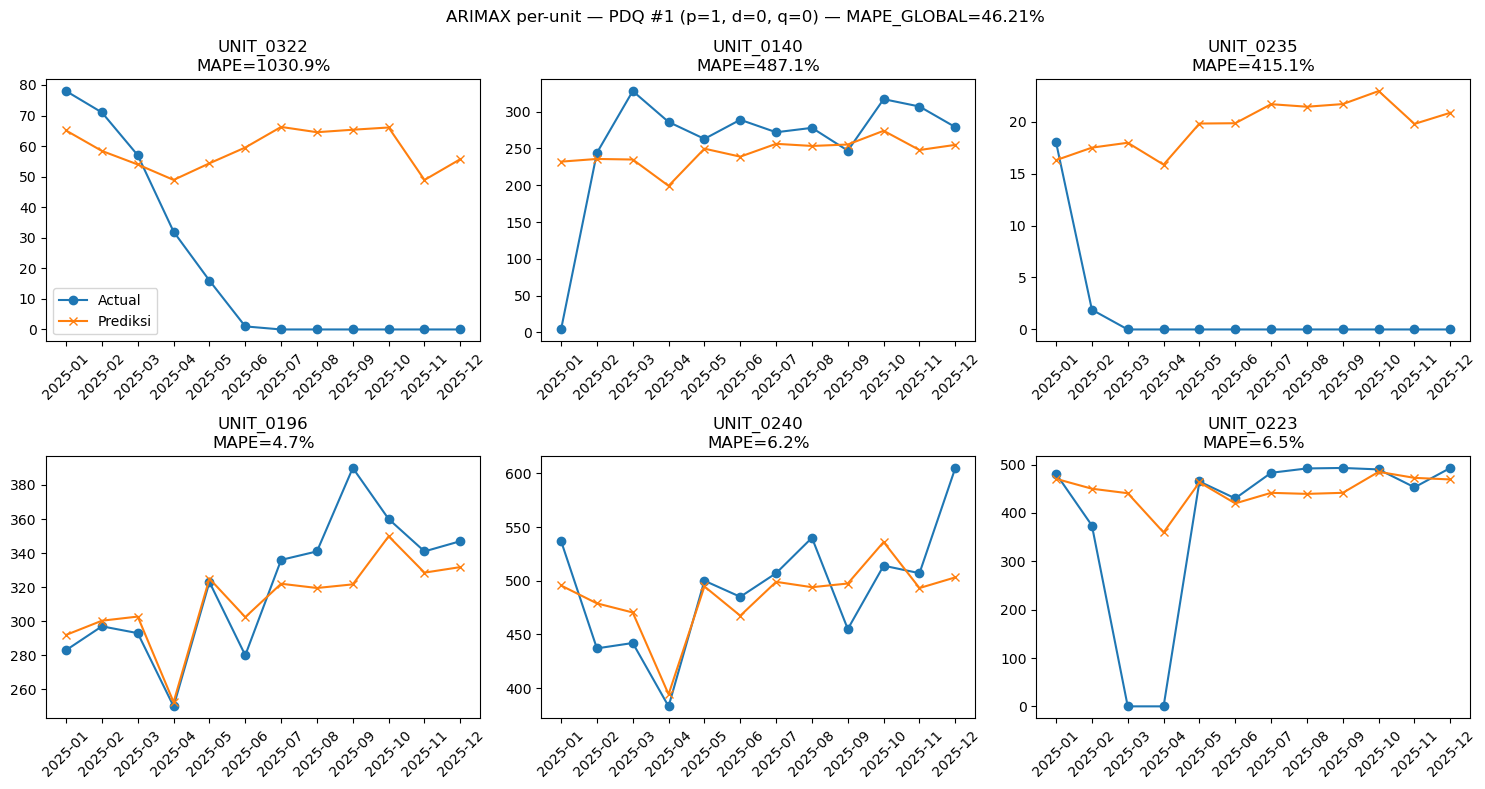

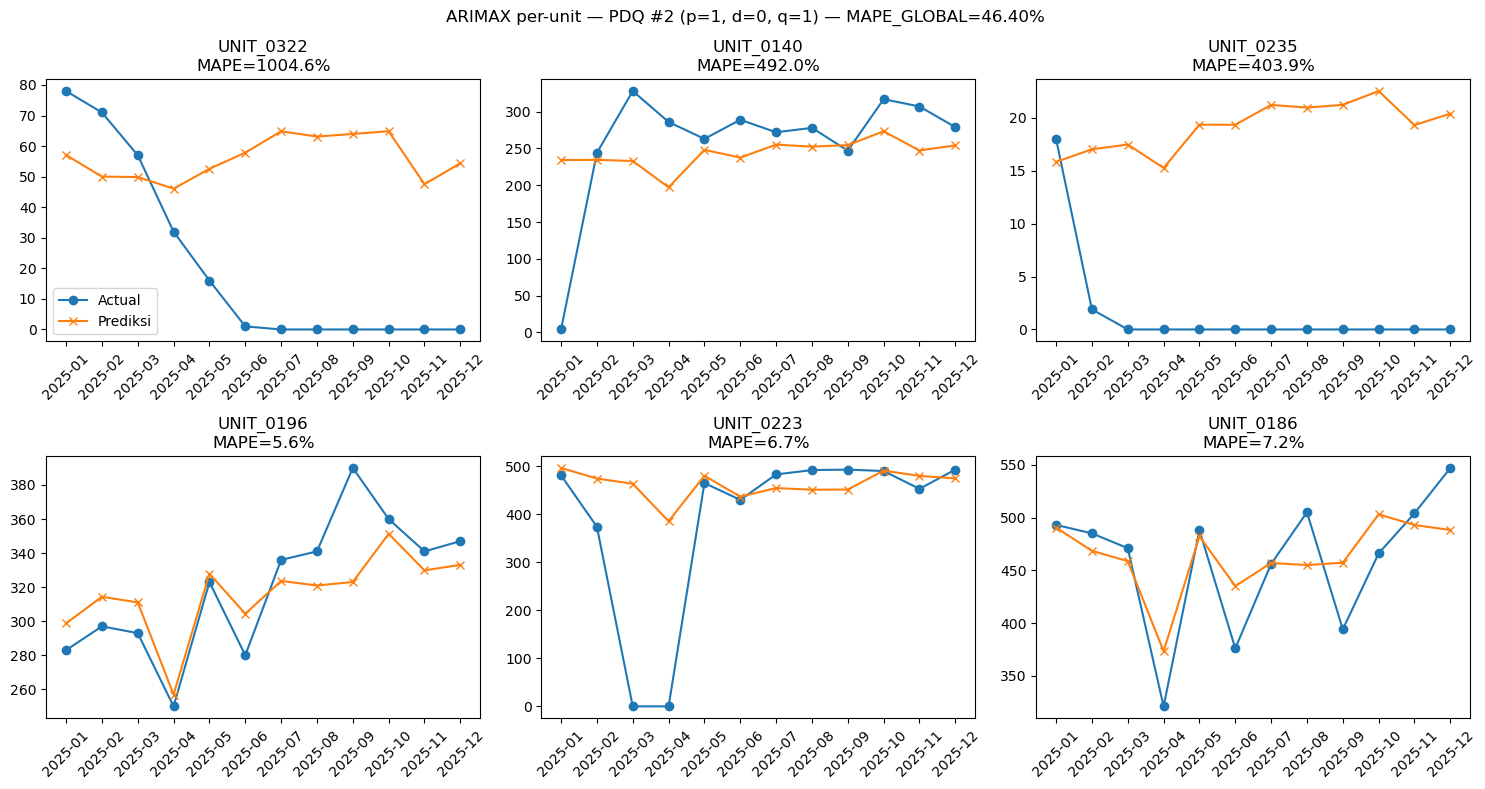

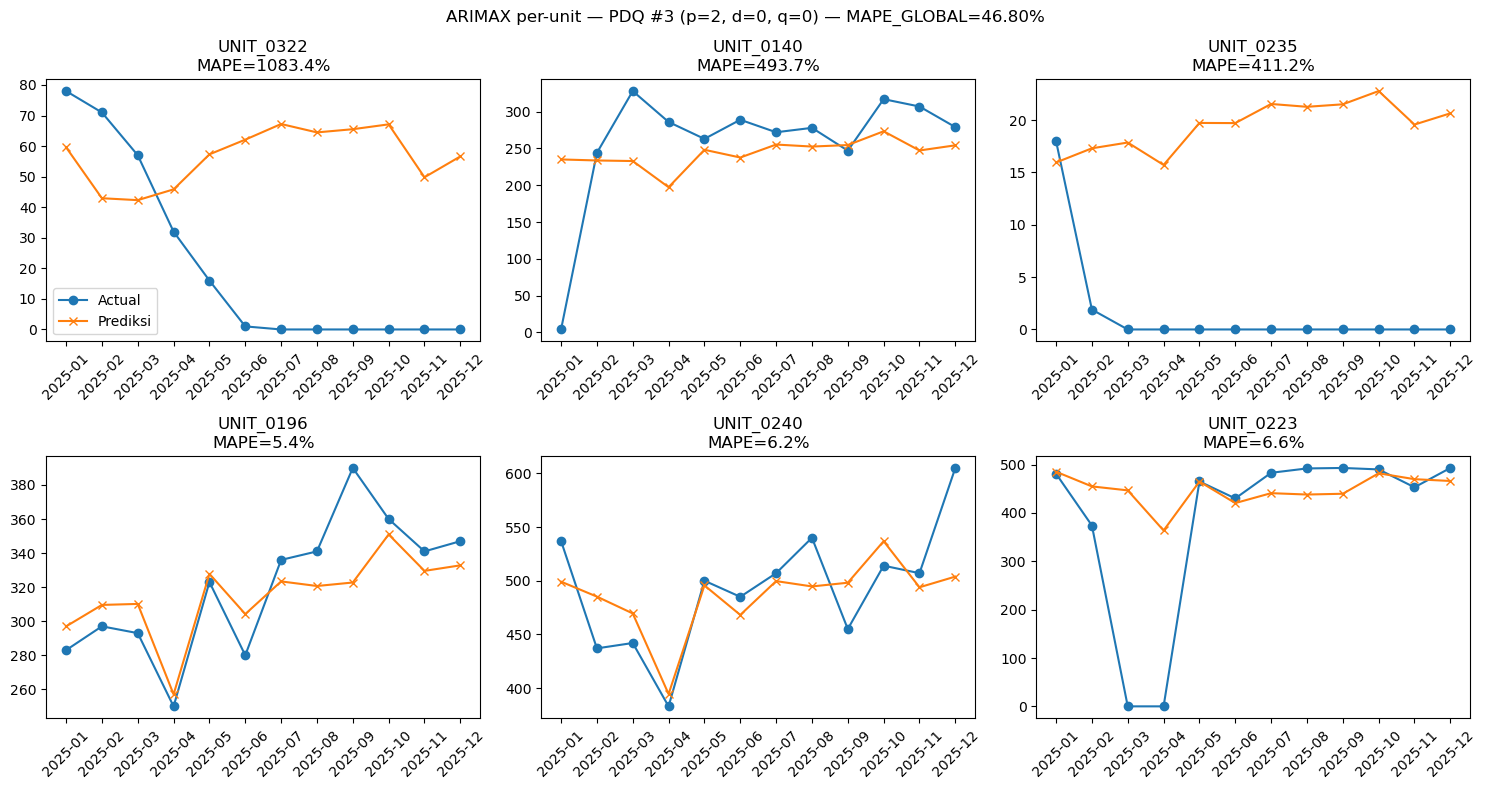


Top-3 PDQ per-kriteria (mean):
 p  d  q  AGG  MAPE_GLOBAL
 4  0  3 mean    59.441911
 1  0  0 mean    60.018632
 1  0  1 mean    60.191877


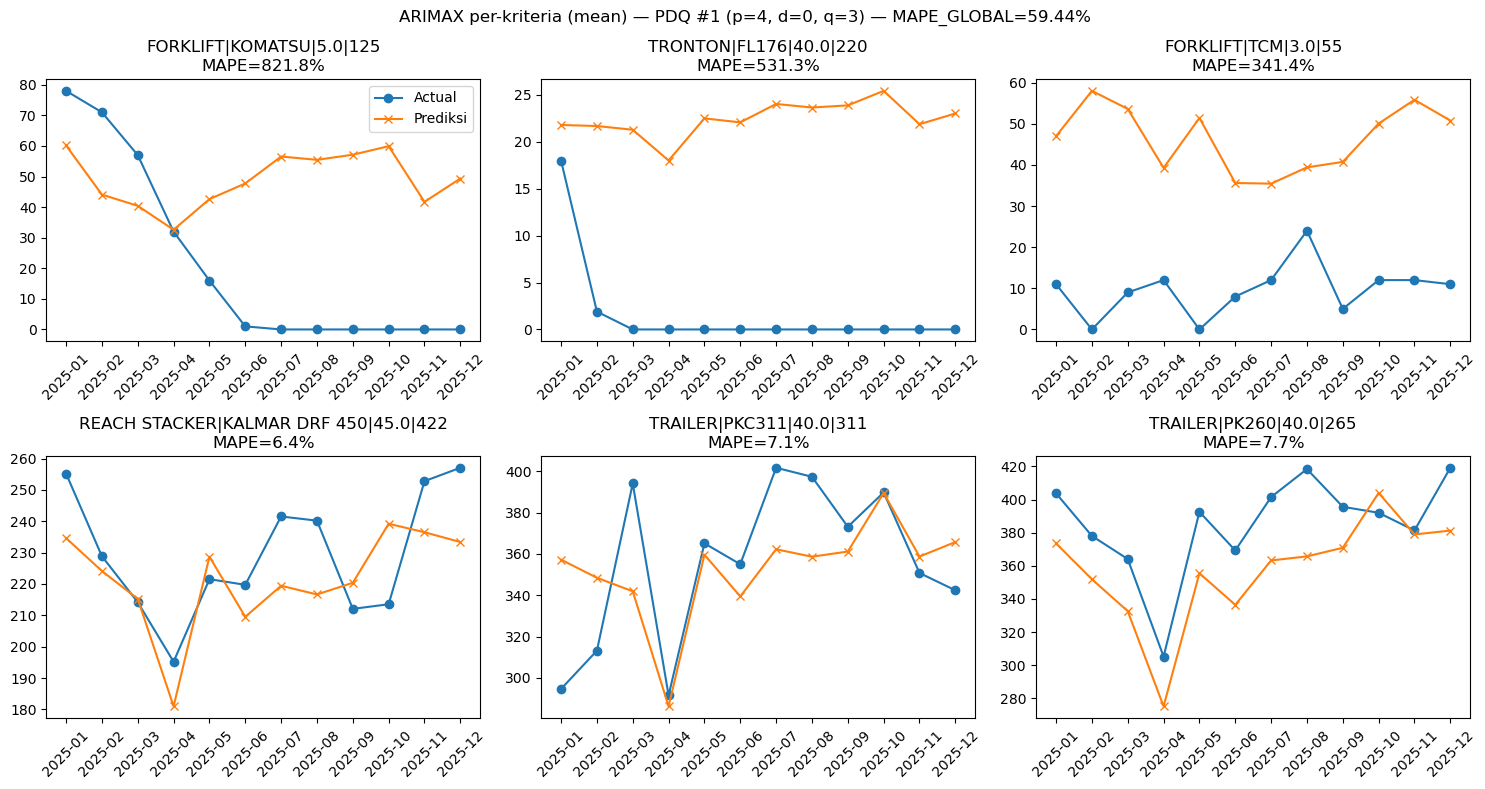

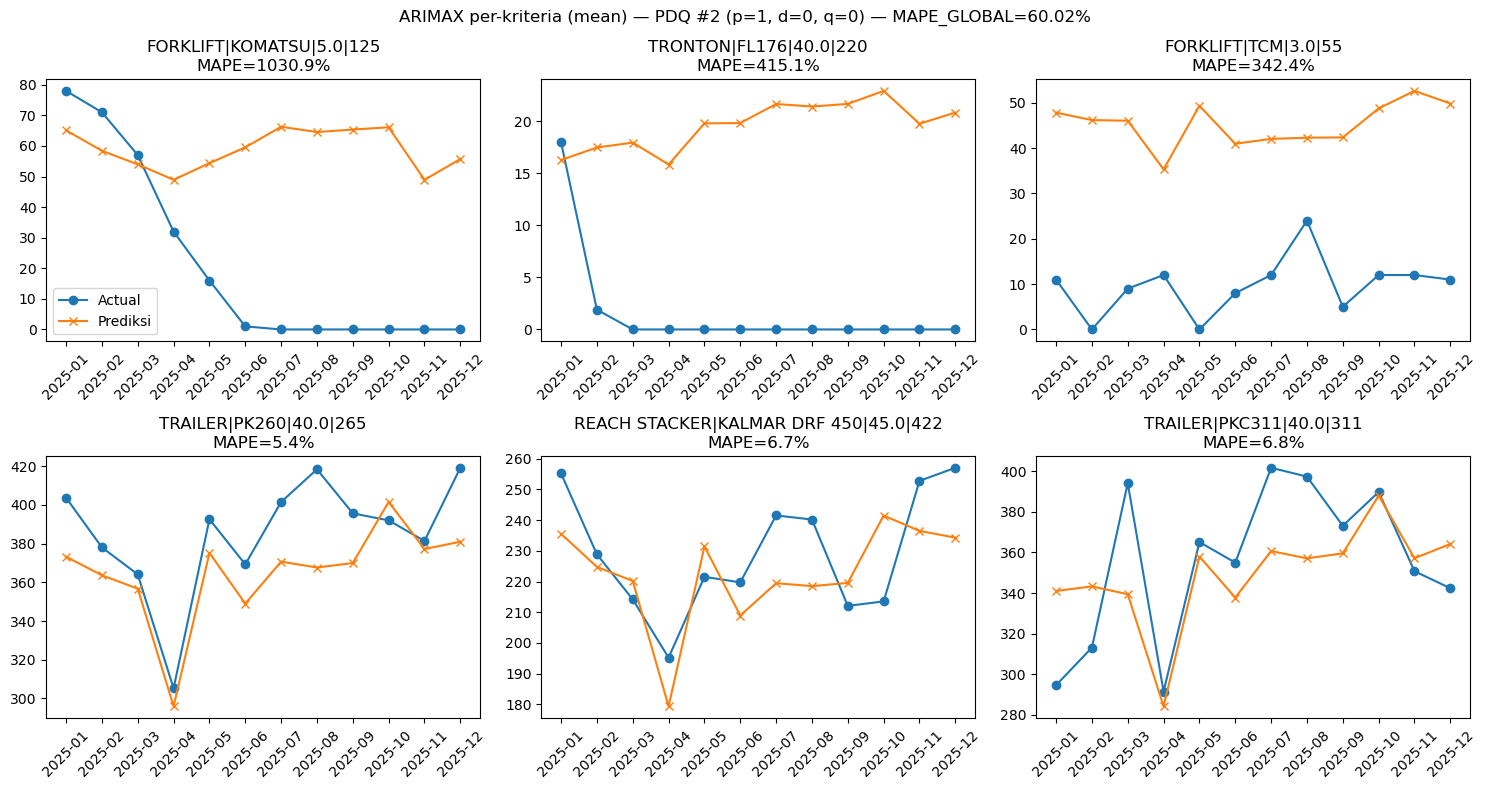

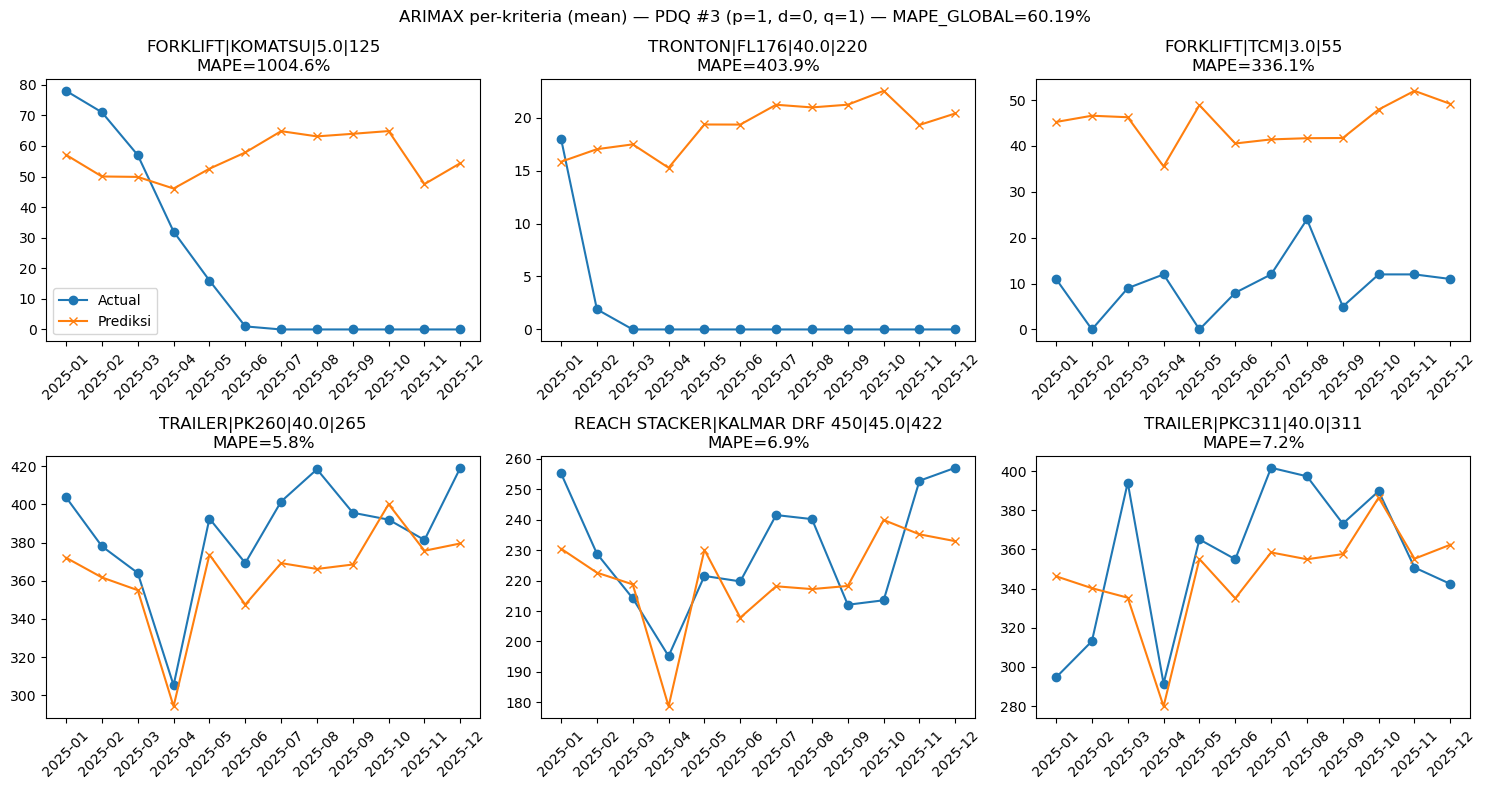


Top-3 PDQ per-kriteria (median):
 p  d  q    AGG  MAPE_GLOBAL
 4  0  3 median    59.616827
 1  0  3 median    60.311431
 1  0  0 median    60.410329


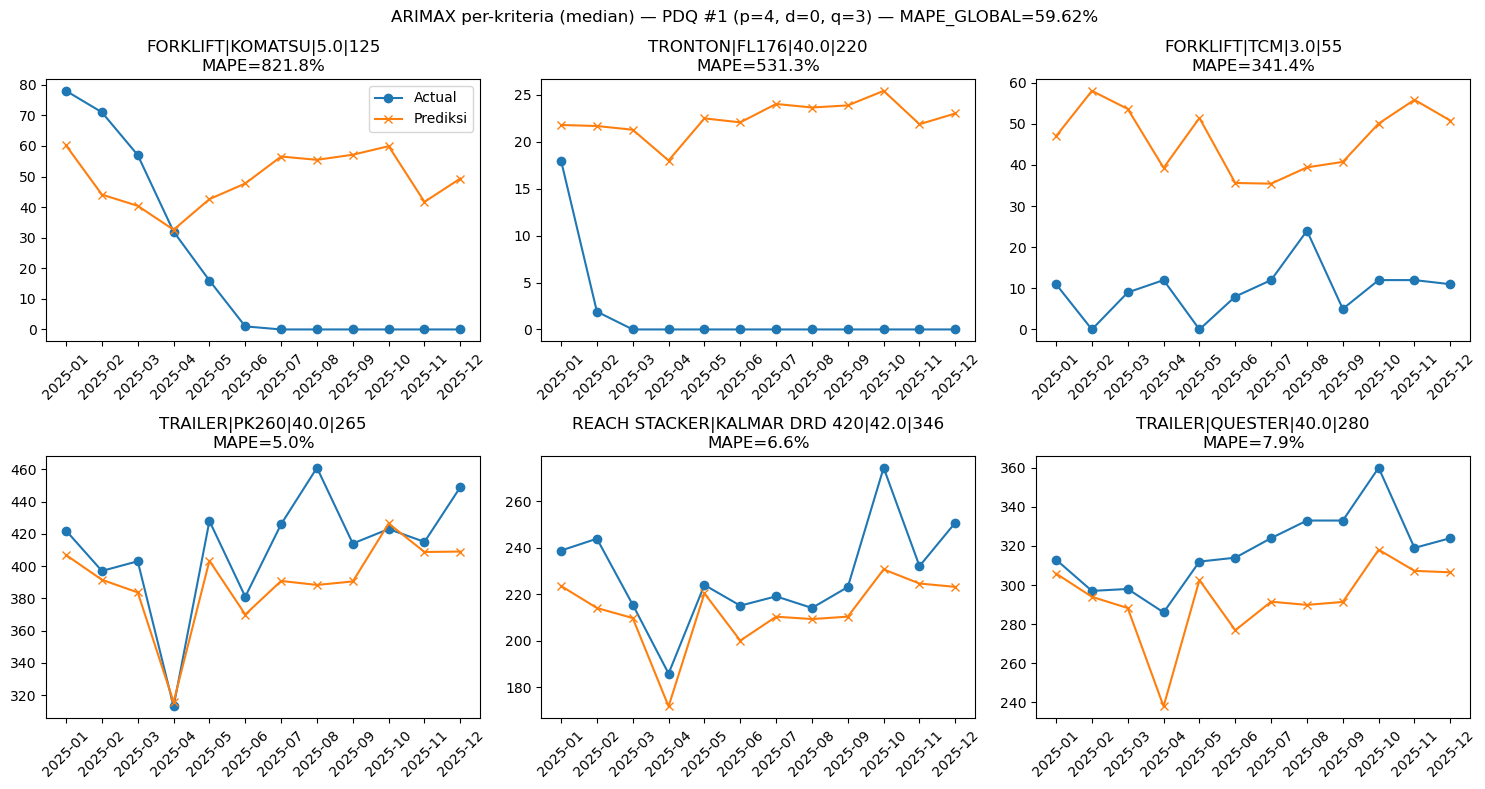

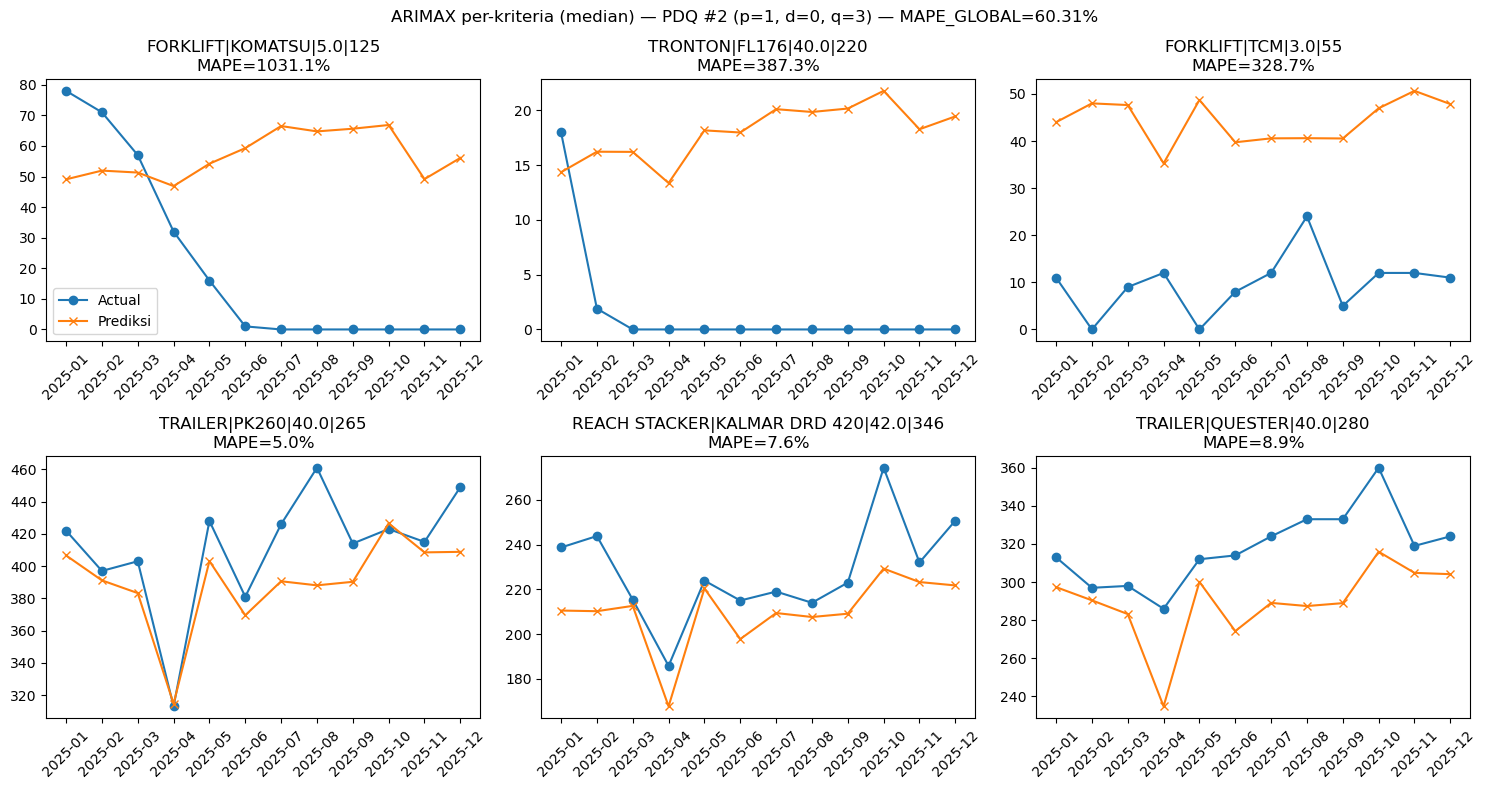

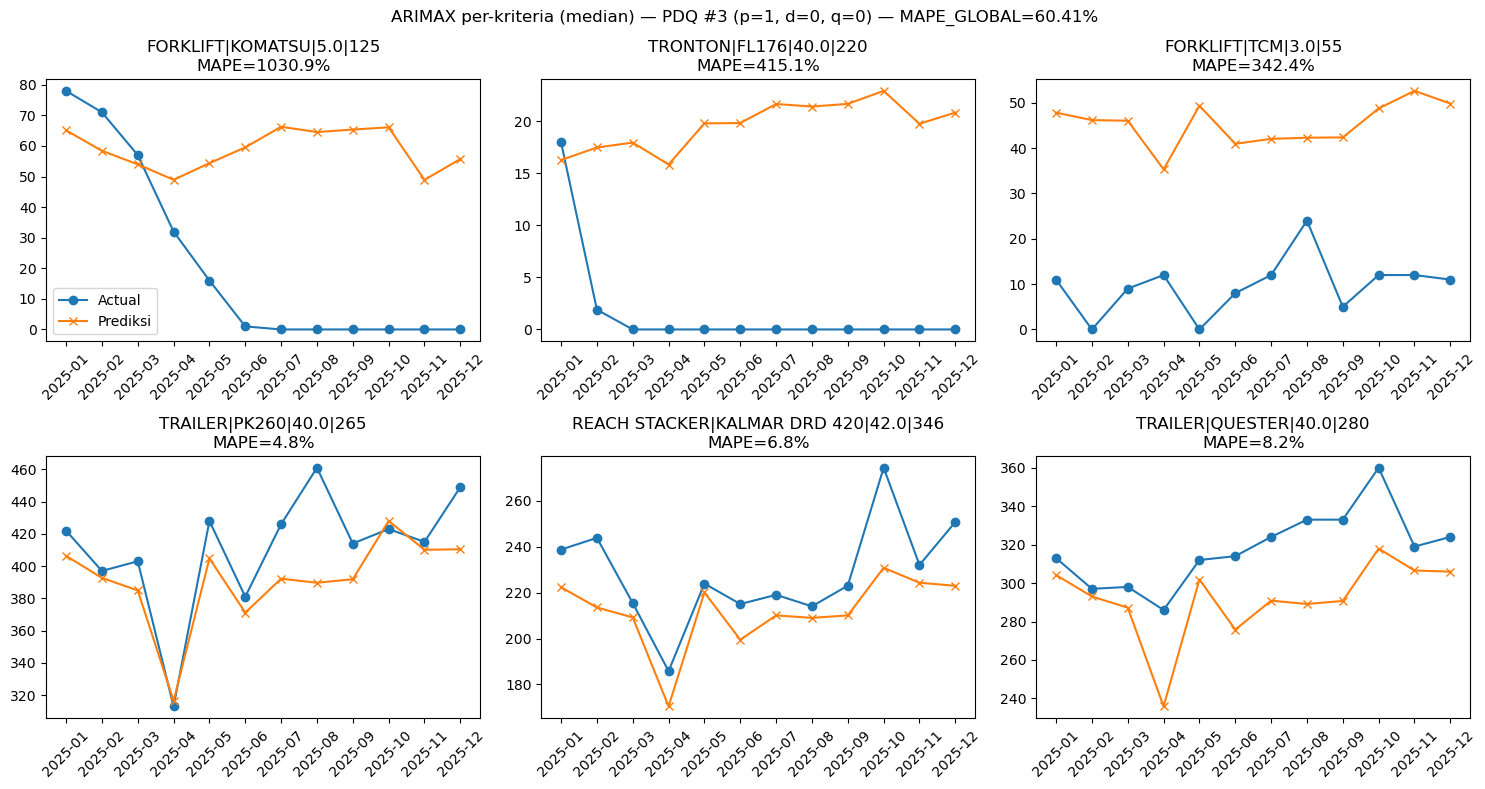

In [37]:
def refit_pdq_unit(order, unit_list, train_full, test_full):
    results, preds = [], []
    for unit in unit_list:
        tr_y = get_series(train_full, 'EQUIP NAME', unit)
        te_y = get_series(test_full, 'EQUIP NAME', unit, value_col='UTILITAS')
        tr_x = get_exog(train_full, 'EQUIP NAME', unit)
        te_x = get_exog(test_full, 'EQUIP NAME', unit)
        if len(tr_y) < 6 or len(te_y) == 0:
            continue
        try:
            model = pm.ARIMA(order=order, suppress_warnings=True)
            model.fit(tr_y, X=tr_x.values)
            pred = model.predict(n_periods=len(te_y), X=(tr_x if len(te_x) == 0 else te_x).values)
        except Exception:
            pred = None
        mape, rmse = eval_pred(te_y, pred)
        results.append({'EQUIP NAME': unit, 'MAPE': mape, 'RMSE': rmse})
        if pred is not None:
            for t, a, p in zip(te_y.index, te_y.values, np.array(pred)):
                preds.append({'EQUIP NAME': unit, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
    return pd.DataFrame(results), pd.DataFrame(preds)


def refit_pdq_kriteria(order, agg, kriteria_list, train_full, test_full):
    results, preds = [], []
    for k in kriteria_list:
        tr_y = get_series(train_full, 'KRITERIA_ID', k, agg=agg)
        te_y = get_series(test_full, 'KRITERIA_ID', k, agg=agg, value_col='UTILITAS')
        tr_x = get_exog(train_full, 'KRITERIA_ID', k)
        te_x = get_exog(test_full, 'KRITERIA_ID', k)
        if len(tr_y) < 6 or len(te_y) == 0:
            continue
        try:
            model = pm.ARIMA(order=order, suppress_warnings=True)
            model.fit(tr_y, X=tr_x.values)
            pred = model.predict(n_periods=len(te_y), X=te_x.values)
        except Exception:
            pred = None
        mape, rmse = eval_pred(te_y, pred)
        results.append({'KRITERIA_ID': k, 'MAPE': mape, 'RMSE': rmse})
        if pred is not None:
            for t, a, p in zip(te_y.index, te_y.values, np.array(pred)):
                preds.append({'KRITERIA_ID': k, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
    return pd.DataFrame(results), pd.DataFrame(preds)


# ── Per-unit: top-3 kombinasi PDQ ──
top3_unit = grid_results_unit.sort_values('MAPE_GLOBAL').head(3).reset_index(drop=True)
top3_unit.to_csv(OUT_DIR / '22a_top3_pdq_per_unit.csv', index=False)
print('Top-3 PDQ per-unit:')
print(top3_unit.to_string(index=False))

for rank, row in top3_unit.iterrows():
    order = (int(row['p']), int(row['d']), int(row['q']))
    results_df, preds_df = refit_pdq_unit(order, unit_list, train_full, test_full)
    title = (f"ARIMAX per-unit — PDQ #{rank + 1} (p={order[0]}, d={order[1]}, q={order[2]}) "
              f"— MAPE_GLOBAL={row['MAPE_GLOBAL']:.2f}%")
    fname = f"22a_plot_arimax_unit_pdq{rank + 1}_{order[0]}{order[1]}{order[2]}.png"
    plot_top_bottom_mape(results_df, preds_df, title, fname=fname)

# ── Per-kriteria: top-3 kombinasi PDQ, terpisah untuk mean & median ──
top3_kriteria_all = []
for agg in ['mean', 'median']:
    sub = (grid_results_kriteria[grid_results_kriteria['AGG'] == agg]
           .sort_values('MAPE_GLOBAL').head(3).reset_index(drop=True))
    top3_kriteria_all.append(sub)
    print(f'\nTop-3 PDQ per-kriteria ({agg}):')
    print(sub.to_string(index=False))

    for rank, row in sub.iterrows():
        order = (int(row['p']), int(row['d']), int(row['q']))
        results_df, preds_df = refit_pdq_kriteria(order, agg, kriteria_list, train_full, test_full)
        title = (f"ARIMAX per-kriteria ({agg}) — PDQ #{rank + 1} (p={order[0]}, d={order[1]}, q={order[2]}) "
                  f"— MAPE_GLOBAL={row['MAPE_GLOBAL']:.2f}%")
        fname = f"22b_plot_arimax_kriteria_{agg}_pdq{rank + 1}_{order[0]}{order[1]}{order[2]}.png"
        plot_top_bottom_mape(results_df, preds_df, title, unit_col='KRITERIA_ID', fname=fname)

pd.concat(top3_kriteria_all, ignore_index=True).to_csv(OUT_DIR / '22b_top3_pdq_per_kriteria.csv', index=False)

Top-3 GB per-unit:
 learning_rate  max_iter  max_depth  min_samples_leaf  MAPE_GLOBAL
          0.01       200        7.0                 5    45.764996
          0.01       200        5.0                 5    45.764996
          0.01       200        3.0                 5    45.764996


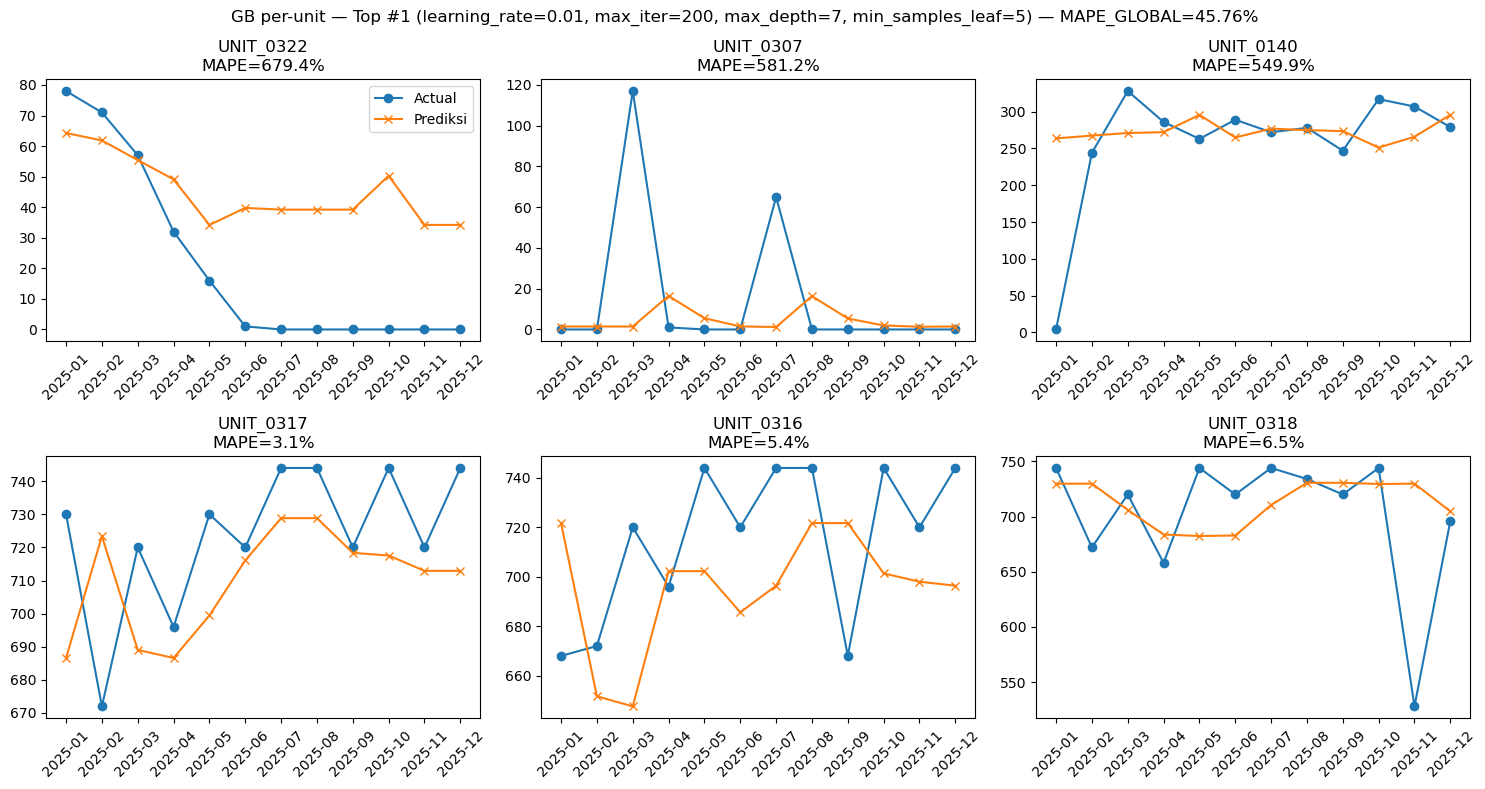

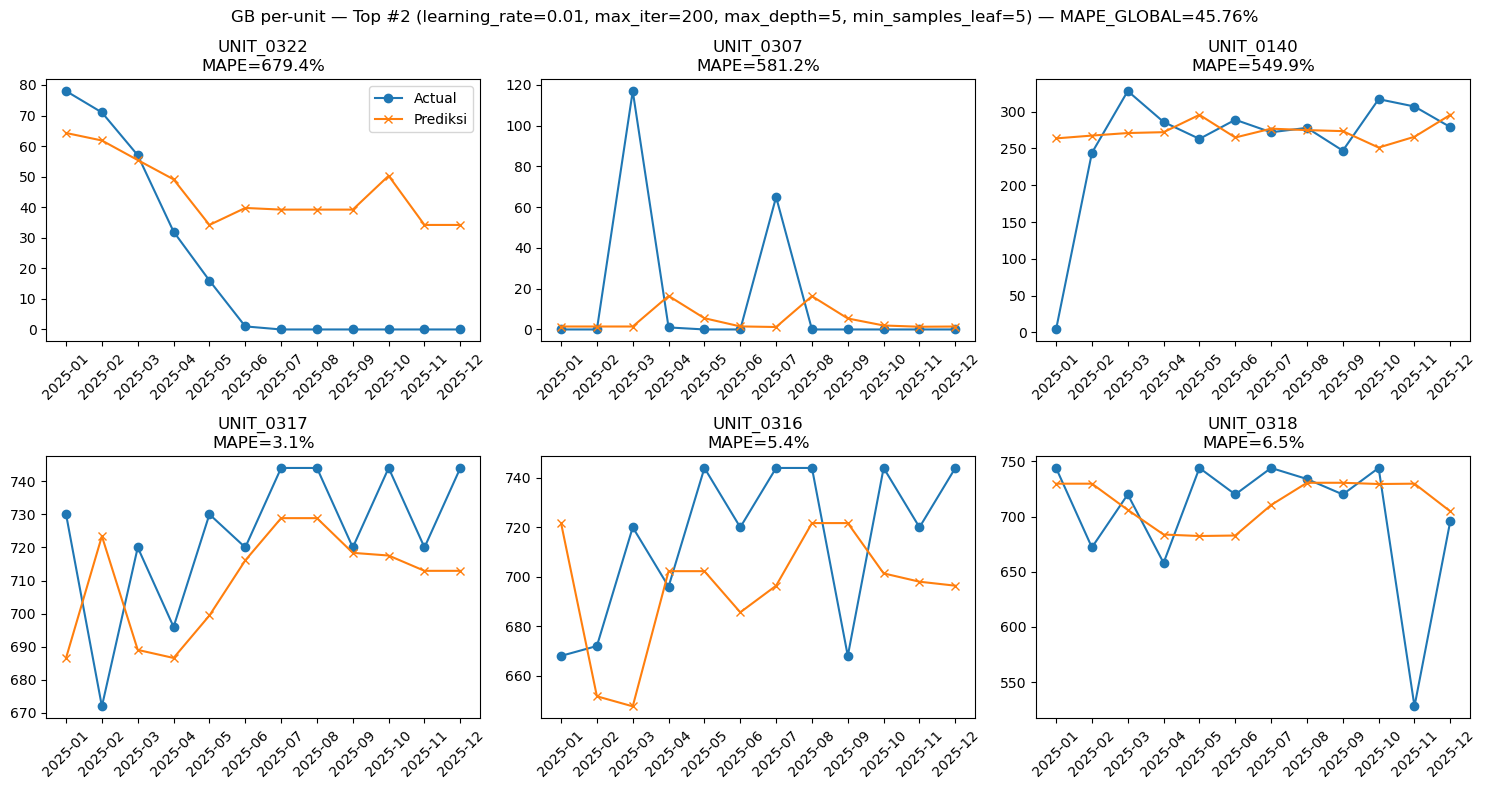

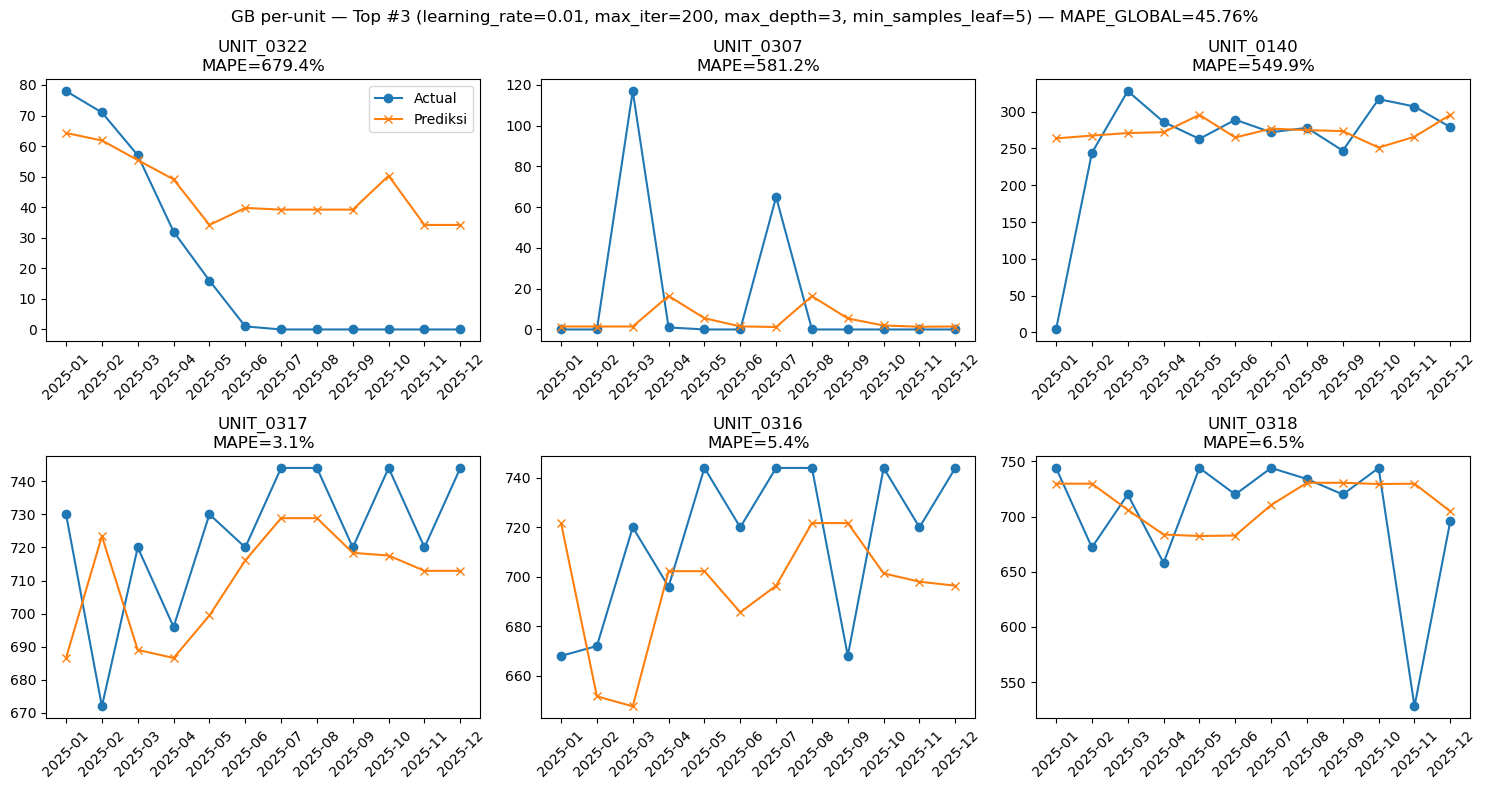


Top-3 GB per-kriteria:
 learning_rate  max_iter  max_depth  min_samples_leaf  MAPE_GLOBAL
          0.01       300        7.0                 5    44.329731
          0.01       300        5.0                 5    44.344560
          0.01       300        NaN                 5    44.369771


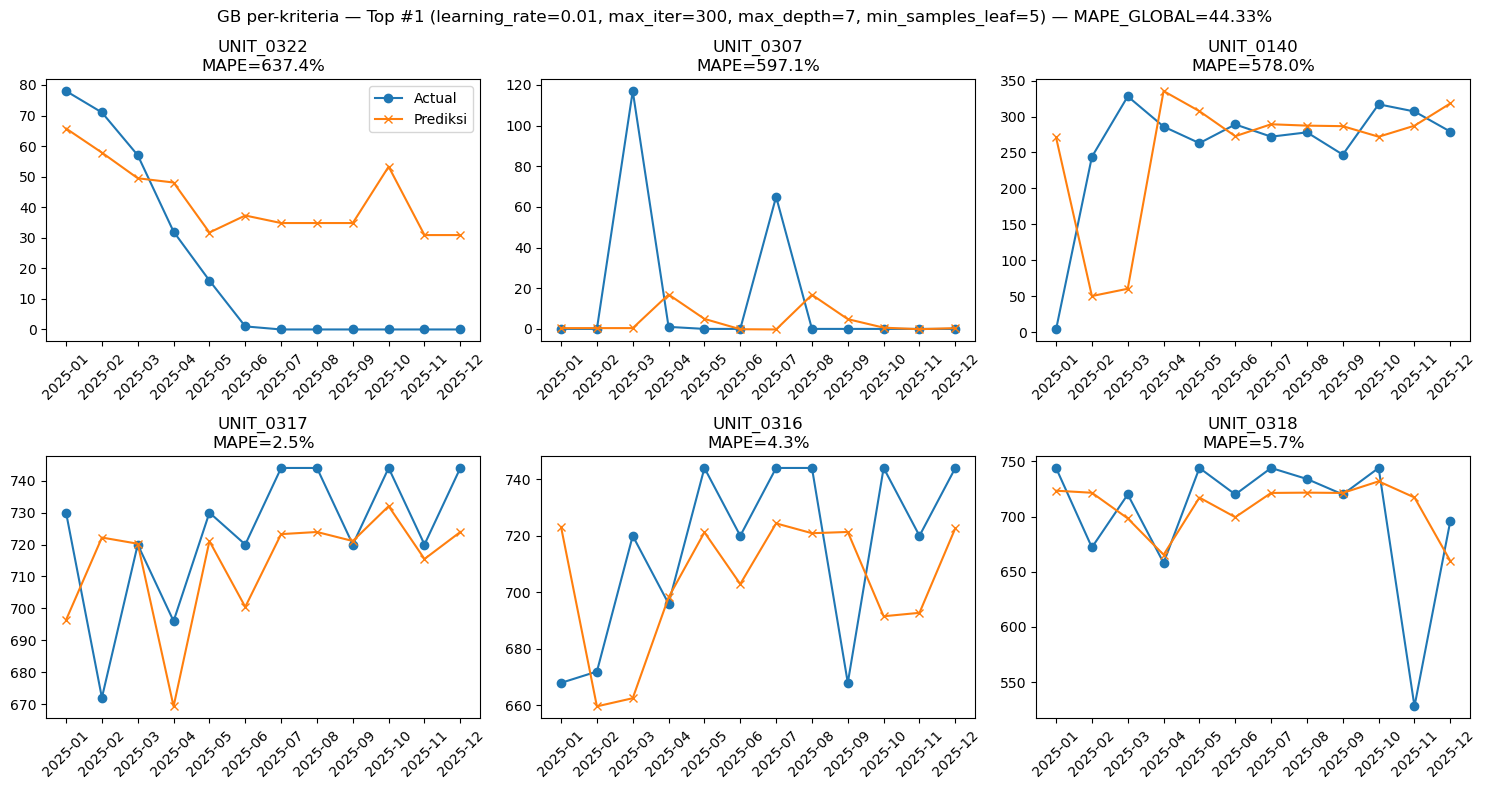

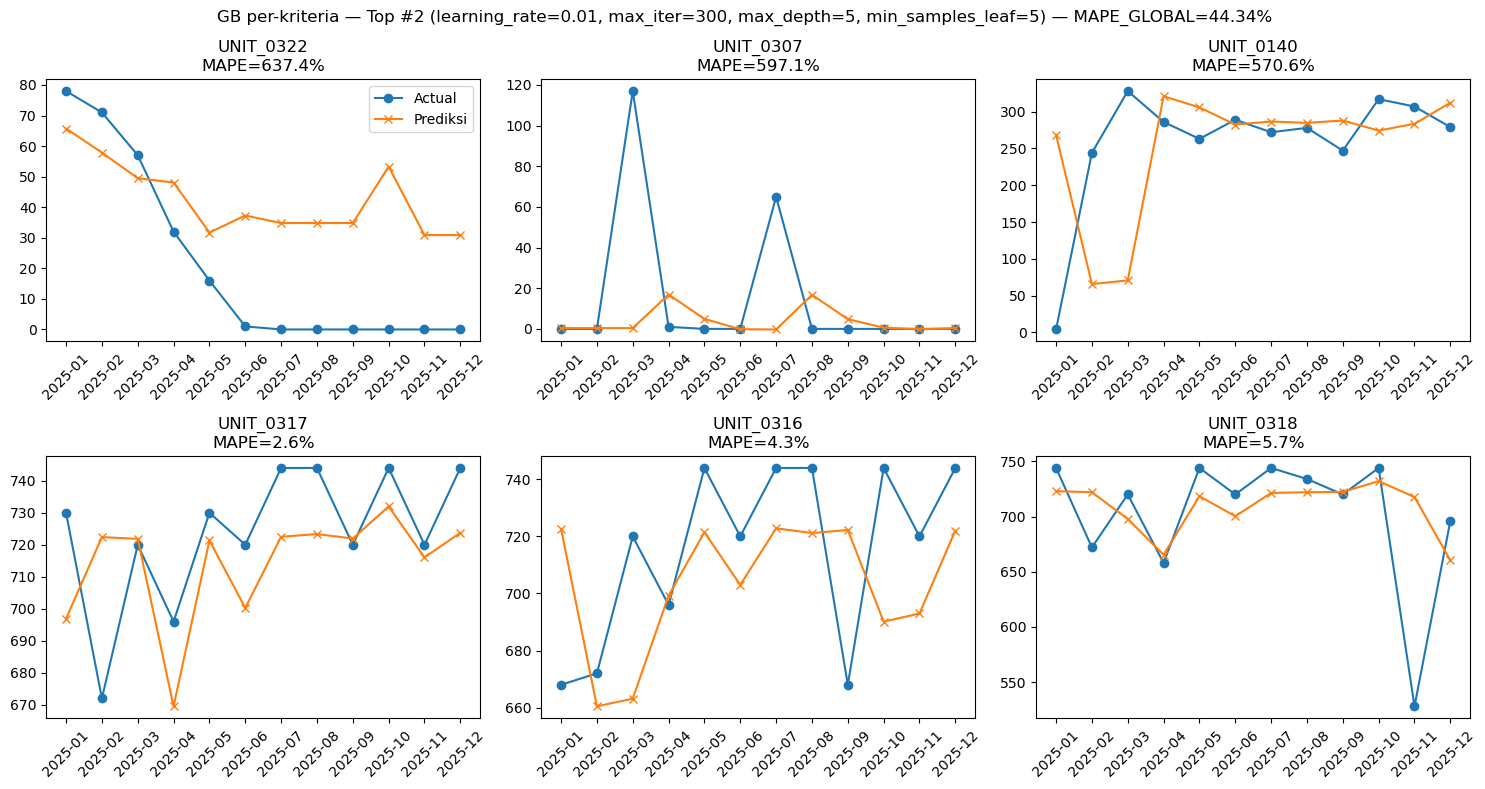

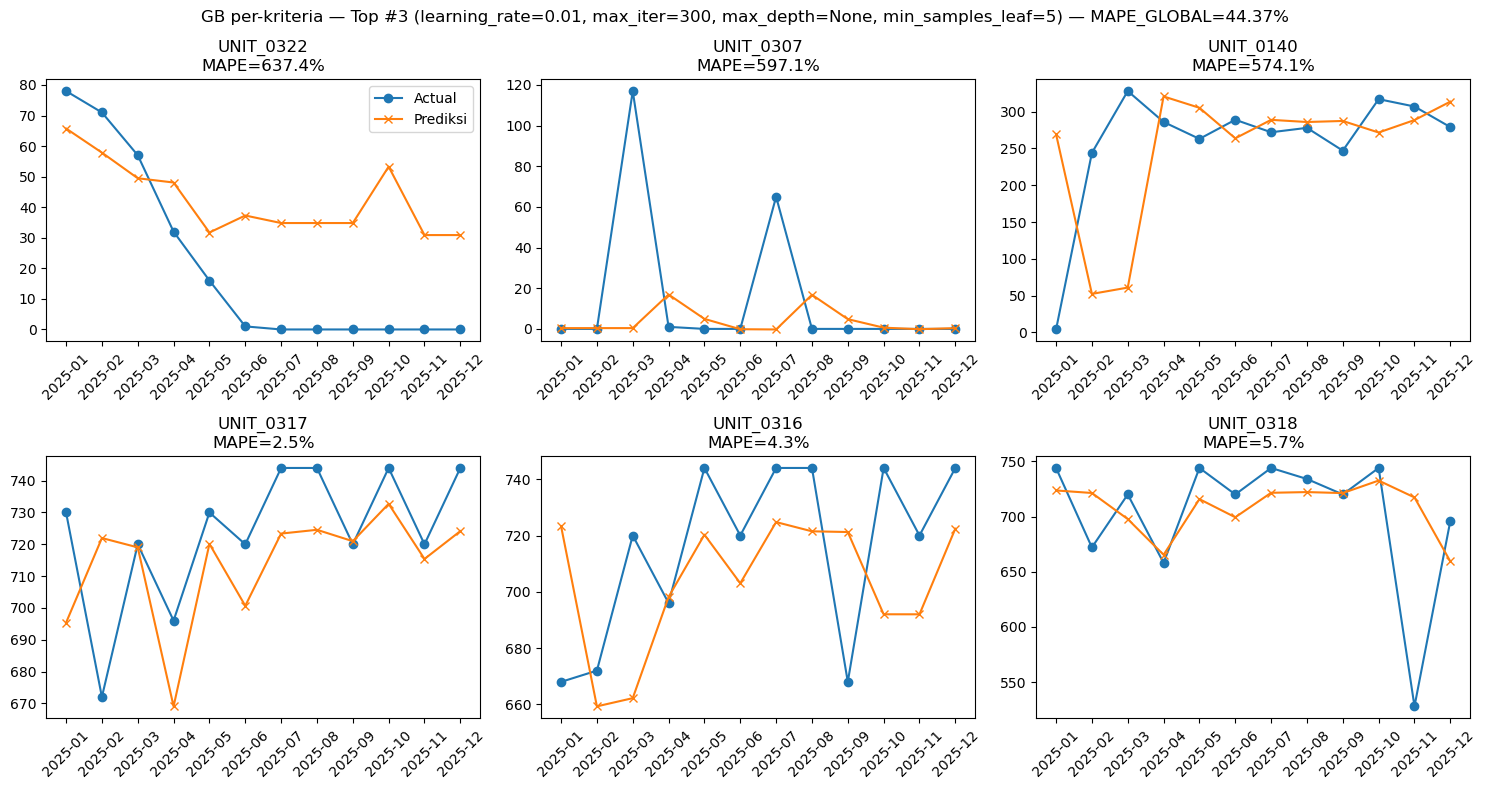


Top-3 LSTM per-unit:
 seq_len  units  epochs  MAPE_GLOBAL
       3     16      50    49.683834
       3     32      50    51.053403
       3     32      30    51.240239


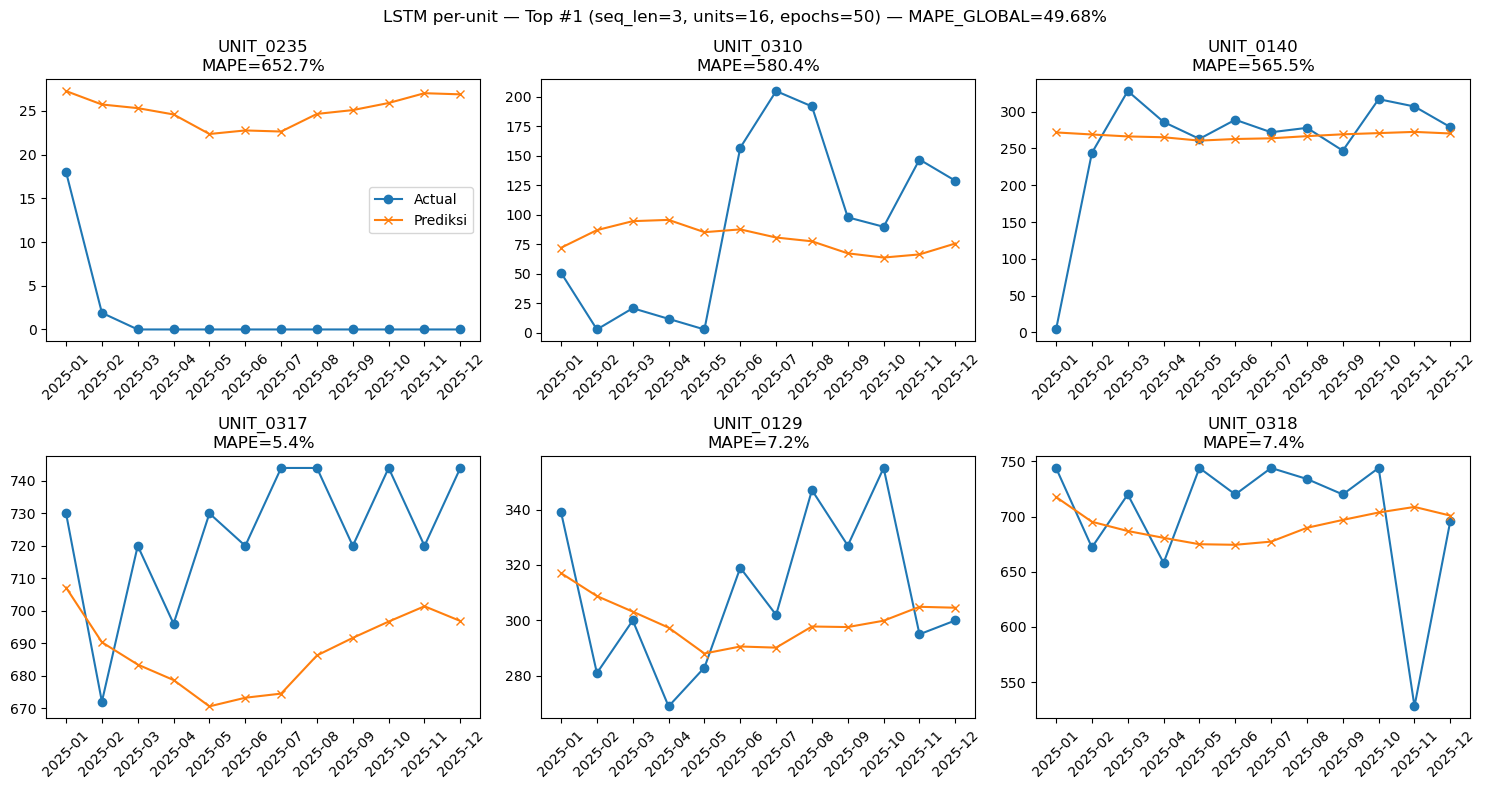

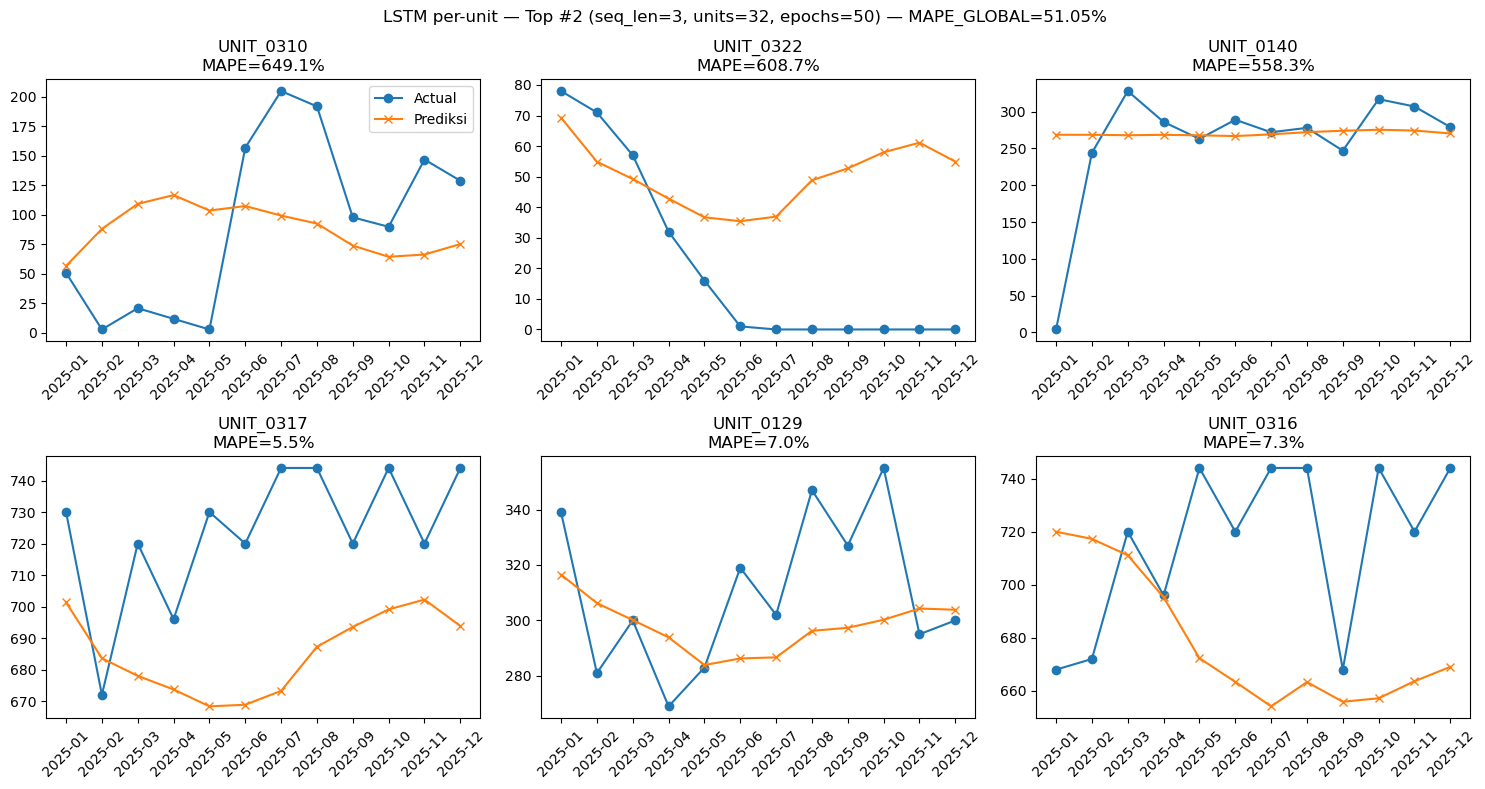

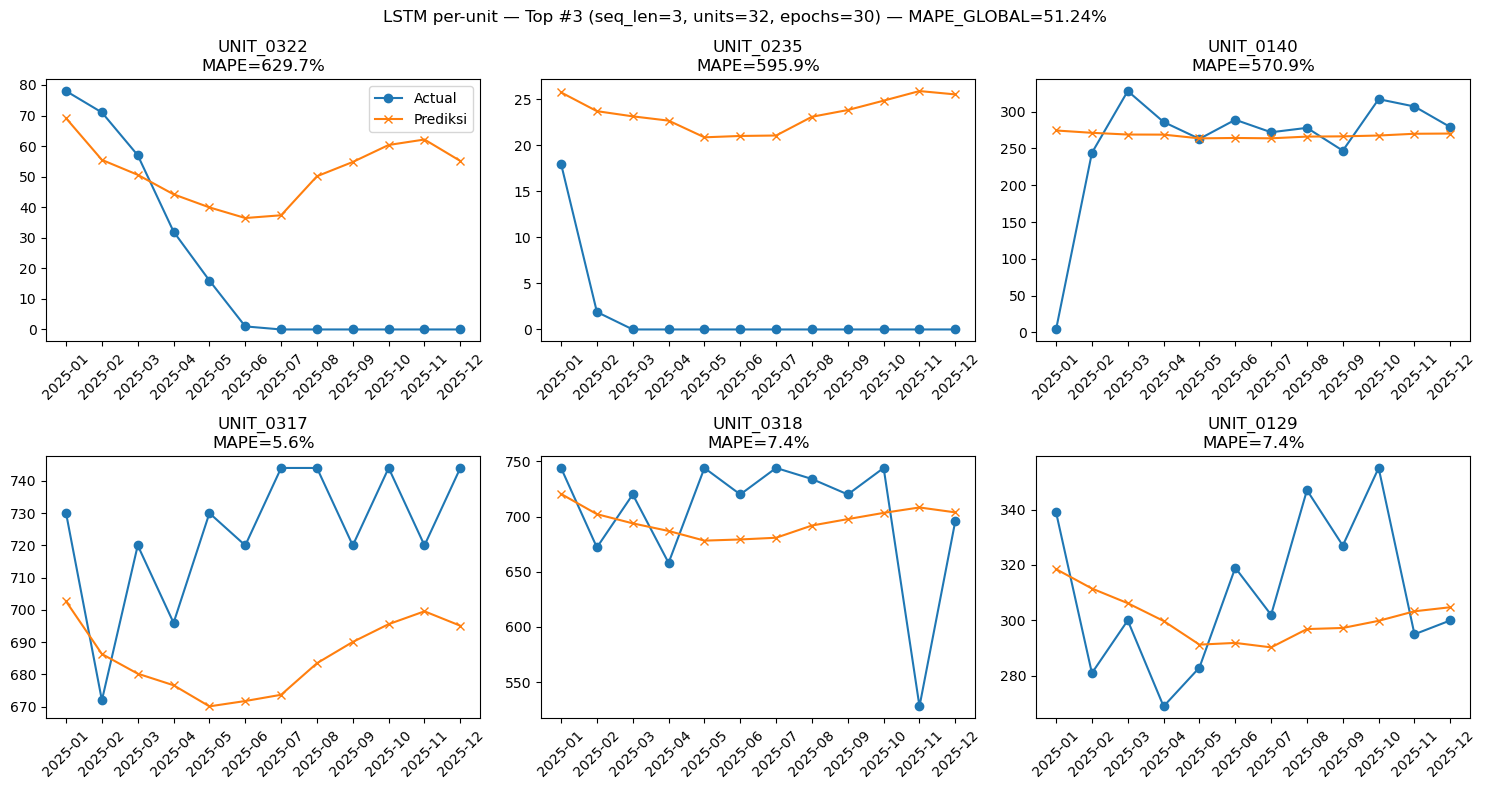


Top-3 LSTM per-kriteria:
 seq_len  units  epochs  MAPE_GLOBAL
       3     16      50    52.924459
       3     32      30    53.253143
       3     32      50    53.742624


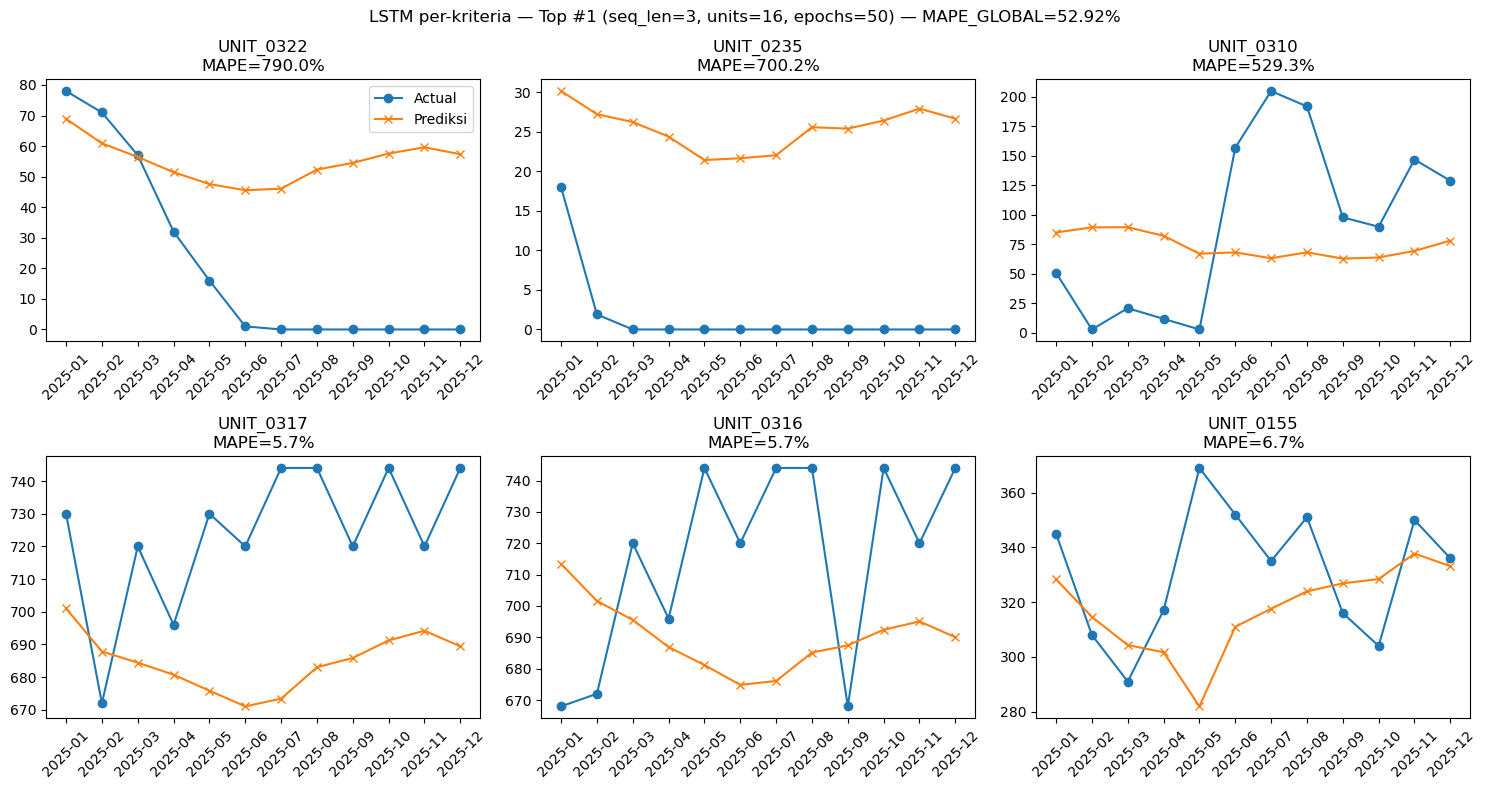

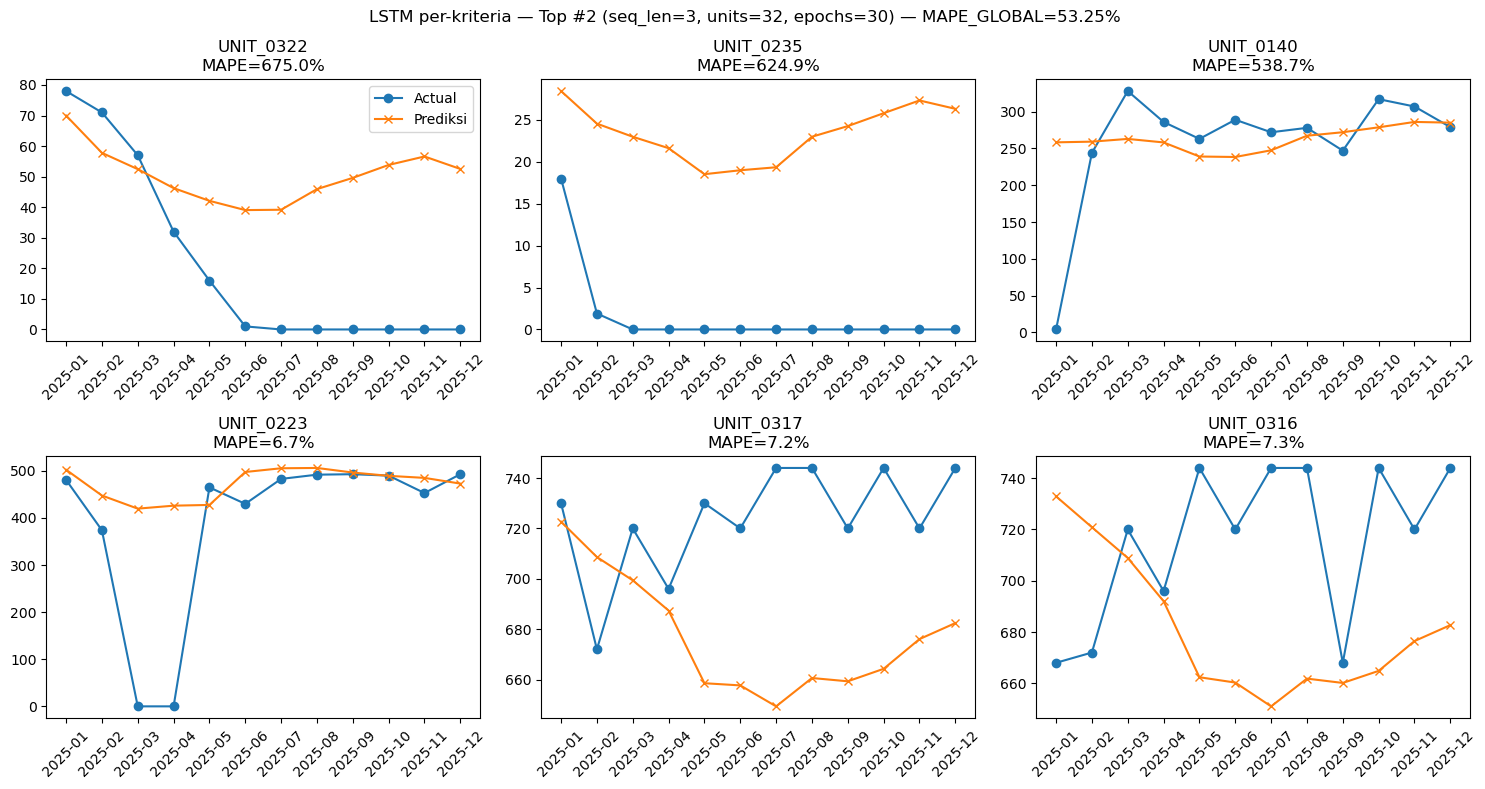

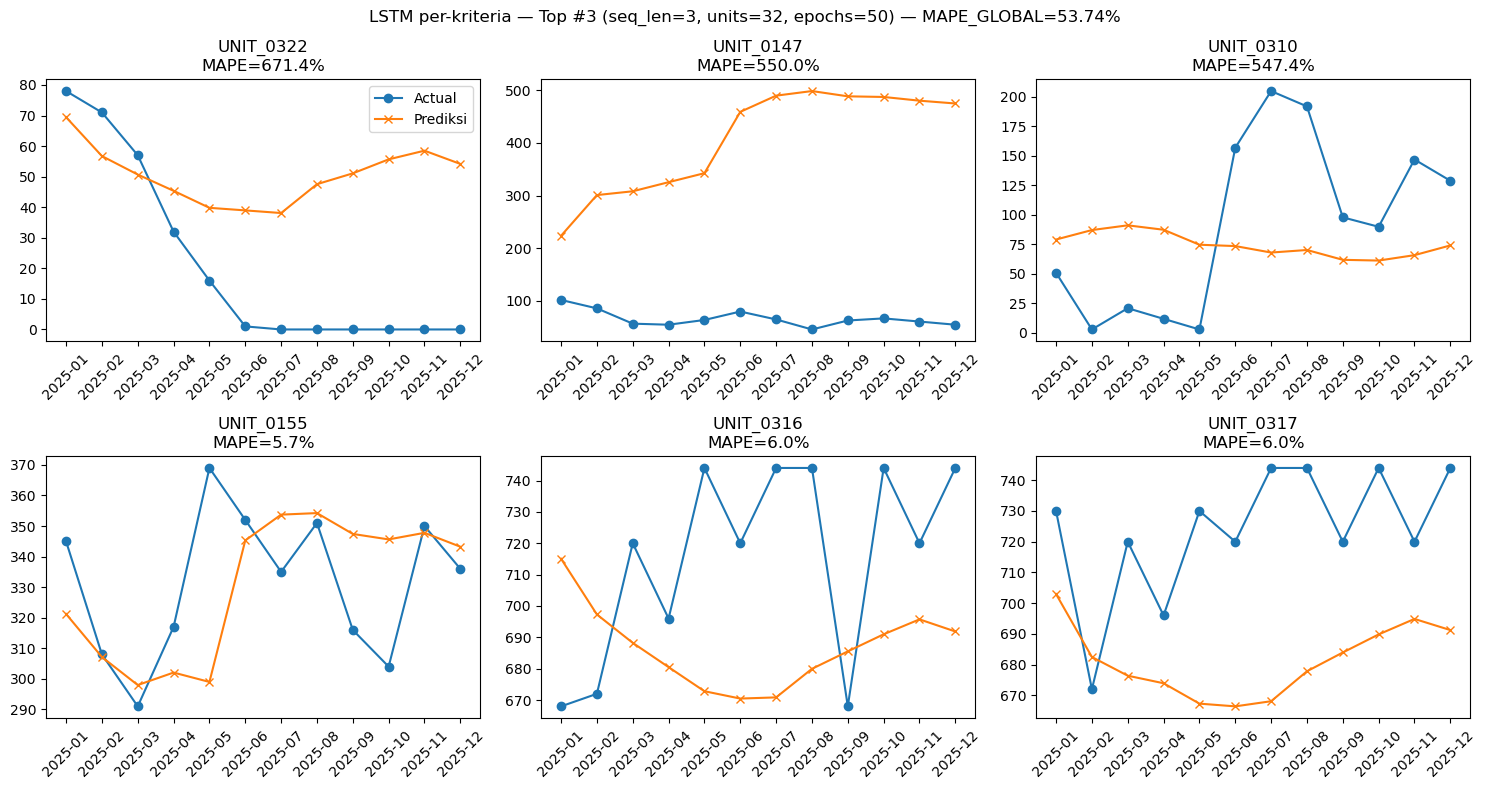

In [38]:
# GB & LSTM: refit top-3 hyperparameter terbaik + plot best/worst-3

def refit_gb_unit(params, train_lag, test_lag):
    results, preds = [], []
    for unit, g_train in train_lag.groupby('EQUIP NAME'):
        g_train = g_train.dropna(subset=feat_cols + ['UTILITAS_SMOOTH'])
        g_test = test_lag[test_lag['EQUIP NAME'] == unit].dropna(subset=feat_cols)
        if len(g_train) < 6 or len(g_test) == 0:
            continue
        model = HistGradientBoostingRegressor(random_state=42, **params)
        model.fit(g_train[feat_cols], g_train['UTILITAS_SMOOTH'])
        pred = model.predict(g_test[feat_cols])
        actual = g_test.set_index('TAHUN_BULAN')['UTILITAS'].reindex(g_test['TAHUN_BULAN'])
        mape, rmse = eval_pred(actual.values, pred)
        results.append({'EQUIP NAME': unit, 'MAPE': mape, 'RMSE': rmse})
        for t, a, p in zip(g_test['TAHUN_BULAN'].values, actual.values, pred):
            preds.append({'EQUIP NAME': unit, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
    return pd.DataFrame(results), pd.DataFrame(preds)


def refit_gb_kriteria(params, train_lag, test_lag, kriteria_list):
    results, preds = [], []
    for k in kriteria_list:
        g_train = train_lag[train_lag['KRITERIA_ID'] == k].dropna(subset=feat_cols + ['UTILITAS_SMOOTH'])
        if len(g_train) < 6:
            continue
        model = HistGradientBoostingRegressor(random_state=42, **params)
        model.fit(g_train[feat_cols], g_train['UTILITAS_SMOOTH'])
        units_in_k = train_lag[train_lag['KRITERIA_ID'] == k]['EQUIP NAME'].unique()
        for unit in units_in_k:
            g_test = test_lag[test_lag['EQUIP NAME'] == unit].dropna(subset=feat_cols)
            if len(g_test) == 0:
                continue
            pred = model.predict(g_test[feat_cols])
            actual = g_test.set_index('TAHUN_BULAN')['UTILITAS'].reindex(g_test['TAHUN_BULAN'])
            mape, rmse = eval_pred(actual.values, pred)
            results.append({'EQUIP NAME': unit, 'KRITERIA_ID': k, 'MAPE': mape, 'RMSE': rmse})
            for t, a, p in zip(g_test['TAHUN_BULAN'].values, actual.values, pred):
                preds.append({'EQUIP NAME': unit, 'KRITERIA_ID': k, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
    return pd.DataFrame(results), pd.DataFrame(preds)


def refit_lstm_unit(seq_len, units, epochs, train_full, test_full, unit_list):
    def build_lstm_custom(n_features):
        m = keras.Sequential([
            keras.layers.LSTM(units, input_shape=(seq_len, n_features)),
            keras.layers.Dense(16, activation='relu'),
            keras.layers.Dense(1),
        ])
        m.compile(optimizer='adam', loss='mse')
        return m

    results, preds = [], []
    for unit in unit_list:
        tr_y = get_series(train_full, 'EQUIP NAME', unit)
        te_y = get_series(test_full, 'EQUIP NAME', unit, value_col='UTILITAS')
        tr_x = get_exog(train_full, 'EQUIP NAME', unit)
        te_x = get_exog(test_full, 'EQUIP NAME', unit)
        if len(tr_y) < seq_len + 6 or len(te_y) == 0:
            continue
        feat = pd.concat([tr_y.rename('y'), tr_x], axis=1).dropna()
        if len(feat) < seq_len + 3:
            continue
        scaler = MinMaxScaler()
        scaled = scaler.fit_transform(feat.values)
        X, y = make_sequences(scaled, seq_len)
        if len(X) < 3:
            continue
        model = build_lstm_custom(scaled.shape[1])
        model.fit(X, y, epochs=epochs, batch_size=8, verbose=0)

        window = scaled[-seq_len:].copy()
        exog_future = te_x.values
        exog_future_scaled = scaler.transform(
            np.hstack([np.zeros((len(exog_future), 1)), exog_future])
        )[:, 1:]

        preds_scaled = []
        for i in range(len(te_y)):
            x_in = window[-seq_len:].reshape(1, seq_len, scaled.shape[1])
            yhat = model.predict(x_in, verbose=0)[0, 0]
            preds_scaled.append(yhat)
            next_row = np.hstack([[yhat], exog_future_scaled[i]])
            window = np.vstack([window, next_row])

        dummy = np.zeros((len(preds_scaled), scaled.shape[1]))
        dummy[:, 0] = preds_scaled
        pred_actual = scaler.inverse_transform(dummy)[:, 0]

        mape, rmse = eval_pred(te_y.values, pred_actual)
        results.append({'EQUIP NAME': unit, 'MAPE': mape, 'RMSE': rmse})
        for t, a, p in zip(te_y.index, te_y.values, pred_actual):
            preds.append({'EQUIP NAME': unit, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
    return pd.DataFrame(results), pd.DataFrame(preds)


def refit_lstm_kriteria(seq_len, units, epochs, train_full, test_full, kriteria_list):
    def build_lstm_custom(n_features):
        m = keras.Sequential([
            keras.layers.LSTM(units, input_shape=(seq_len, n_features)),
            keras.layers.Dense(16, activation='relu'),
            keras.layers.Dense(1),
        ])
        m.compile(optimizer='adam', loss='mse')
        return m

    results, preds = [], []
    for k in kriteria_list:
        train_sub = train_full[train_full['KRITERIA_ID'] == k]
        units_in_k = train_sub['EQUIP NAME'].dropna().unique().tolist()
        if not units_in_k:
            continue

        pooled_feat = []
        for u in units_in_k:
            s_y = get_series(train_full, 'EQUIP NAME', u)
            s_x = get_exog(train_full, 'EQUIP NAME', u)
            feat = pd.concat([s_y.rename('y'), s_x], axis=1).dropna()
            if len(feat) >= seq_len + 1:
                pooled_feat.append(feat)
        if not pooled_feat:
            continue

        combined = pd.concat(pooled_feat, axis=0)
        scaler = MinMaxScaler()
        scaler.fit(combined.values)

        all_X, all_y = [], []
        for feat in pooled_feat:
            scaled = scaler.transform(feat.values)
            X, y = make_sequences(scaled, seq_len)
            if len(X) > 0:
                all_X.append(X)
                all_y.append(y)
        if not all_X:
            continue
        X_train = np.concatenate(all_X)
        y_train = np.concatenate(all_y)
        if len(X_train) < 5:
            continue

        model = build_lstm_custom(X_train.shape[2])
        model.fit(X_train, y_train, epochs=epochs, batch_size=16, verbose=0)

        for u in units_in_k:
            tr_y = get_series(train_full, 'EQUIP NAME', u)
            te_y = get_series(test_full, 'EQUIP NAME', u, value_col='UTILITAS')
            tr_x = get_exog(train_full, 'EQUIP NAME', u)
            te_x = get_exog(test_full, 'EQUIP NAME', u)
            if len(tr_y) < seq_len or len(te_y) == 0:
                continue
            feat = pd.concat([tr_y.rename('y'), tr_x], axis=1).dropna()
            if len(feat) < seq_len:
                continue

            scaled = scaler.transform(feat.values)
            window = scaled[-seq_len:].copy()
            exog_future = te_x.values
            exog_future_scaled = scaler.transform(
                np.hstack([np.zeros((len(exog_future), 1)), exog_future])
            )[:, 1:]

            preds_scaled = []
            for i in range(len(te_y)):
                x_in = window[-seq_len:].reshape(1, seq_len, scaled.shape[1])
                yhat = model.predict(x_in, verbose=0)[0, 0]
                preds_scaled.append(yhat)
                next_row = np.hstack([[yhat], exog_future_scaled[i]])
                window = np.vstack([window, next_row])

            dummy = np.zeros((len(preds_scaled), scaled.shape[1]))
            dummy[:, 0] = preds_scaled
            pred_actual = scaler.inverse_transform(dummy)[:, 0]

            mape, rmse = eval_pred(te_y.values, pred_actual)
            results.append({'EQUIP NAME': u, 'KRITERIA_ID': k, 'MAPE': mape, 'RMSE': rmse})
            for t, a, p in zip(te_y.index, te_y.values, pred_actual):
                preds.append({'EQUIP NAME': u, 'KRITERIA_ID': k, 'TAHUN_BULAN': t, 'ACTUAL': a, 'PRED': p})
    return pd.DataFrame(results), pd.DataFrame(preds)


# GB per-unit: top-3
top3_gb_unit = gb_tuning_df.head(3).reset_index(drop=True)
top3_gb_unit.to_csv(OUT_DIR / '23a_top3_params_gb_unit.csv', index=False)
print('Top-3 GB per-unit:')
print(top3_gb_unit.to_string(index=False))

for rank, row in top3_gb_unit.iterrows():
    params = {k: row[k] for k in gb_param_grid.keys()}
    params['max_depth'] = int(params['max_depth']) if pd.notna(params['max_depth']) else None
    params['max_iter'] = int(params['max_iter'])
    params['min_samples_leaf'] = int(params['min_samples_leaf'])
    results_df, preds_df = refit_gb_unit(params, train_lag, test_lag)
    pstr = ', '.join(f'{k}={v}' for k, v in params.items())
    title = f"GB per-unit — Top #{rank + 1} ({pstr}) — MAPE_GLOBAL={row['MAPE_GLOBAL']:.2f}%"
    fname = f"23a_plot_gb_unit_top{rank + 1}.png"
    plot_top_bottom_mape(results_df, preds_df, title, fname=fname)

# ── GB per-kriteria: top-3 ──
top3_gb_kriteria = gb_tuning_kriteria_df.head(3).reset_index(drop=True)
top3_gb_kriteria.to_csv(OUT_DIR / '23b_top3_params_gb_kriteria.csv', index=False)
print('\nTop-3 GB per-kriteria:')
print(top3_gb_kriteria.to_string(index=False))

for rank, row in top3_gb_kriteria.iterrows():
    params = {k: row[k] for k in gb_param_grid.keys()}
    params['max_depth'] = int(params['max_depth']) if pd.notna(params['max_depth']) else None
    params['max_iter'] = int(params['max_iter'])
    params['min_samples_leaf'] = int(params['min_samples_leaf'])
    results_df, preds_df = refit_gb_kriteria(params, train_lag, test_lag, kriteria_list)
    pstr = ', '.join(f'{k}={v}' for k, v in params.items())
    title = f"GB per-kriteria — Top #{rank + 1} ({pstr}) — MAPE_GLOBAL={row['MAPE_GLOBAL']:.2f}%"
    fname = f"23b_plot_gb_kriteria_top{rank + 1}.png"
    plot_top_bottom_mape(results_df, preds_df, title, fname=fname)

# LSTM per-unit: top-3 (retrain 3x dari config pemenang, LAMBAT)
top3_lstm_unit = lstm_tuning_df.head(3).reset_index(drop=True)
top3_lstm_unit.to_csv(OUT_DIR / '23c_top3_params_lstm_unit.csv', index=False)
print('\nTop-3 LSTM per-unit:')
print(top3_lstm_unit.to_string(index=False))

for rank, row in top3_lstm_unit.iterrows():
    seq_len, units, epochs = int(row['seq_len']), int(row['units']), int(row['epochs'])
    results_df, preds_df = refit_lstm_unit(seq_len, units, epochs, train_full, test_full, unit_list)
    title = (f"LSTM per-unit — Top #{rank + 1} (seq_len={seq_len}, units={units}, epochs={epochs}) "
              f"— MAPE_GLOBAL={row['MAPE_GLOBAL']:.2f}%")
    fname = f"23c_plot_lstm_unit_top{rank + 1}.png"
    plot_top_bottom_mape(results_df, preds_df, title, fname=fname)

# LSTM per-kriteria: top-3 (retrain 3x, LAMBAT)
top3_lstm_kriteria = lstm_tuning_kriteria_df.head(3).reset_index(drop=True)
top3_lstm_kriteria.to_csv(OUT_DIR / '23d_top3_params_lstm_kriteria.csv', index=False)
print('\nTop-3 LSTM per-kriteria:')
print(top3_lstm_kriteria.to_string(index=False))

for rank, row in top3_lstm_kriteria.iterrows():
    seq_len, units, epochs = int(row['seq_len']), int(row['units']), int(row['epochs'])
    results_df, preds_df = refit_lstm_kriteria(seq_len, units, epochs, train_full, test_full, kriteria_list)
    title = (f"LSTM per-kriteria — Top #{rank + 1} (seq_len={seq_len}, units={units}, epochs={epochs}) "
              f"— MAPE_GLOBAL={row['MAPE_GLOBAL']:.2f}%")
    fname = f"23d_plot_lstm_kriteria_top{rank + 1}.png"
    plot_top_bottom_mape(results_df, preds_df, title, unit_col='EQUIP NAME', fname=fname)


            MODEL            PENDEKATAN  MAPE_BASELINE (auto-ARIMA / default)  MAPE_TUNED (grid search terbaik)                    PARAMETER_TERBAIK  SELISIH_MAPE (poin persen)  PERBAIKAN (%) LEBIH_BAIK
Gradient Boosting per-kriteria (pooled)                                 49.11                             44.33 lr=0.01, iter=300, depth=7.0, leaf=5                        4.78           9.74      TUNED
Gradient Boosting              per-unit                                 54.86                             45.76 lr=0.01, iter=200, depth=7.0, leaf=5                        9.09          16.57      TUNED
           ARIMAX              per-unit                                 51.04                             46.21                          PDQ=(1,0,0)                        4.83           9.47      TUNED
             LSTM              per-unit                                 59.46                             49.68       seq_len=3, units=16, epochs=50                        9.77          16

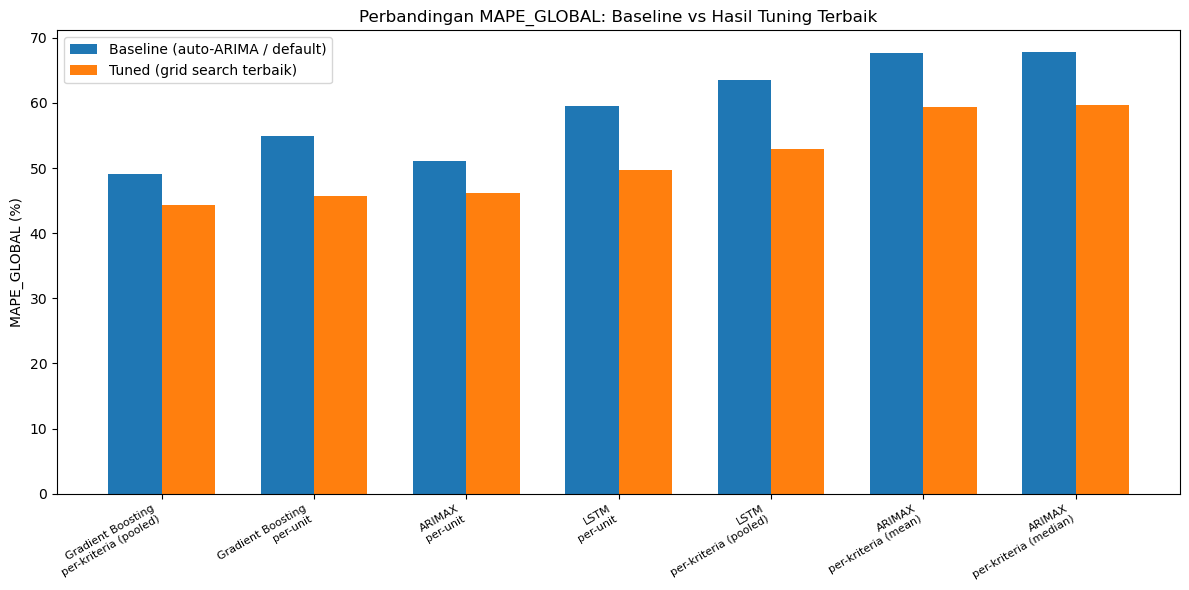

In [39]:
# Perbandingan BASELINE (auto-ARIMA / default GB / default LSTM) vs HASIL TUNING TERBAIK

# 'summary' (dari Cell 20) = baseline: ARIMAX pakai auto_arima, GB & LSTM pakai parameter default.
# Kita ambil ulang di sini biar cell ini bisa berdiri sendiri kalau di-run terpisah.
baseline_map = {
    ('ARIMAX', 'per-unit'): global_mape(arimax_unit_preds_df),
    ('ARIMAX', 'per-kriteria (mean)'): global_mape(arimax_kriteria_preds_df[arimax_kriteria_preds_df['AGG'] == 'mean']),
    ('ARIMAX', 'per-kriteria (median)'): global_mape(arimax_kriteria_preds_df[arimax_kriteria_preds_df['AGG'] == 'median']),
    ('Gradient Boosting', 'per-unit'): global_mape(gb_unit_preds_df),
    ('Gradient Boosting', 'per-kriteria (pooled)'): global_mape(gb_kriteria_preds_df),
    ('LSTM', 'per-unit'): global_mape(lstm_unit_preds_df),
    ('LSTM', 'per-kriteria (pooled)'): global_mape(lstm_kriteria_preds_df),
}

# Hasil tuning terbaik (top-1 dari tiap grid search, sudah tersimpan di memory / bisa dibaca ulang dari CSV checkpoint)
best_arimax_unit = grid_results_unit.sort_values('MAPE_GLOBAL').iloc[0]
best_arimax_kriteria_mean = grid_results_kriteria[grid_results_kriteria['AGG'] == 'mean'].sort_values('MAPE_GLOBAL').iloc[0]
best_arimax_kriteria_median = grid_results_kriteria[grid_results_kriteria['AGG'] == 'median'].sort_values('MAPE_GLOBAL').iloc[0]
best_gb_unit = gb_tuning_df.iloc[0]
best_gb_kriteria = gb_tuning_kriteria_df.iloc[0]
best_lstm_unit = lstm_tuning_df.iloc[0]
best_lstm_kriteria = lstm_tuning_kriteria_df.iloc[0]

tuned_map = {
    ('ARIMAX', 'per-unit'): (best_arimax_unit['MAPE_GLOBAL'],
        f"PDQ=({int(best_arimax_unit['p'])},{int(best_arimax_unit['d'])},{int(best_arimax_unit['q'])})"),
    ('ARIMAX', 'per-kriteria (mean)'): (best_arimax_kriteria_mean['MAPE_GLOBAL'],
        f"PDQ=({int(best_arimax_kriteria_mean['p'])},{int(best_arimax_kriteria_mean['d'])},{int(best_arimax_kriteria_mean['q'])})"),
    ('ARIMAX', 'per-kriteria (median)'): (best_arimax_kriteria_median['MAPE_GLOBAL'],
        f"PDQ=({int(best_arimax_kriteria_median['p'])},{int(best_arimax_kriteria_median['d'])},{int(best_arimax_kriteria_median['q'])})"),
    ('Gradient Boosting', 'per-unit'): (best_gb_unit['MAPE_GLOBAL'],
        f"lr={best_gb_unit['learning_rate']}, iter={int(best_gb_unit['max_iter'])}, "
        f"depth={best_gb_unit['max_depth']}, leaf={int(best_gb_unit['min_samples_leaf'])}"),
    ('Gradient Boosting', 'per-kriteria (pooled)'): (best_gb_kriteria['MAPE_GLOBAL'],
        f"lr={best_gb_kriteria['learning_rate']}, iter={int(best_gb_kriteria['max_iter'])}, "
        f"depth={best_gb_kriteria['max_depth']}, leaf={int(best_gb_kriteria['min_samples_leaf'])}"),
    ('LSTM', 'per-unit'): (best_lstm_unit['MAPE_GLOBAL'],
        f"seq_len={int(best_lstm_unit['seq_len'])}, units={int(best_lstm_unit['units'])}, epochs={int(best_lstm_unit['epochs'])}"),
    ('LSTM', 'per-kriteria (pooled)'): (best_lstm_kriteria['MAPE_GLOBAL'],
        f"seq_len={int(best_lstm_kriteria['seq_len'])}, units={int(best_lstm_kriteria['units'])}, epochs={int(best_lstm_kriteria['epochs'])}"),
}

rows = []
for key in baseline_map:
    model, pendekatan = key
    mape_baseline = baseline_map[key]
    mape_tuned, param_tuned = tuned_map[key]
    selisih = mape_baseline - mape_tuned  # positif = tuning lebih baik (MAPE turun)
    persen_perbaikan = (selisih / mape_baseline * 100) if mape_baseline else np.nan
    rows.append({
        'MODEL': model,
        'PENDEKATAN': pendekatan,
        'MAPE_BASELINE (auto-ARIMA / default)': round(mape_baseline, 2),
        'MAPE_TUNED (grid search terbaik)': round(mape_tuned, 2),
        'PARAMETER_TERBAIK': param_tuned,
        'SELISIH_MAPE (poin persen)': round(selisih, 2),
        'PERBAIKAN (%)': round(persen_perbaikan, 2),
        'LEBIH_BAIK': 'TUNED' if selisih > 0 else ('BASELINE' if selisih < 0 else 'SAMA'),
    })

comparison_df = pd.DataFrame(rows).sort_values('MAPE_TUNED (grid search terbaik)').reset_index(drop=True)
comparison_df.to_csv(OUT_DIR / '24_perbandingan_baseline_vs_tuned.csv', index=False)
print(comparison_df.to_string(index=False))

n_tuned_better = (comparison_df['LEBIH_BAIK'] == 'TUNED').sum()
n_baseline_better = (comparison_df['LEBIH_BAIK'] == 'BASELINE').sum()
print(f"\nTuning lebih baik di {n_tuned_better}/{len(comparison_df)} kombinasi model-pendekatan; "
      f"baseline lebih baik di {n_baseline_better}/{len(comparison_df)}.")

# Plot bar chart perbandingan
fig, ax = plt.subplots(figsize=(12, 6))
labels = [f"{r['MODEL']}\n{r['PENDEKATAN']}" for _, r in comparison_df.iterrows()]
x = np.arange(len(labels))
width = 0.35

ax.bar(x - width / 2, comparison_df['MAPE_BASELINE (auto-ARIMA / default)'], width, label='Baseline (auto-ARIMA / default)')
ax.bar(x + width / 2, comparison_df['MAPE_TUNED (grid search terbaik)'], width, label='Tuned (grid search terbaik)')

ax.set_ylabel('MAPE_GLOBAL (%)')
ax.set_title('Perbandingan MAPE_GLOBAL: Baseline vs Hasil Tuning Terbaik')
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=8)
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / '24_plot_perbandingan_baseline_vs_tuned.png', dpi=150)
plt.show()